# Red and White Wine Quality Modelling

This notebook compares six established regression methods:
1.   Linear Regression
2.   Decision Tree
3.   Random Forest
4.   MLP
5.   Gradient Boosting
6.   KNN Baseline

 **XGBoost** is retained as a supplementary exploratory cross-check.

Each section compares red and white wine using separate calculations and combined results. Section 9 presents the complete model comparison.

## Research basis
Cortez, P., Cerdeira, A., Almeida, F., Matos, T., & Reis, J. (2009). Modeling wine preferences by data mining from physicochemical properties. Decision Support Systems, 47(4), 547–553. https://doi.org/10.1016/j.dss.2009.05.016


In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.utils.capture import capture_output
comparison_folder=Path('section_comparisons')
comparison_folder.mkdir(exist_ok=True)

def compare_tables(title,red_table,white_table,x,metrics):
    red=red_table.copy();white=white_table.copy()
    red['Dataset']='Red';white['Dataset']='White'
    display(pd.concat([red,white],ignore_index=True).round(4))
    labels=list(dict.fromkeys(red[x].astype(str).tolist()+white[x].astype(str).tolist()))
    fig,axes=plt.subplots(1,len(metrics),figsize=(max(7,6*len(metrics)),5),squeeze=False)
    for ax,metric in zip(axes[0],metrics):
        a=red.assign(_label=red[x].astype(str)).groupby('_label',sort=False)[metric].mean().reindex(labels)
        b=white.assign(_label=white[x].astype(str)).groupby('_label',sort=False)[metric].mean().reindex(labels)
        pos=np.arange(len(labels));width=0.38
        ax.bar(pos-width/2,a,width,label='Red',color='tab:red')
        ax.bar(pos+width/2,b,width,label='White',color='goldenrod')
        ax.set_xticks(pos);ax.set_xticklabels(labels,rotation=35,ha='right')
        ax.set_title(metric);ax.set_ylabel(metric);ax.axhline(0,color='black',linewidth=0.7);ax.legend()
    fig.suptitle(title);plt.tight_layout()
    plt.savefig(comparison_folder/(title.lower().replace(' ','_').replace('/','_')+'.png'),dpi=200,bbox_inches='tight')
    plt.show()

def compare_metric_rows(title,red_values,white_values):
    r=pd.DataFrame([{'Dataset':'Red',**red_values}]);w=pd.DataFrame([{'Dataset':'White',**white_values}])
    display(pd.concat([r,w],ignore_index=True).round(4))
    fig,axes=plt.subplots(1,len(red_values),figsize=(5*len(red_values),4),squeeze=False)
    for ax,metric in zip(axes[0],red_values):
        bars=ax.bar(['Red','White'],[red_values[metric],white_values[metric]],color=['tab:red','goldenrod'])
        ax.bar_label(bars,fmt='%.4f',padding=3);ax.set_title(metric);ax.margins(y=0.2)
    fig.suptitle(title);plt.tight_layout();plt.show()

def compare_predictions(title,red_y,red_pred,white_y,white_pred):
    fig,axes=plt.subplots(1,2,figsize=(12,5),sharex=True,sharey=True)
    low=min(np.min(red_y),np.min(white_y),np.min(red_pred),np.min(white_pred))
    high=max(np.max(red_y),np.max(white_y),np.max(red_pred),np.max(white_pred))
    for ax,wine,y,p,color in [(axes[0],'Red',red_y,red_pred,'tab:red'),(axes[1],'White',white_y,white_pred,'goldenrod')]:
        ax.scatter(y,p,alpha=0.35,color=color);ax.plot([low,high],[low,high],'k--')
        ax.set(title=wine,xlabel='Actual quality',ylabel='Predicted quality')
    fig.suptitle(title);plt.tight_layout();plt.show()

## Dataset Loading and Versions
Load the red and white UCI wine-quality CSV files separately and record the software versions used for reproducibility. The quality column is the numerical prediction target; the other 11 columns are chemical inputs.

#### Red Wine — Calculations

In [ ]:
with capture_output() as _individual_output:
    import pandas as pd
    import sys
    import numpy as np
    import pandas as pd
    import sklearn
    import matplotlib

    print("Python:", sys.version)
    print("NumPy:", np.__version__)
    print("pandas:", pd.__version__)
    print("scikit-learn:", sklearn.__version__)
    print("Matplotlib:", matplotlib.__version__)

    # UCI Wine Quality dataset — Red Wine
    dataset_url = (
        "https://archive.ics.uci.edu/ml/"
        "machine-learning-databases/wine-quality/"
        "winequality-red.csv"
    )

    # Load the dataset directly from UCI
    df = pd.read_csv(dataset_url, sep=";")

    print("Red Wine dataset loaded successfully!")
    print("Dataset shape:", df.shape)

    # Preview the dataset
    display(df.head())

plt.close("all")

#### White Wine — Calculations

In [ ]:
with capture_output() as _individual_output:
    import pandas as pd
    import sys
    import numpy as np
    import pandas as pd
    import sklearn
    import matplotlib

    print("Python:", sys.version)
    print("NumPy:", np.__version__)
    print("pandas:", pd.__version__)
    print("scikit-learn:", sklearn.__version__)
    print("Matplotlib:", matplotlib.__version__)

    # UCI Wine Quality dataset — White Wine
    white_dataset_url = (
        "https://archive.ics.uci.edu/ml/"
        "machine-learning-databases/wine-quality/"
        "winequality-white.csv"
    )

    # Load the dataset directly from UCI
    white_df = pd.read_csv(white_dataset_url, sep=";")

    print("White Wine dataset loaded successfully!")
    print("Dataset shape:", white_df.shape)

    # Preview the dataset
    display(white_df.head())

plt.close("all")

#### Combined Results
The combined output reports original dataset dimensions before duplicate removal. Each dataset contains the chemical inputs and the quality target; modelling counts are established after cleaning.

,Dataset,Samples,Columns
0,Red,1599,12
1,White,4898,12


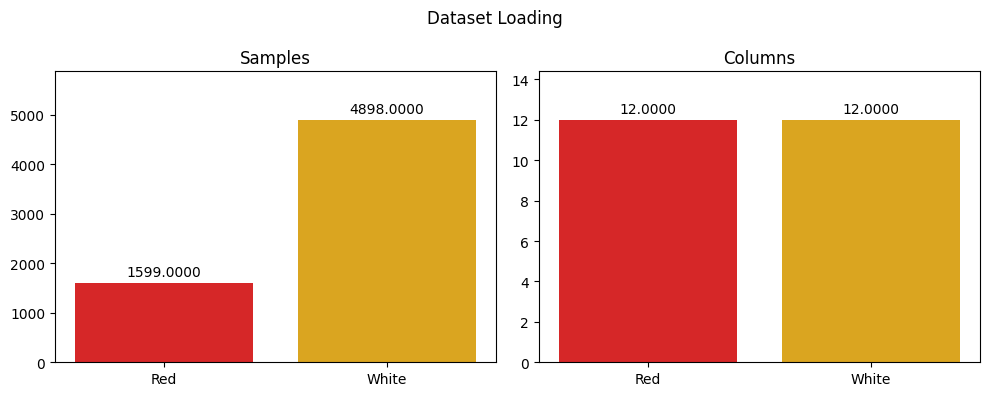

In [ ]:
compare_metric_rows('Dataset Loading',{'Samples':len(df),'Columns':df.shape[1]},{'Samples':len(white_df),'Columns':white_df.shape[1]})

## 1. Exploratory Data Analysis and Data Cleaning
Inspect dataset dimensions, data types, missing values, duplicate rows and quality-score distributions before modelling. The initial distribution and correlation plots use the original records. Red wine starts with 1,599 records and loses 240 exact duplicates, leaving 1,359; white wine starts with 4,898 and loses 937, leaving 3,961. Duplicates are removed before splitting to prevent identical records appearing in both training and test sets; repeated records are not automatically assumed to be measurement errors. Correlations describe associations and do not establish causation.

#### Red Wine — Calculations

In [ ]:
with capture_output() as _individual_output:
    # Dataset dimensions
    print("Red Wine dataset shape:", df.shape)

    # Column names
    print("\nColumns:")
    print(df.columns.tolist())

    # Missing values
    print("\nMissing values:")
    print(df.isnull().sum())

    # Basic statistics
    df.describe()

plt.close("all")

In [ ]:
with capture_output() as _individual_output:
    # Check data types
    print("Data Types:")
    print(df.dtypes)

    # Check duplicate rows
    print("\nDuplicate rows:", df.duplicated().sum())

    # Check quality score distribution
    print("\nRed Wine Quality Distribution:")
    print(df["quality"].value_counts().sort_index())

plt.close("all")

In [ ]:
with capture_output() as _individual_output:
    import matplotlib.pyplot as plt

    quality_counts = df["quality"].value_counts().sort_index()

    plt.figure(figsize=(8, 5))
    plt.bar(quality_counts.index, quality_counts.values)

    plt.title("Distribution of Red Wine Quality Scores")
    plt.xlabel("Wine Quality Score")
    plt.ylabel("Number of Wine Samples")
    plt.xticks(quality_counts.index)

    plt.show()

plt.close("all")

In [ ]:
with capture_output() as _individual_output:
    import matplotlib.pyplot as plt

    # Calculate correlation matrix
    correlation = df.corr(numeric_only=True)

    # Show correlation with wine quality
    quality_corr = correlation["quality"].sort_values(
        ascending=False
    )

    print(quality_corr)

    # Visualise feature correlations with wine quality
    quality_corr.drop("quality").sort_values().plot(
        kind="barh",
        figsize=(9, 6)
    )

    plt.title("Feature Correlation with Red Wine Quality")
    plt.xlabel("Pearson Correlation Coefficient")
    plt.ylabel("Features")
    plt.axvline(0, color="black", linewidth=0.8)
    plt.tight_layout()
    plt.show()

plt.close("all")

In [ ]:
with capture_output() as _individual_output:
    # Keep original dataset unchanged
    df_clean = df.drop_duplicates().copy()

    print("Original Red Wine dataset:", df.shape)
    print("Cleaned Red Wine dataset:", df_clean.shape)
    print("Duplicates removed:", len(df) - len(df_clean))

    # Confirm duplicates were removed
    print("Remaining duplicates:",
          df_clean.duplicated().sum())

    # Quality distribution after cleaning
    print("\nCleaned quality distribution:")
    print(df_clean["quality"].value_counts().sort_index())

plt.close("all")

#### White Wine — Calculations

In [ ]:
with capture_output() as _individual_output:
    # Dataset dimensions
    print("White Wine dataset shape:", white_df.shape)

    # Column names
    print("\nColumns:")
    print(white_df.columns.tolist())

    # Missing values
    print("\nMissing values:")
    print(white_df.isnull().sum())

    # Basic statistics
    white_df.describe()

plt.close("all")

In [ ]:
with capture_output() as _individual_output:
    # Check data types
    print("Data Types:")
    print(white_df.dtypes)

    # Check duplicate rows
    print("\nDuplicate rows:", white_df.duplicated().sum())

    # Check quality score distribution
    print("\nWhite Wine Quality Distribution:")
    print(white_df["quality"].value_counts().sort_index())

plt.close("all")

In [ ]:
with capture_output() as _individual_output:
    import matplotlib.pyplot as plt

    white_quality_counts = white_df["quality"].value_counts().sort_index()

    plt.figure(figsize=(8, 5))
    plt.bar(white_quality_counts.index, white_quality_counts.values)

    plt.title("Distribution of White Wine Quality Scores")
    plt.xlabel("Wine Quality Score")
    plt.ylabel("Number of Wine Samples")
    plt.xticks(white_quality_counts.index)

    plt.show()

plt.close("all")

In [ ]:
with capture_output() as _individual_output:
    import matplotlib.pyplot as plt

    # Calculate correlation matrix
    white_correlation = white_df.corr(numeric_only=True)

    # Show correlation with wine quality
    white_quality_corr = white_correlation["quality"].sort_values(
        ascending=False
    )

    print(white_quality_corr)

    # Visualise feature correlations with wine quality
    white_quality_corr.drop("quality").sort_values().plot(
        kind="barh",
        figsize=(9, 6)
    )

    plt.title("Feature Correlation with White Wine Quality")
    plt.xlabel("Pearson Correlation Coefficient")
    plt.ylabel("Features")
    plt.axvline(0, color="black", linewidth=0.8)
    plt.tight_layout()
    plt.show()

plt.close("all")

In [ ]:
with capture_output() as _individual_output:
    # Keep original dataset unchanged
    white_df_clean = white_df.drop_duplicates().copy()

    print("Original White Wine dataset:", white_df.shape)
    print("Cleaned White Wine dataset:", white_df_clean.shape)
    print("Duplicates removed:", len(white_df) - len(white_df_clean))

    # Confirm duplicates were removed
    print("Remaining duplicates:",
          white_df_clean.duplicated().sum())

    # Quality distribution after cleaning
    print("\nCleaned quality distribution:")
    print(white_df_clean["quality"].value_counts().sort_index())

plt.close("all")

#### Combined Results
Compare the original quality-score distributions, then inspect duplicate removal and feature–quality correlations below. These plots describe the data; correlation does not establish causation.

,Quality,Samples,Dataset
0,3,10,Red
1,4,53,Red
2,5,681,Red
3,6,638,Red
4,7,199,Red
5,8,18,Red
6,3,20,White
7,4,163,White
8,5,1457,White
9,6,2198,White


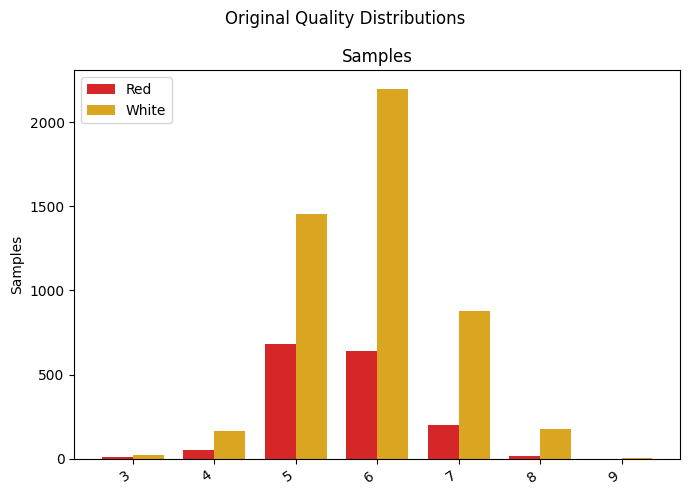

In [ ]:
compare_tables('Original Quality Distributions',quality_counts.rename_axis('Quality').reset_index(name='Samples'),white_quality_counts.rename_axis('Quality').reset_index(name='Samples'),'Quality',['Samples'])

,Dataset,Removed,Remaining
0,Red,240,1359
1,White,937,3961


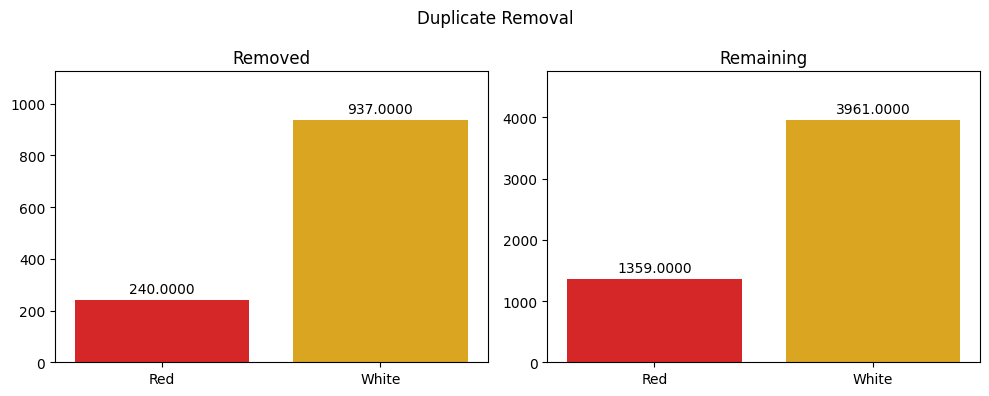

In [ ]:
compare_metric_rows('Duplicate Removal',{'Removed':len(df)-len(df_clean),'Remaining':len(df_clean)},{'Removed':len(white_df)-len(white_df_clean),'Remaining':len(white_df_clean)})

,Feature,Correlation,Dataset
0,alcohol,0.4762,Red
1,sulphates,0.2514,Red
2,citric acid,0.2264,Red
3,fixed acidity,0.1241,Red
4,residual sugar,0.0137,Red
5,free sulfur dioxide,-0.0507,Red
6,pH,-0.0577,Red
7,chlorides,-0.1289,Red
8,density,-0.1749,Red
9,total sulfur dioxide,-0.1851,Red


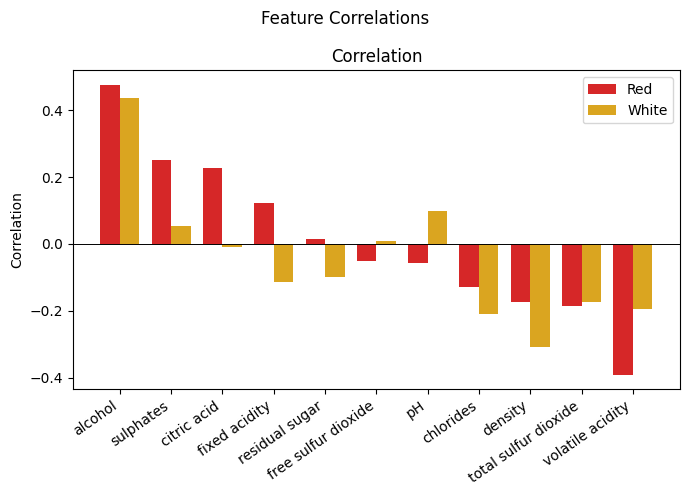

In [ ]:
compare_tables('Feature Correlations',quality_corr.drop('quality').rename_axis('Feature').reset_index(name='Correlation'),white_quality_corr.drop('quality').rename_axis('Feature').reset_index(name='Correlation'),'Feature',['Correlation'])

## 2. Dataset Splitting and Preparation
Separate the 11 input features from the numerical quality target, then split each cleaned dataset into 80% training and 20% testing with random_state=42. Stratification preserves approximately the quality-score proportions in the holdout split. Red wine has 1,087 training and 272 test records; white wine has 3,168 training and 793 test records. All models share the same split within each dataset. Subsequent CV uses shuffled five-fold KFold on training data, not stratified folds. Model selection uses training-set CV; because test results have been inspected during development, final test comparisons remain exploratory.

#### Red Wine — Calculations

In [ ]:
with capture_output() as _individual_output:
    # Input features (11 chemical properties)
    X = df_clean.drop(columns=["quality"])

    # Target variable (wine quality)
    y = df_clean["quality"]

    print("Features shape:", X.shape)
    print("Target shape:", y.shape)

plt.close("all")

In [ ]:
with capture_output() as _individual_output:
    from sklearn.model_selection import train_test_split

    X_train, X_test, y_train, y_test = train_test_split(
        X,
        y,
        test_size=0.2,
        random_state=42,
        stratify=y
    )

    print("Red Wine X_train:", X_train.shape)
    print("Red Wine X_test:", X_test.shape)
    print("Red Wine y_train:", y_train.shape)
    print("Red Wine y_test:", y_test.shape)

plt.close("all")

#### White Wine — Calculations

In [ ]:
with capture_output() as _individual_output:
    # Input features (11 chemical properties)
    white_X = white_df_clean.drop(columns=["quality"])

    # Target variable (wine quality)
    white_y = white_df_clean["quality"]

    print("Features shape:", white_X.shape)
    print("Target shape:", white_y.shape)

plt.close("all")

In [ ]:
with capture_output() as _individual_output:
    from sklearn.model_selection import train_test_split

    white_X_train, white_X_test, white_y_train, white_y_test = train_test_split(
        white_X,
        white_y,
        test_size=0.2,
        random_state=42,
        stratify=white_y
    )

    print("White Wine X_train:", white_X_train.shape)
    print("White Wine X_test:", white_X_test.shape)
    print("White Wine y_train:", white_y_train.shape)
    print("White Wine y_test:", white_y_test.shape)

plt.close("all")

#### Combined Results
Check the training and test counts after duplicate removal. Red and white remain separate datasets, and every model uses the same holdout partition within its dataset.

,Dataset,Train Samples,Test Samples
0,Red,1087,272
1,White,3168,793


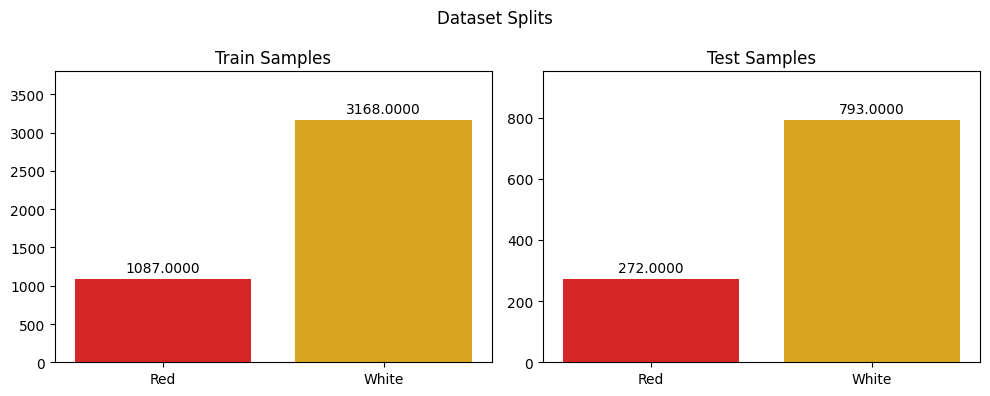

In [ ]:
compare_metric_rows('Dataset Splits',{'Train Samples':len(y_train),'Test Samples':len(y_test)},{'Train Samples':len(white_y_train),'Test Samples':len(white_y_test)})

## 3. Baseline Model 1: Linear Regression

Fit a separate ordinary least squares Linear Regression model to each wine dataset using all 11 chemical inputs and a fitted intercept. The model learns a weighted combination of the inputs by minimising squared training errors, without polynomial feature expansion. This provides a simple reference for evaluating more flexible methods. Compare test MAE, RMSE and R², and inspect actual-versus-predicted plots: points closer to the diagonal indicate smaller errors.

#### Red Wine — Calculations

In [ ]:
with capture_output() as _individual_output:
    from sklearn.linear_model import LinearRegression

    # Create Linear Regression model
    lr_model = LinearRegression()

    # Train the model using training data
    lr_model.fit(X_train, y_train)

    # Predict wine quality for test data
    y_pred_lr = lr_model.predict(X_test)

    print("Linear Regression training completed!")
    print("Red Wine first 10 predictions:")
    print(y_pred_lr[:10])

plt.close("all")

In [ ]:
with capture_output() as _individual_output:
    from sklearn.metrics import (
        mean_absolute_error,
        mean_squared_error,
        r2_score
    )
    import numpy as np

    # Test performance
    lr_mae = mean_absolute_error(y_test, y_pred_lr)
    lr_rmse = np.sqrt(
        mean_squared_error(y_test, y_pred_lr)
    )
    lr_r2 = r2_score(y_test, y_pred_lr)

    # Training performance
    y_train_pred_lr = lr_model.predict(X_train)

    lr_train_r2 = r2_score(
        y_train, y_train_pred_lr
    )

    print("Red Wine Linear Regression Results")
    print("-------------------------")
    print(f"MAE: {lr_mae:.4f}")
    print(f"RMSE: {lr_rmse:.4f}")
    print(f"Test R²: {lr_r2:.4f}")
    print(f"Train R²: {lr_train_r2:.4f}")

plt.close("all")

In [ ]:
with capture_output() as _individual_output:
    import pandas as pd

    comparison_lr = pd.DataFrame({
        "Actual Quality": y_test.values,
        "Predicted Quality": y_pred_lr
    })

    comparison_lr["Absolute Error"] = abs(
        comparison_lr["Actual Quality"] -
        comparison_lr["Predicted Quality"]
    )

    print("Red Wine Actual vs Predicted:")
    display(comparison_lr.head(10))

plt.close("all")

In [ ]:
with capture_output() as _individual_output:
    import matplotlib.pyplot as plt

    plt.figure(figsize=(7, 5))

    plt.scatter(
        y_test,
        y_pred_lr,
        alpha=0.5
    )

    plt.plot(
        [3, 8],
        [3, 8],
        linestyle="--",
        color="red",
        label="Perfect Prediction"
    )

    plt.xlabel("Actual Wine Quality")
    plt.ylabel("Predicted Wine Quality")
    plt.title("Red Wine Linear Regression: Actual vs Predicted")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()

plt.close("all")

In [ ]:
with capture_output() as _individual_output:
    results = []
    print('Red Wine Model Comparison:')

    results.append({
        "Model": "Linear Regression",
        "MAE": lr_mae,
        "RMSE": lr_rmse,
        "R2": lr_r2
    })

    results_df = pd.DataFrame(results)

    display(results_df.round(4))

plt.close("all")

#### White Wine — Calculations

In [ ]:
with capture_output() as _individual_output:
    from sklearn.linear_model import LinearRegression

    # Create Linear Regression model
    white_lr_model = LinearRegression()

    # Train the model using training data
    white_lr_model.fit(white_X_train, white_y_train)

    # Predict wine quality for test data
    white_y_pred_lr = white_lr_model.predict(white_X_test)

    print("Linear Regression training completed!")
    print("White Wine first 10 predictions:")
    print(white_y_pred_lr[:10])

plt.close("all")

In [ ]:
with capture_output() as _individual_output:
    from sklearn.metrics import (
        mean_absolute_error,
        mean_squared_error,
        r2_score
    )
    import numpy as np

    # Test performance
    white_lr_mae = mean_absolute_error(white_y_test, white_y_pred_lr)
    white_lr_rmse = np.sqrt(
        mean_squared_error(white_y_test, white_y_pred_lr)
    )
    white_lr_r2 = r2_score(white_y_test, white_y_pred_lr)

    # Training performance
    white_y_train_pred_lr = white_lr_model.predict(white_X_train)

    white_lr_train_r2 = r2_score(
        white_y_train, white_y_train_pred_lr
    )

    print("White Wine Linear Regression Results")
    print("-------------------------")
    print(f"MAE: {white_lr_mae:.4f}")
    print(f"RMSE: {white_lr_rmse:.4f}")
    print(f"Test R²: {white_lr_r2:.4f}")
    print(f"Train R²: {white_lr_train_r2:.4f}")

plt.close("all")

In [ ]:
with capture_output() as _individual_output:
    import pandas as pd

    white_comparison_lr = pd.DataFrame({
        "Actual Quality": white_y_test.values,
        "Predicted Quality": white_y_pred_lr
    })

    white_comparison_lr["Absolute Error"] = abs(
        white_comparison_lr["Actual Quality"] -
        white_comparison_lr["Predicted Quality"]
    )

    print("White Wine Actual vs Predicted:")
    display(white_comparison_lr.head(10))

plt.close("all")

In [ ]:
with capture_output() as _individual_output:
    import matplotlib.pyplot as plt

    plt.figure(figsize=(7, 5))

    plt.scatter(
        white_y_test,
        white_y_pred_lr,
        alpha=0.5
    )

    plt.plot(
        [3, 9],
        [3, 9],
        linestyle="--",
        color="red",
        label="Perfect Prediction"
    )

    plt.xlabel("Actual Wine Quality")
    plt.ylabel("Predicted Wine Quality")
    plt.title("White Wine Linear Regression: Actual vs Predicted")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()

plt.close("all")

In [ ]:
with capture_output() as _individual_output:
    white_results = []
    print('White Wine Model Comparison:')

    white_results.append({
        "Model": "Linear Regression",
        "MAE": white_lr_mae,
        "RMSE": white_lr_rmse,
        "R2": white_lr_r2
    })

    white_results_df = pd.DataFrame(white_results)

    display(white_results_df.round(4))

plt.close("all")

#### Combined Results
Compare the red and white outputs below for this section. Lower MAE/RMSE and higher R² indicate better prediction where these metrics are shown. Cross-dataset differences are descriptive.

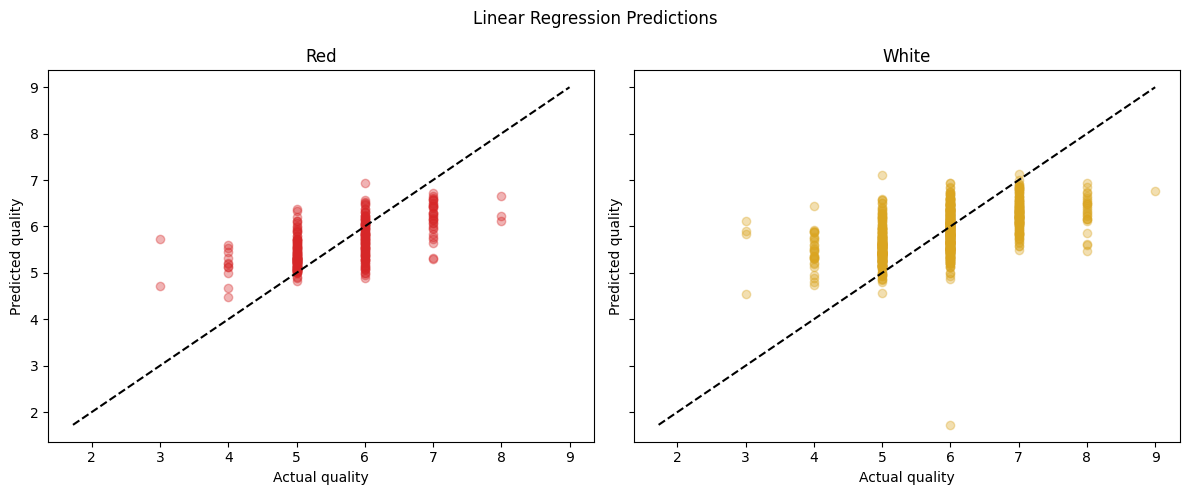

In [ ]:
compare_predictions('Linear Regression Predictions',y_test,y_pred_lr,white_y_test,white_y_pred_lr)

,Dataset,Test MAE,Test RMSE,Test R2
0,Red,0.5066,0.6523,0.3657
1,White,0.5867,0.7608,0.2703


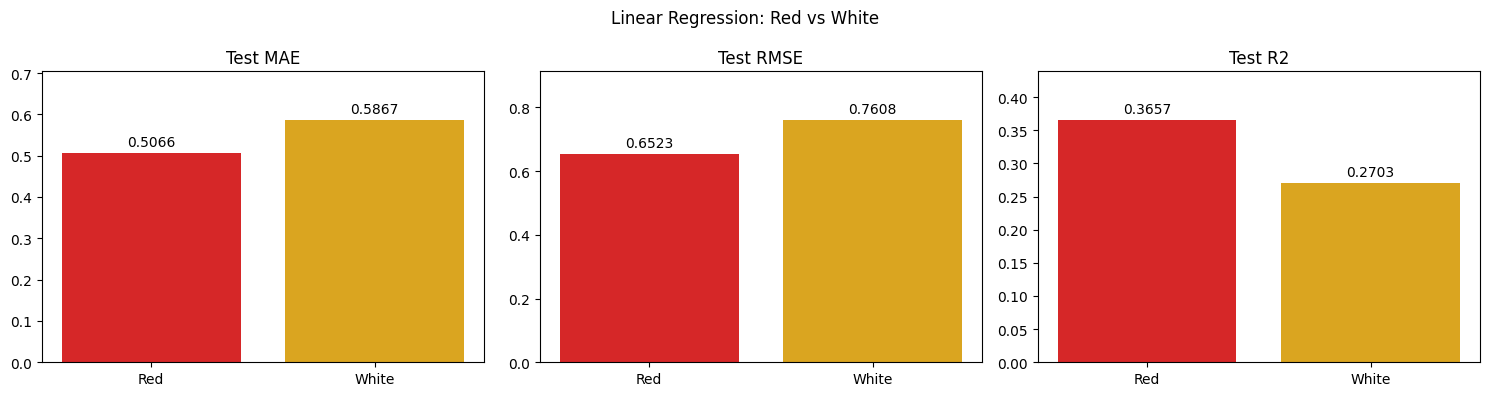

In [ ]:
compare_metric_rows('Linear Regression: Red vs White', {'Test MAE':lr_mae,'Test RMSE':lr_rmse,'Test R2':lr_r2}, {'Test MAE':white_lr_mae,'Test RMSE':white_lr_rmse,'Test R2':white_lr_r2})

## 4. Baseline Model 2: Decision Tree Regression

Fit a separate Decision Tree regressor with random_state=42 and no explicit maximum-depth limit. A tree divides wines into groups using feature thresholds and predicts the mean training quality within each final leaf. Compare training and test R² alongside test errors to assess whether detailed training rules generalise. A high training score alone does not demonstrate good prediction on unseen wines.

#### Red Wine — Calculations

In [ ]:
with capture_output() as _individual_output:
    from sklearn.tree import DecisionTreeRegressor

    # Create Decision Tree model
    dt_model = DecisionTreeRegressor(
        random_state=42
    )

    # Train the model
    dt_model.fit(X_train, y_train)

    # Predict test data
    y_pred_dt = dt_model.predict(X_test)

    print("Decision Tree training completed!")
    print("Red Wine first 10 predictions:")
    print(y_pred_dt[:10])

plt.close("all")

In [ ]:
with capture_output() as _individual_output:
    # Evaluate test performance
    dt_mae = mean_absolute_error(y_test, y_pred_dt)

    dt_rmse = np.sqrt(
        mean_squared_error(y_test, y_pred_dt)
    )

    dt_r2 = r2_score(y_test, y_pred_dt)

    # Evaluate training performance
    y_train_pred_dt = dt_model.predict(X_train)

    dt_train_r2 = r2_score(
        y_train, y_train_pred_dt
    )

    print("Red Wine Decision Tree Results")
    print("----------------------")
    print(f"MAE: {dt_mae:.4f}")
    print(f"RMSE: {dt_rmse:.4f}")
    print(f"Test R²: {dt_r2:.4f}")
    print(f"Train R²: {dt_train_r2:.4f}")

plt.close("all")

In [ ]:
with capture_output() as _individual_output:
    # Prevent duplicate rows if this cell is rerun
    print("Red Wine Model Comparison:")
    results = [
        r for r in results
        if r["Model"] != "Decision Tree"
    ]

    results.append({
        "Model": "Decision Tree",
        "MAE": dt_mae,
        "RMSE": dt_rmse,
        "R2": dt_r2
    })

    results_df = pd.DataFrame(results)

    display(results_df.round(4))

plt.close("all")

#### White Wine — Calculations

In [ ]:
with capture_output() as _individual_output:
    from sklearn.tree import DecisionTreeRegressor

    # Create Decision Tree model
    white_dt_model = DecisionTreeRegressor(
        random_state=42
    )

    # Train the model
    white_dt_model.fit(white_X_train, white_y_train)

    # Predict test data
    white_y_pred_dt = white_dt_model.predict(white_X_test)

    print("Decision Tree training completed!")
    print("White Wine first 10 predictions:")
    print(white_y_pred_dt[:10])

plt.close("all")

In [ ]:
with capture_output() as _individual_output:
    # Evaluate test performance
    white_dt_mae = mean_absolute_error(white_y_test, white_y_pred_dt)

    white_dt_rmse = np.sqrt(
        mean_squared_error(white_y_test, white_y_pred_dt)
    )

    white_dt_r2 = r2_score(white_y_test, white_y_pred_dt)

    # Evaluate training performance
    white_y_train_pred_dt = white_dt_model.predict(white_X_train)

    white_dt_train_r2 = r2_score(
        white_y_train, white_y_train_pred_dt
    )

    print("White Wine Decision Tree Results")
    print("----------------------")
    print(f"MAE: {white_dt_mae:.4f}")
    print(f"RMSE: {white_dt_rmse:.4f}")
    print(f"Test R²: {white_dt_r2:.4f}")
    print(f"Train R²: {white_dt_train_r2:.4f}")

plt.close("all")

In [ ]:
with capture_output() as _individual_output:
    # Prevent duplicate rows if this cell is rerun
    print("White Wine Model Comparison:")
    white_results = [
        white_r for white_r in white_results
        if white_r["Model"] != "Decision Tree"
    ]

    white_results.append({
        "Model": "Decision Tree",
        "MAE": white_dt_mae,
        "RMSE": white_dt_rmse,
        "R2": white_dt_r2
    })

    white_results_df = pd.DataFrame(white_results)

    display(white_results_df.round(4))

plt.close("all")

#### Combined Results
Compare the red and white outputs below for this section. Lower MAE/RMSE and higher R² indicate better prediction where these metrics are shown. Cross-dataset differences are descriptive.

,Dataset,Test MAE,Test RMSE,Test R2
0,Red,0.5919,0.8849,-0.1673
1,White,0.7440,1.0498,-0.3894


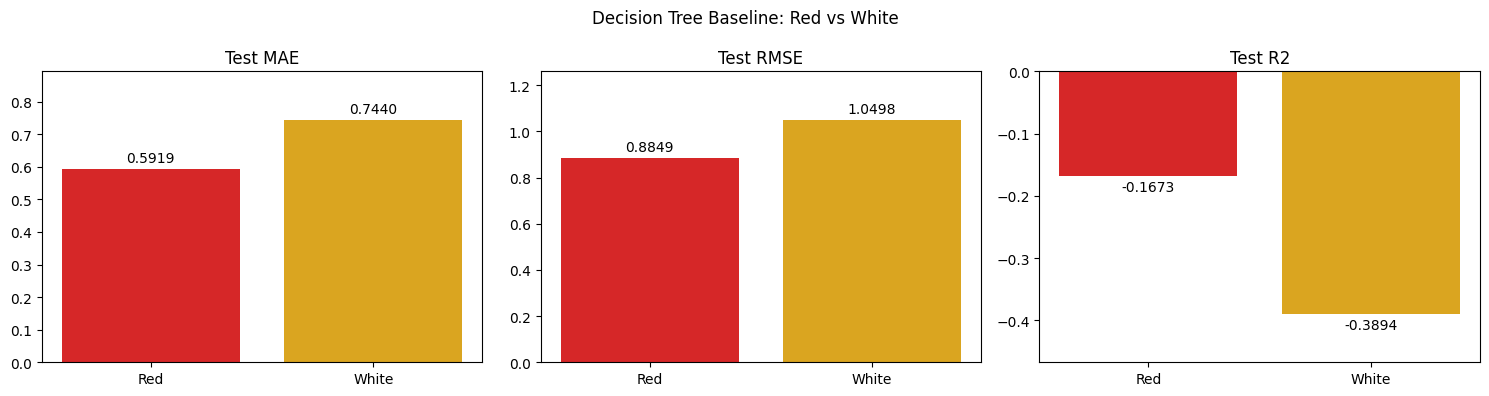

In [ ]:
compare_metric_rows('Decision Tree Baseline: Red vs White', {'Test MAE':dt_mae,'Test RMSE':dt_rmse,'Test R2':dt_r2}, {'Test MAE':white_dt_mae,'Test RMSE':white_dt_rmse,'Test R2':white_dt_r2})

### 4.1 Decision Tree Hyperparameter Tuning (Depth vs. Overfitting)

Test maximum tree depths of 2, 3, 4, 5, 6, 8, 10, 15 and None using five-fold CV on the training set. Depth is the maximum number of splits along a root-to-leaf path; None removes the explicit depth cap but other stopping rules still apply. Compare training R² with validation MAE and R² to investigate underfitting and overfitting. Prefer lower CV MAE when discussing selection; the depth with the highest R² may differ. This experiment does not replace the baseline tree in Section 9.

#### Red Wine — Calculations

In [ ]:
with capture_output() as _individual_output:
    from sklearn.tree import DecisionTreeRegressor
    from sklearn.model_selection import KFold, cross_validate
    import pandas as pd

    depths = [2, 3, 4, 5, 6, 8, 10, 15, None]

    # Use only training data for model selection
    cv = KFold(
        n_splits=5,
        shuffle=True,
        random_state=42
    )

    depth_results = []

    for depth in depths:
        model = DecisionTreeRegressor(
            max_depth=depth,
            random_state=42
        )

        scores = cross_validate(
            model,
            X_train,
            y_train,
            cv=cv,
            scoring={
                "mae": "neg_mean_absolute_error",
                "r2": "r2"
            },
            return_train_score=True
        )

        depth_results.append({
            "Max Depth": str(depth),
            "Train R2": scores["train_r2"].mean(),
            "CV R2": scores["test_r2"].mean(),
            "CV MAE": -scores["test_mae"].mean()
        })

    depth_df = pd.DataFrame(depth_results)

    display(depth_df.round(4))

plt.close("all")

In [ ]:
with capture_output() as _individual_output:
    import matplotlib.pyplot as plt

    plt.figure(figsize=(10, 6))

    plt.plot(
        depth_df["Max Depth"],
        depth_df["Train R2"],
        marker="o",
        label="Training R2"
    )

    plt.plot(
        depth_df["Max Depth"],
        depth_df["CV R2"],
        marker="s",
        label="Cross-Validation R2"
    )

    plt.xlabel("Maximum Tree Depth")
    plt.ylabel("R2 Score")
    plt.title("Red Wine Decision Tree: Depth vs Model Performance")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

    best_row = depth_df.loc[
        depth_df["CV MAE"].idxmin()
    ]

    print("Best Decision Tree Depth:", best_row["Max Depth"])
    print(f"Best CV MAE: {best_row['CV MAE']:.4f}")
    print(f"CV R2 at Best Depth: {best_row['CV R2']:.4f}")

plt.close("all")

#### White Wine — Calculations

In [ ]:
with capture_output() as _individual_output:
    from sklearn.tree import DecisionTreeRegressor
    from sklearn.model_selection import KFold, cross_validate
    import pandas as pd

    white_depths = [2, 3, 4, 5, 6, 8, 10, 15, None]

    # Use only training data for model selection
    white_cv = KFold(
        n_splits=5,
        shuffle=True,
        random_state=42
    )

    white_depth_results = []

    for white_depth in white_depths:
        white_model = DecisionTreeRegressor(
            max_depth=white_depth,
            random_state=42
        )

        white_scores = cross_validate(
            white_model,
            white_X_train,
            white_y_train,
            cv=white_cv,
            scoring={
                "mae": "neg_mean_absolute_error",
                "r2": "r2"
            },
            return_train_score=True
        )

        white_depth_results.append({
            "Max Depth": str(white_depth),
            "Train R2": white_scores["train_r2"].mean(),
            "CV R2": white_scores["test_r2"].mean(),
            "CV MAE": -white_scores["test_mae"].mean()
        })

    white_depth_df = pd.DataFrame(white_depth_results)

    display(white_depth_df.round(4))

plt.close("all")

In [ ]:
with capture_output() as _individual_output:
    import matplotlib.pyplot as plt

    plt.figure(figsize=(10, 6))

    plt.plot(
        white_depth_df["Max Depth"],
        white_depth_df["Train R2"],
        marker="o",
        label="Training R2"
    )

    plt.plot(
        white_depth_df["Max Depth"],
        white_depth_df["CV R2"],
        marker="s",
        label="Cross-Validation R2"
    )

    plt.xlabel("Maximum Tree Depth")
    plt.ylabel("R2 Score")
    plt.title("White Wine Decision Tree: Depth vs Model Performance")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

    white_best_row = white_depth_df.loc[
        white_depth_df["CV MAE"].idxmin()
    ]

    print("Best Decision Tree Depth:", white_best_row["Max Depth"])
    print(f"Best CV MAE: {white_best_row['CV MAE']:.4f}")
    print(f"CV R2 at Best Depth: {white_best_row['CV R2']:.4f}")

plt.close("all")

#### Combined Results
Compare the red and white outputs below for this section. Lower MAE/RMSE and higher R² indicate better prediction where these metrics are shown. Cross-dataset differences are descriptive.

,Max Depth,Train R2,CV R2,CV MAE,Dataset
0,2,0.2791,0.2161,0.5805,Red
1,3,0.3621,0.2902,0.5509,Red
2,4,0.4343,0.2855,0.5493,Red
3,5,0.5097,0.2441,0.5490,Red
4,6,0.5949,0.2378,0.5389,Red
5,8,0.7555,0.1070,0.5602,Red
6,10,0.8722,-0.0148,0.5734,Red
7,15,0.9913,-0.1026,0.5628,Red
8,None,1.0000,-0.1457,0.5723,Red
9,2,0.2410,0.2279,0.6301,White


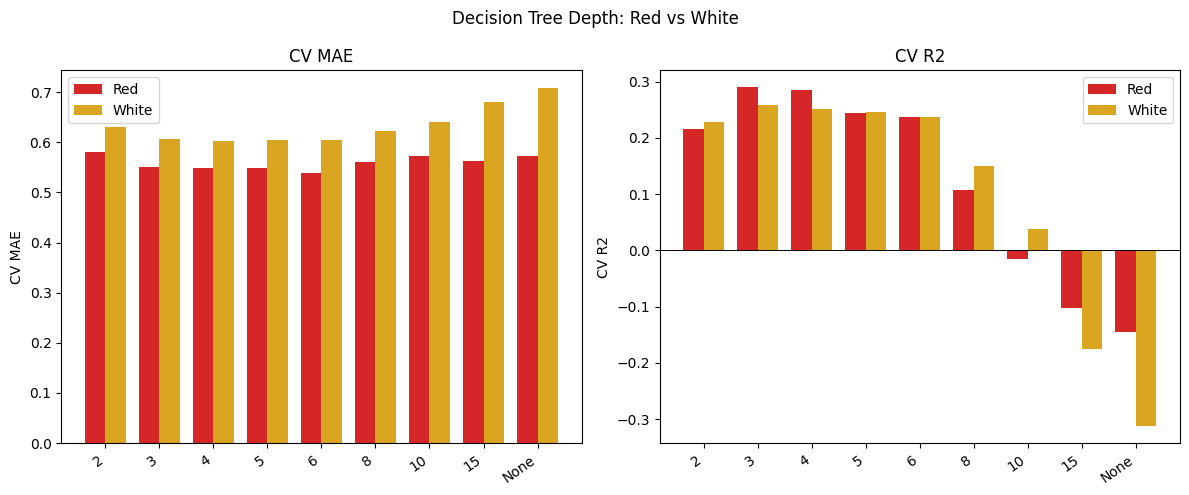

In [ ]:
compare_tables('Decision Tree Depth: Red vs White',depth_df,white_depth_df,'Max Depth',['CV MAE', 'CV R2'])

## 5. Baseline Model 3: Random Forest Regression

Train a Random Forest baseline with 100 trees and random_state=42. Each tree uses a bootstrap sample and random feature subsets at splits, and the forest averages their predictions. Averaging can reduce the variability of a single tree. In addition to overall test metrics, examine errors by quality score and broad quality group, including sample counts. These summaries show whether overall accuracy hides poor performance on rare scores.

#### Red Wine — Calculations

In [ ]:
with capture_output() as _individual_output:
    from sklearn.ensemble import RandomForestRegressor

    # Create Random Forest model
    rf_model = RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    )

    # Train the model
    rf_model.fit(X_train, y_train)

    # Predict wine quality
    y_pred_rf = rf_model.predict(X_test)

    print("Random Forest training completed!")
    print("Red Wine first 10 predictions:")
    print(y_pred_rf[:10])

plt.close("all")

In [ ]:
with capture_output() as _individual_output:
    # Test performance
    rf_mae = mean_absolute_error(y_test, y_pred_rf)

    rf_rmse = np.sqrt(
        mean_squared_error(y_test, y_pred_rf)
    )

    rf_r2 = r2_score(y_test, y_pred_rf)

    # Training performance
    y_train_pred_rf = rf_model.predict(X_train)
    rf_train_r2 = r2_score(y_train, y_train_pred_rf)

    print("Red Wine Random Forest Results")
    print("----------------------")
    print(f"MAE: {rf_mae:.4f}")
    print(f"RMSE: {rf_rmse:.4f}")
    print(f"Test R²: {rf_r2:.4f}")
    print(f"Train R²: {rf_train_r2:.4f}")

plt.close("all")

In [ ]:
with capture_output() as _individual_output:
    print("Red Wine Model Comparison:")
    results = [
        {
            "Model": "Linear Regression",
            "MAE": lr_mae,
            "RMSE": lr_rmse,
            "R2": lr_r2
        },
        {
            "Model": "Decision Tree",
            "MAE": dt_mae,
            "RMSE": dt_rmse,
            "R2": dt_r2
        },
        {
            "Model": "Random Forest",
            "MAE": rf_mae,
            "RMSE": rf_rmse,
            "R2": rf_r2
        }
    ]

    results_df = pd.DataFrame(results)

    display(results_df.round(4))

plt.close("all")

In [ ]:
with capture_output() as _individual_output:
    import matplotlib.pyplot as plt
    import pandas as pd

    # Use your group's recorded results
    comparison = results_df[
        ["Model", "MAE", "RMSE", "R2"]
    ].copy()

    # Create a separate figure for each metric
    for metric in ["MAE", "RMSE", "R2"]:
        fig, ax = plt.subplots(figsize=(9, 4.5))

        bars = ax.barh(
            comparison["Model"],
            comparison[metric]
        )

        ax.bar_label(bars, fmt="%.4f", padding=4)
        ax.axvline(0, linewidth=0.8)
        ax.set_xlabel(metric)
        ax.set_title(f"Red Wine Model Comparison — {metric}")
        ax.invert_yaxis()

        if metric == "R2":
            ax.set_xlim(-0.3, 0.65)
        else:
            ax.set_xlim(0, comparison[metric].max() * 1.2)

        plt.tight_layout()
        plt.savefig(
            f"red_wine_{metric}.png",
            dpi=300,
            bbox_inches="tight"
        )
        plt.show()

plt.close("all")

In [ ]:
with capture_output() as _individual_output:
    # Actual vs predicted Random Forest results
    error_df = pd.DataFrame({
        "Actual Quality": y_test.values,
        "Predicted Quality": y_pred_rf
    })

    # Calculate absolute errors
    error_df["Absolute Error"] = abs(
        error_df["Actual Quality"] -
        error_df["Predicted Quality"]
    )

    # Group errors by actual wine quality
    error_by_quality = error_df.groupby(
        "Actual Quality"
    ).agg(
        Sample_Count=("Absolute Error", "size"),
        Mean_Absolute_Error=("Absolute Error", "mean")
    ).reset_index()

    display(error_by_quality.round(4))

plt.close("all")

In [ ]:
with capture_output() as _individual_output:
    fig, ax = plt.subplots(figsize=(9, 5))

    bars = ax.bar(
        error_by_quality["Actual Quality"].astype(str),
        error_by_quality["Mean_Absolute_Error"]
    )

    ax.bar_label(bars, fmt="%.3f", padding=3)

    ax.set_xlabel("Actual Wine Quality Score")
    ax.set_ylabel("Mean Absolute Error")
    ax.set_title(
        "Red Wine Random Forest Prediction Error by Quality Score"
    )

    plt.tight_layout()
    plt.savefig(
        "red_wine_rf_error_by_quality.png",
        dpi=300,
        bbox_inches="tight"
    )
    plt.show()

    print(error_by_quality.round(4))

plt.close("all")

In [ ]:
with capture_output() as _individual_output:
    import pandas as pd

    error_df["Quality Group"] = pd.cut(
        error_df["Actual Quality"],
        bins=[2, 4, 6, 8],
        labels=[
            "Low Quality (3-4)",
            "Typical Quality (5-6)",
            "High Quality (7-8)"
        ],
        include_lowest=True
    )

    assert error_df["Quality Group"].notna().all()

    marginal_results = (
        error_df.groupby(
            "Quality Group",
            observed=True
        )["Absolute Error"]
        .agg(
            Sample_Count="size",
            MAE="mean"
        )
        .reset_index()
    )

    print("Baseline Random Forest: Marginal-Case Analysis- Red Wine")
    display(marginal_results.round(4))

    print("Total grouped samples:",
          marginal_results["Sample_Count"].sum())
    print("Total test samples:", len(y_test))

    assert marginal_results["Sample_Count"].sum() == len(y_test)

plt.close("all")

#### White Wine — Calculations

In [ ]:
with capture_output() as _individual_output:
    from sklearn.ensemble import RandomForestRegressor

    # Create Random Forest model
    white_rf_model = RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    )

    # Train the model
    white_rf_model.fit(white_X_train, white_y_train)

    # Predict wine quality
    white_y_pred_rf = white_rf_model.predict(white_X_test)

    print("Random Forest training completed!")
    print("White Wine first 10 predictions:")
    print(white_y_pred_rf[:10])

plt.close("all")

In [ ]:
with capture_output() as _individual_output:
    # Test performance
    white_rf_mae = mean_absolute_error(white_y_test, white_y_pred_rf)

    white_rf_rmse = np.sqrt(
        mean_squared_error(white_y_test, white_y_pred_rf)
    )

    white_rf_r2 = r2_score(white_y_test, white_y_pred_rf)

    # Training performance
    white_y_train_pred_rf = white_rf_model.predict(white_X_train)
    white_rf_train_r2 = r2_score(white_y_train, white_y_train_pred_rf)

    print("White Wine Random Forest Results")
    print("----------------------")
    print(f"MAE: {white_rf_mae:.4f}")
    print(f"RMSE: {white_rf_rmse:.4f}")
    print(f"Test R²: {white_rf_r2:.4f}")
    print(f"Train R²: {white_rf_train_r2:.4f}")

plt.close("all")

In [ ]:
with capture_output() as _individual_output:
    print("White Wine Model Comparison:")
    white_results = [
        {
            "Model": "Linear Regression",
            "MAE": white_lr_mae,
            "RMSE": white_lr_rmse,
            "R2": white_lr_r2
        },
        {
            "Model": "Decision Tree",
            "MAE": white_dt_mae,
            "RMSE": white_dt_rmse,
            "R2": white_dt_r2
        },
        {
            "Model": "Random Forest",
            "MAE": white_rf_mae,
            "RMSE": white_rf_rmse,
            "R2": white_rf_r2
        }
    ]

    white_results_df = pd.DataFrame(white_results)

    display(white_results_df.round(4))

plt.close("all")

In [ ]:
with capture_output() as _individual_output:
    import matplotlib.pyplot as plt
    import pandas as pd

    # Use your group's recorded results
    white_comparison = white_results_df[
        ["Model", "MAE", "RMSE", "R2"]
    ].copy()

    # Create a separate figure for each metric
    for white_metric in ["MAE", "RMSE", "R2"]:
        white_fig, white_ax = plt.subplots(figsize=(9, 4.5))

        white_bars = white_ax.barh(
            white_comparison["Model"],
            white_comparison[white_metric]
        )

        white_ax.bar_label(white_bars, fmt="%.4f", padding=4)
        white_ax.axvline(0, linewidth=0.8)
        white_ax.set_xlabel(white_metric)
        white_ax.set_title(f"White Wine Model Comparison — {white_metric}")
        white_ax.invert_yaxis()

        if white_metric == "R2":
            white_ax.set_xlim(-0.3, 0.65)
        else:
            white_ax.set_xlim(0, white_comparison[white_metric].max() * 1.2)

        plt.tight_layout()
        plt.savefig(
            f"white_wine_{white_metric}.png",
            dpi=300,
            bbox_inches="tight"
        )
        plt.show()

plt.close("all")

In [ ]:
with capture_output() as _individual_output:
    # Actual vs predicted Random Forest results
    white_error_df = pd.DataFrame({
        "Actual Quality": white_y_test.values,
        "Predicted Quality": white_y_pred_rf
    })

    # Calculate absolute errors
    white_error_df["Absolute Error"] = abs(
        white_error_df["Actual Quality"] -
        white_error_df["Predicted Quality"]
    )

    # Group errors by actual wine quality
    white_error_by_quality = white_error_df.groupby(
        "Actual Quality"
    ).agg(
        Sample_Count=("Absolute Error", "size"),
        Mean_Absolute_Error=("Absolute Error", "mean")
    ).reset_index()

    display(white_error_by_quality.round(4))

plt.close("all")

In [ ]:
with capture_output() as _individual_output:
    white_fig, white_ax = plt.subplots(figsize=(9, 5))

    white_bars = white_ax.bar(
        white_error_by_quality["Actual Quality"].astype(str),
        white_error_by_quality["Mean_Absolute_Error"]
    )

    white_ax.bar_label(white_bars, fmt="%.3f", padding=3)

    white_ax.set_xlabel("Actual Wine Quality Score")
    white_ax.set_ylabel("Mean Absolute Error")
    white_ax.set_title(
        "White Wine Random Forest Prediction Error by Quality Score"
    )

    plt.tight_layout()
    plt.savefig(
        "white_wine_rf_error_by_quality.png",
        dpi=300,
        bbox_inches="tight"
    )
    plt.show()

    print(white_error_by_quality.round(4))

plt.close("all")

In [ ]:
with capture_output() as _individual_output:
    import pandas as pd

    white_error_df["Quality Group"] = pd.cut(
        white_error_df["Actual Quality"],
        bins=[2, 4, 6, 9],
        labels=[
            "Low Quality (3-4)",
            "Typical Quality (5-6)",
            "High Quality (7-9)"
        ],
        include_lowest=True
    )

    assert white_error_df["Quality Group"].notna().all()

    white_marginal_results = (
        white_error_df.groupby(
            "Quality Group",
            observed=True
        )["Absolute Error"]
        .agg(
            Sample_Count="size",
            MAE="mean"
        )
        .reset_index()
    )

    print("Baseline Random Forest: Marginal-Case Analysis- White Wine")
    display(white_marginal_results.round(4))

    print("Total grouped samples:",
          white_marginal_results["Sample_Count"].sum())
    print("Total test samples:", len(white_y_test))

    assert white_marginal_results["Sample_Count"].sum() == len(white_y_test)

plt.close("all")

#### Combined Results
Compare the red and white outputs below for this section. Lower MAE/RMSE and higher R² indicate better prediction where these metrics are shown. Cross-dataset differences are descriptive.

,Dataset,Test MAE,Test RMSE,Test R2
0,Red,0.4768,0.6233,0.4209
1,White,0.5409,0.6988,0.3843


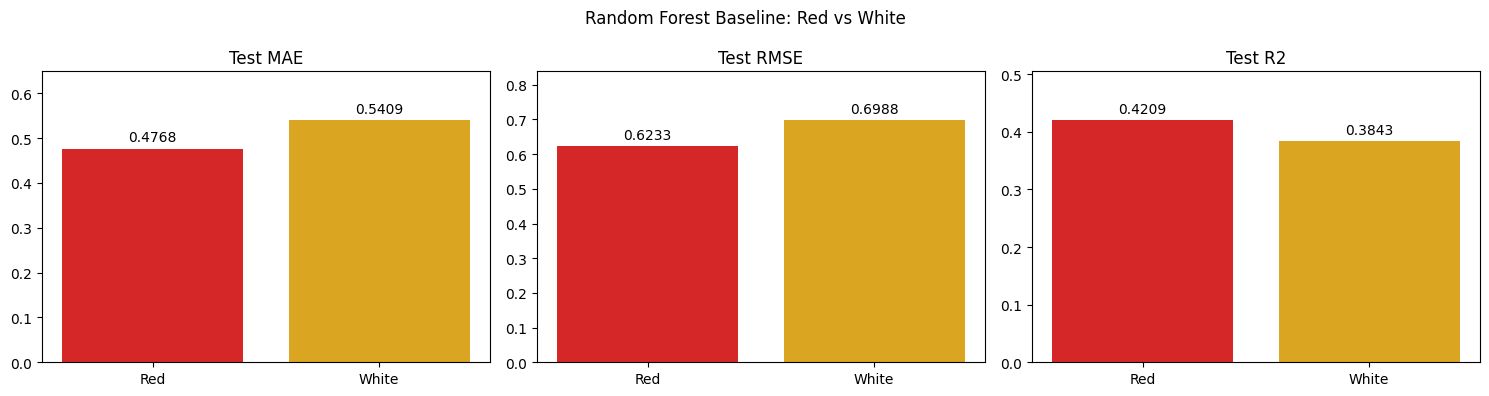

In [ ]:
compare_metric_rows('Random Forest Baseline: Red vs White', {'Test MAE':rf_mae,'Test RMSE':rf_rmse,'Test R2':rf_r2}, {'Test MAE':white_rf_mae,'Test RMSE':white_rf_rmse,'Test R2':white_rf_r2})

## 6. Baseline Model 4: Multi-Layer Perceptron (MLP) Neural Network

Train an MLP regression baseline in a StandardScaler pipeline. Its two hidden layers contain 32 and 16 neurons, with ReLU activation, Adam optimisation, alpha=0.001 and initial learning rate 0.001. Training allows up to 2,000 iterations and uses a 15% internal validation portion with early stopping after 30 iterations without sufficient improvement. The pipeline fits scaling on the outer training portion during CV, protecting the outer validation fold; the MLP internal early-stopping split occurs after that scaling step.

#### Red Wine — Calculations

In [ ]:
with capture_output() as _individual_output:
    from sklearn.neural_network import MLPRegressor
    from sklearn.preprocessing import StandardScaler
    from sklearn.pipeline import Pipeline

    # Create MLP pipeline
    mlp_model = Pipeline([
        ("scaler", StandardScaler()),
        ("mlp", MLPRegressor(
            hidden_layer_sizes=(32, 16),
            activation="relu",
            solver="adam",
            alpha=0.001,
            learning_rate_init=0.001,
            max_iter=2000,
            early_stopping=True,
            validation_fraction=0.15,
            n_iter_no_change=30,
            random_state=42
        ))
    ])

    # Train the neural network
    mlp_model.fit(X_train, y_train)

    # Predict wine quality
    y_pred_mlp = mlp_model.predict(X_test)

    print("MLP Neural Network training completed!")
    print("Red Wine first 10 predictions:")
    print(y_pred_mlp[:10])

    print("Training iterations:",
          mlp_model.named_steps["mlp"].n_iter_)

plt.close("all")

#### White Wine — Calculations

In [ ]:
with capture_output() as _individual_output:
    from sklearn.neural_network import MLPRegressor
    from sklearn.preprocessing import StandardScaler
    from sklearn.pipeline import Pipeline

    # Create MLP pipeline
    white_mlp_model = Pipeline([
        ("scaler", StandardScaler()),
        ("mlp", MLPRegressor(
            hidden_layer_sizes=(32, 16),
            activation="relu",
            solver="adam",
            alpha=0.001,
            learning_rate_init=0.001,
            max_iter=2000,
            early_stopping=True,
            validation_fraction=0.15,
            n_iter_no_change=30,
            random_state=42
        ))
    ])

    # Train the neural network
    white_mlp_model.fit(white_X_train, white_y_train)

    # Predict wine quality
    white_y_pred_mlp = white_mlp_model.predict(white_X_test)

    print("MLP Neural Network training completed!")
    print("White Wine first 10 predictions:")
    print(white_y_pred_mlp[:10])

    print("Training iterations:",
          white_mlp_model.named_steps["mlp"].n_iter_)

plt.close("all")

### 6.1 Baseline MLP Evaluation
Calculate test MAE, RMSE and R² from the fitted baseline MLP, together with its training R². Lower error and stronger test R² indicate better predictive performance.

#### Red Wine — Calculations

In [ ]:
with capture_output() as _individual_output:
    from sklearn.metrics import (
        mean_absolute_error,
        mean_squared_error,
        r2_score
    )
    import numpy as np

    # Test performance
    mlp_mae = mean_absolute_error(y_test, y_pred_mlp)
    mlp_rmse = np.sqrt(
        mean_squared_error(y_test, y_pred_mlp)
    )
    mlp_r2 = r2_score(y_test, y_pred_mlp)

    # Training performance
    y_train_pred_mlp = mlp_model.predict(X_train)

    mlp_train_r2 = r2_score(
        y_train, y_train_pred_mlp
    )

    print("Red Wine MLP Neural Network Results")
    print("--------------------------")
    print(f"MAE: {mlp_mae:.4f}")
    print(f"RMSE: {mlp_rmse:.4f}")
    print(f"Test R²: {mlp_r2:.4f}")
    print(f"Train R²: {mlp_train_r2:.4f}")

plt.close("all")

#### White Wine — Calculations

In [ ]:
with capture_output() as _individual_output:
    from sklearn.metrics import (
        mean_absolute_error,
        mean_squared_error,
        r2_score
    )
    import numpy as np

    # Test performance
    white_mlp_mae = mean_absolute_error(white_y_test, white_y_pred_mlp)
    white_mlp_rmse = np.sqrt(
        mean_squared_error(white_y_test, white_y_pred_mlp)
    )
    white_mlp_r2 = r2_score(white_y_test, white_y_pred_mlp)

    # Training performance
    white_y_train_pred_mlp = white_mlp_model.predict(white_X_train)

    white_mlp_train_r2 = r2_score(
        white_y_train, white_y_train_pred_mlp
    )

    print("White Wine MLP Neural Network Results")
    print("--------------------------")
    print(f"MAE: {white_mlp_mae:.4f}")
    print(f"RMSE: {white_mlp_rmse:.4f}")
    print(f"Test R²: {white_mlp_r2:.4f}")
    print(f"Train R²: {white_mlp_train_r2:.4f}")

plt.close("all")

#### Combined Results
Compare the red and white outputs below for this section. Lower MAE/RMSE and higher R² indicate better prediction where these metrics are shown. Cross-dataset differences are descriptive.

,Dataset,Test MAE,Test RMSE,Test R2
0,Red,0.5133,0.6757,0.3193
1,White,0.5833,0.7512,0.2885


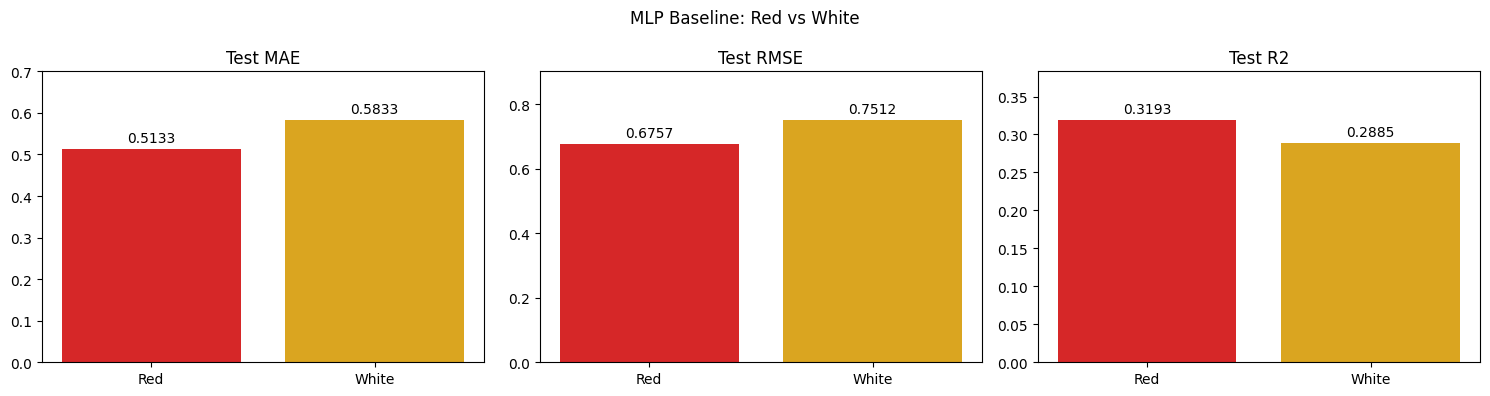

In [ ]:
compare_metric_rows('MLP Baseline: Red vs White', {'Test MAE':mlp_mae,'Test RMSE':mlp_rmse,'Test R2':mlp_r2}, {'Test MAE':white_mlp_mae,'Test RMSE':white_mlp_rmse,'Test R2':white_mlp_r2})

## 6B. Gradient Boosting Setup
Reuse the red and white train/test splits from Section 2, define matching shuffled five-fold KFold settings (random_state=42), and create folders for boosting figures. Keeping these settings consistent enables comparisons with the other methods within each dataset. This setup does not combine red and white observations into one training set.

#### Red Wine — Calculations

In [ ]:
with capture_output() as _individual_output:
    import os
    import numpy as np
    import pandas as pd
    from sklearn.model_selection import KFold

    # X_train, X_test, y_train, y_test come from Section 2 (Dataset Splitting & Preparation)
    print("Training set:", X_train.shape, "| Test set:", X_test.shape)

    # same cross-validation strategy as Sections 4-8
    cv = KFold(n_splits=5, shuffle=True, random_state=42)

    # folder for saved figures
    FIG_DIR = "figures_boosting"
    os.makedirs(FIG_DIR, exist_ok=True)

plt.close("all")

#### White Wine — Calculations

In [ ]:
with capture_output() as _individual_output:
    import os
    import numpy as np
    import pandas as pd
    from sklearn.model_selection import KFold

    # X_train, X_test, y_train, y_test come from Section 2 (Dataset Splitting & Preparation)
    print("Training set:", white_X_train.shape, "| Test set:", white_X_test.shape)

    # same cross-validation strategy as Sections 4-8
    white_cv = KFold(n_splits=5, shuffle=True, random_state=42)

    # folder for saved figures
    white_FIG_DIR = "figures_boosting_white"
    os.makedirs(white_FIG_DIR, exist_ok=True)

plt.close("all")

## 6B. Baseline Model 5: Gradient Boosting Regression

Random Forest (Section 5) reduces the variance of decision trees by bagging, which trains many
deep trees independently on bootstrap samples and averages them.

Gradient boosting attacks
the bias instead. It builds shallow trees sequentially, where each new tree is fitted to the
residual errors of the ensemble so far, and its contribution is scaled down by a learning rate
(shrinkage). The final prediction is the sum of all trees. Because every tree corrects the
previous ones, boosting can keep improving where a single tree or a bagged ensemble plateaus, but
it will also start fitting noise if too many stages are added, so the number of stages and the
learning rate must be chosen by cross-validation.

The scikit-learn implementation `GradientBoostingRegressor` is used so the notebook has no extra
dependencies. Default settings: 100 stages, learning rate 0.1, tree depth 3, squared-error loss.

#### Red Wine — Calculations

In [ ]:
with capture_output() as _individual_output:
    from sklearn.ensemble import GradientBoostingRegressor

    # create Gradient Boosting model with default hyperparameters
    gb_model = GradientBoostingRegressor(random_state=42)

    # train the model
    gb_model.fit(X_train, y_train)

    # predict wine quality for test data
    y_pred_gb = gb_model.predict(X_test)

    print("Gradient Boosting training completed!")
    print("Stages:", gb_model.n_estimators_, "| learning rate:", gb_model.learning_rate,
          "| max depth:", gb_model.max_depth)
    print("First 10 predictions:")
    print(y_pred_gb[:10])

plt.close("all")

In [ ]:
with capture_output() as _individual_output:
    from sklearn.metrics import (
        mean_absolute_error,
        mean_squared_error,
        r2_score
    )
    import numpy as np

    # test performance
    gb_mae = mean_absolute_error(y_test, y_pred_gb)
    gb_rmse = np.sqrt(mean_squared_error(y_test, y_pred_gb))
    gb_r2 = r2_score(y_test, y_pred_gb)

    # training performance
    y_train_pred_gb = gb_model.predict(X_train)
    gb_train_r2 = r2_score(y_train, y_train_pred_gb)

    print("Gradient Boosting Results")
    print("-------------------------")
    print(f"MAE: {gb_mae:.4f}")
    print(f"RMSE: {gb_rmse:.4f}")
    print(f"Test R²: {gb_r2:.4f}")
    print(f"Train R²: {gb_train_r2:.4f}")

plt.close("all")

In [ ]:
with capture_output() as _individual_output:
    import matplotlib.pyplot as plt

    plt.figure(figsize=(7, 5))
    plt.scatter(y_test, y_pred_gb, alpha=0.5)
    plt.plot([3, 8], [3, 8], linestyle="--", color="red", label="Perfect Prediction")
    plt.xlabel("Actual Wine Quality")
    plt.ylabel("Predicted Wine Quality")
    plt.title("Gradient Boosting: Actual vs Predicted")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig(f"{FIG_DIR}/gb_actual_vs_predicted.png", dpi=300, bbox_inches="tight")
    plt.show()

plt.close("all")

In [ ]:
with capture_output() as _individual_output:
    gb_row = {"Model": "Gradient Boosting", "Train R2": gb_train_r2,
              "Test MAE": gb_mae, "Test RMSE": gb_rmse, "Test R2": gb_r2}
    display(pd.DataFrame([gb_row]).round(4))

plt.close("all")

#### White Wine — Calculations

In [ ]:
with capture_output() as _individual_output:
    from sklearn.ensemble import GradientBoostingRegressor

    # create Gradient Boosting model with default hyperparameters
    white_gb_model = GradientBoostingRegressor(random_state=42)

    # train the model
    white_gb_model.fit(white_X_train, white_y_train)

    # predict wine quality for test data
    white_y_pred_gb = white_gb_model.predict(white_X_test)

    print("Gradient Boosting training completed!")
    print("Stages:", white_gb_model.n_estimators_, "| learning rate:", white_gb_model.learning_rate,
          "| max depth:", white_gb_model.max_depth)
    print("First 10 predictions:")
    print(white_y_pred_gb[:10])

plt.close("all")

In [ ]:
with capture_output() as _individual_output:
    from sklearn.metrics import (
        mean_absolute_error,
        mean_squared_error,
        r2_score
    )
    import numpy as np

    # test performance
    white_gb_mae = mean_absolute_error(white_y_test, white_y_pred_gb)
    white_gb_rmse = np.sqrt(mean_squared_error(white_y_test, white_y_pred_gb))
    white_gb_r2 = r2_score(white_y_test, white_y_pred_gb)

    # training performance
    white_y_train_pred_gb = white_gb_model.predict(white_X_train)
    white_gb_train_r2 = r2_score(white_y_train, white_y_train_pred_gb)

    print("Gradient Boosting Results")
    print("-------------------------")
    print(f"MAE: {white_gb_mae:.4f}")
    print(f"RMSE: {white_gb_rmse:.4f}")
    print(f"Test R²: {white_gb_r2:.4f}")
    print(f"Train R²: {white_gb_train_r2:.4f}")

plt.close("all")

In [ ]:
with capture_output() as _individual_output:
    import matplotlib.pyplot as plt

    plt.figure(figsize=(7, 5))
    plt.scatter(white_y_test, white_y_pred_gb, alpha=0.5)
    plt.plot([3, 9], [3, 9], linestyle="--", color="red", label="Perfect Prediction")
    plt.xlabel("Actual Wine Quality")
    plt.ylabel("Predicted Wine Quality")
    plt.title("Gradient Boosting: Actual vs Predicted")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig(f"{white_FIG_DIR}/gb_actual_vs_predicted.png", dpi=300, bbox_inches="tight")
    plt.show()

plt.close("all")

In [ ]:
with capture_output() as _individual_output:
    white_gb_row = {"Model": "Gradient Boosting", "Train R2": white_gb_train_r2,
              "Test MAE": white_gb_mae, "Test RMSE": white_gb_rmse, "Test R2": white_gb_r2}
    display(pd.DataFrame([white_gb_row]).round(4))

plt.close("all")

#### Combined Results
Red and white results are displayed together. Different metrics have separate panels. Cross-dataset differences are descriptive; fold variation is not a significance test.

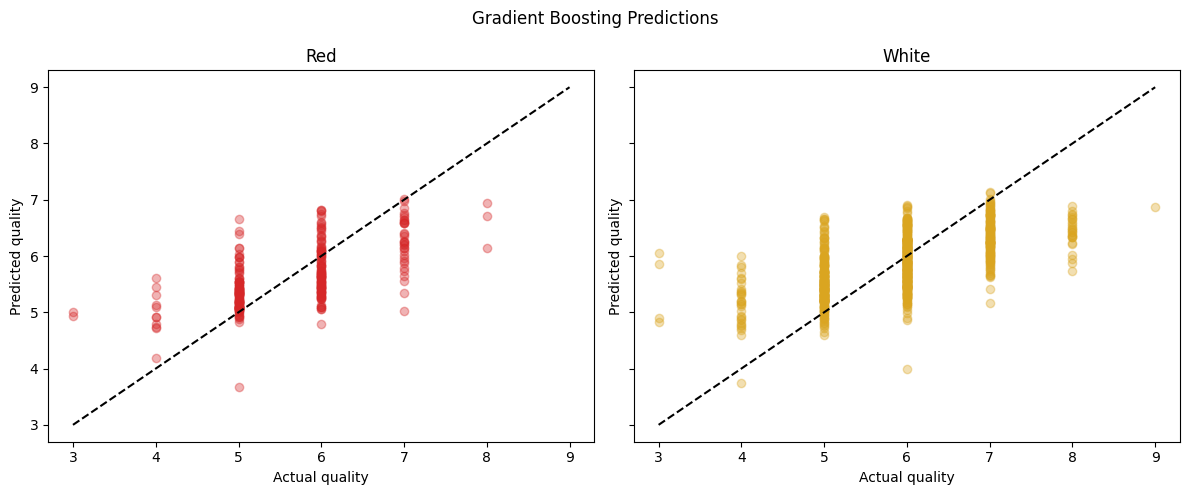

In [ ]:
compare_predictions('Gradient Boosting Predictions',y_test,y_pred_gb,white_y_test,white_y_pred_gb)

,Dataset,Test MAE,Test RMSE,Test R2
0,Red,0.4963,0.6343,0.4003
1,White,0.5510,0.7041,0.3751


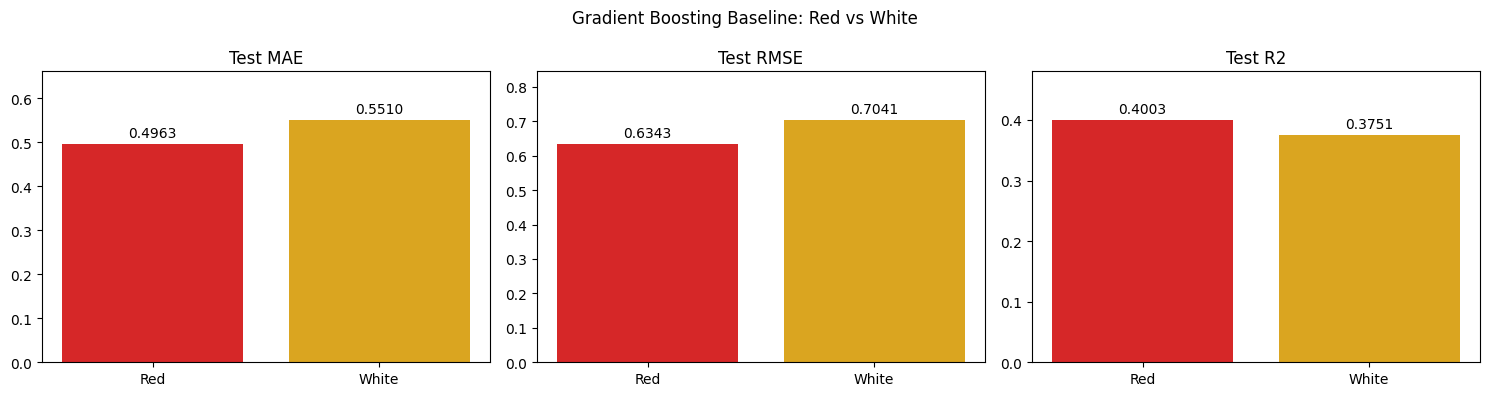

In [ ]:
compare_metric_rows('Gradient Boosting Baseline: Red vs White', {'Test MAE':gb_mae,'Test RMSE':gb_rmse,'Test R2':gb_r2}, {'Test MAE':white_gb_mae,'Test RMSE':white_gb_rmse,'Test R2':white_gb_r2})

### 6B.1 Five-Fold Cross-Validation

Evaluate baseline Gradient Boosting with the same five-fold training-set CV strategy used for all six baselines in Section 7. Report mean training R², mean validation R², its fold standard deviation and mean validation MAE. The validation MAE is converted from scikit-learn's negative scoring convention to a positive error. Fold standard deviation describes variation across folds; it is not a confidence interval or significance test.

#### Red Wine — Calculations

In [ ]:
with capture_output() as _individual_output:
    from sklearn.model_selection import cross_validate
    from sklearn.base import clone

    scores = cross_validate(
        clone(gb_model),
        X_train,
        y_train,
        cv=cv,
        scoring={"mae": "neg_mean_absolute_error", "r2": "r2"},
        return_train_score=True,
        n_jobs=-1
    )

    gb_cv_row = {
        "Model": "Gradient Boosting",
        "Train R2": scores["train_r2"].mean(),
        "CV R2": scores["test_r2"].mean(),
        "CV R2 Std": scores["test_r2"].std(),
        "CV MAE": -scores["test_mae"].mean(),
    }
    gb_cv_mae_std = (-scores["test_mae"]).std()


    print("Gradient Boosting baseline CV:")
    display(pd.DataFrame([gb_cv_row]).round(4))

plt.close("all")

#### White Wine — Calculations

In [ ]:
with capture_output() as _individual_output:
    from sklearn.model_selection import cross_validate
    from sklearn.base import clone

    white_scores = cross_validate(
        clone(white_gb_model),
        white_X_train,
        white_y_train,
        cv=white_cv,
        scoring={"mae": "neg_mean_absolute_error", "r2": "r2"},
        return_train_score=True,
        n_jobs=-1
    )

    white_gb_cv_row = {
        "Model": "Gradient Boosting",
        "Train R2": white_scores["train_r2"].mean(),
        "CV R2": white_scores["test_r2"].mean(),
        "CV R2 Std": white_scores["test_r2"].std(),
        "CV MAE": -white_scores["test_mae"].mean(),
    }
    white_gb_cv_mae_std = (-white_scores["test_mae"]).std()


    print("Gradient Boosting baseline CV:")
    display(pd.DataFrame([white_gb_cv_row]).round(4))

plt.close("all")

## 6C. Baseline Model 6: KNN Regression

KNN is a distance based model. It does not learn any parameters in training, it just saves the training data. When we predict a new wine, it finds the k closest wines in the training set and use the average of their quality as the prediction.

Since KNN uses distance, the scale of features is very important. For example total sulfur dioxide values are around 10 to 200, but density only changes very little (like 0.99 to 1.00). If we don't scale, the big range features will decide most of the distance. So we use StandardScaler in a pipeline like the MLP model, so the scaler is only fit on training data.

For the baseline we use the default settings in scikit-learn (k = 5, uniform weights, Euclidean distance).

#### Red Wine — Calculations

In [ ]:
with capture_output() as _individual_output:
    from sklearn.neighbors import KNeighborsRegressor
    from sklearn.preprocessing import StandardScaler
    from sklearn.pipeline import Pipeline
    from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
    from sklearn.model_selection import KFold, cross_validate
    from sklearn.base import clone
    import matplotlib.pyplot as plt
    import numpy as np
    import pandas as pd
    import os

    KNN_FIG_DIR = "figures_knn"
    os.makedirs(KNN_FIG_DIR, exist_ok=True)

    # KNN pipeline: scale features first, then KNN with default settings
    knn_model = Pipeline([
        ("scaler", StandardScaler()),
        ("knn", KNeighborsRegressor(n_neighbors=5, weights="uniform", p=2))
    ])

    knn_model.fit(X_train, y_train)
    y_pred_knn = knn_model.predict(X_test)

    # Test performance
    knn_mae = mean_absolute_error(y_test, y_pred_knn)
    knn_rmse = np.sqrt(mean_squared_error(y_test, y_pred_knn))
    knn_r2 = r2_score(y_test, y_pred_knn)

    # Training performance
    knn_train_r2 = r2_score(y_train, knn_model.predict(X_train))

    print("Red Wine KNN Results")
    print("--------------------")
    print(f"MAE: {knn_mae:.4f}")
    print(f"RMSE: {knn_rmse:.4f}")
    print(f"Test R²: {knn_r2:.4f}")
    print(f"Train R²: {knn_train_r2:.4f}")

    # Actual vs predicted
    plt.figure(figsize=(7, 5))
    plt.scatter(y_test, y_pred_knn, alpha=0.5)
    plt.plot([3, 8], [3, 8], linestyle="--", color="red", label="Perfect Prediction")
    plt.xlabel("Actual Wine Quality")
    plt.ylabel("Predicted Wine Quality")
    plt.title("Red Wine KNN (k=5): Actual vs Predicted")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig(f"{KNN_FIG_DIR}/knn_actual_vs_predicted.png", dpi=300, bbox_inches="tight")
    plt.show()

    knn_cv = KFold(n_splits=5, shuffle=True, random_state=42)

    knn_scores = cross_validate(
        clone(knn_model), X_train, y_train, cv=knn_cv,
        scoring={"mae": "neg_mean_absolute_error", "r2": "r2"},
        return_train_score=True
    )

    knn_cv_row = {
        "Model": "KNN",
        "Train R2": knn_scores["train_r2"].mean(),
        "CV R2": knn_scores["test_r2"].mean(),
        "CV R2 Std": knn_scores["test_r2"].std(),
        "CV MAE": -knn_scores["test_mae"].mean(),
    }
    knn_cv_mae_std = (-knn_scores["test_mae"]).std()

    print("\nRed Wine KNN 5-Fold Cross-Validation:")
    display(pd.DataFrame([knn_cv_row]).round(4))
    print(f"CV MAE per fold: {np.round(-knn_scores['test_mae'], 4)}  (std {knn_cv_mae_std:.4f})")

plt.close("all")

#### White Wine — Calculations

In [ ]:
with capture_output() as _individual_output:
    from sklearn.neighbors import KNeighborsRegressor
    from sklearn.preprocessing import StandardScaler
    from sklearn.pipeline import Pipeline
    from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
    from sklearn.model_selection import KFold, cross_validate
    from sklearn.base import clone
    import matplotlib.pyplot as plt
    import numpy as np
    import pandas as pd
    import os

    white_KNN_FIG_DIR = "figures_knn_white"
    os.makedirs(white_KNN_FIG_DIR, exist_ok=True)

    # KNN pipeline: scale features first, then KNN with default settings
    white_knn_model = Pipeline([
        ("scaler", StandardScaler()),
        ("knn", KNeighborsRegressor(n_neighbors=5, weights="uniform", p=2))
    ])

    white_knn_model.fit(white_X_train, white_y_train)
    white_y_pred_knn = white_knn_model.predict(white_X_test)

    # Test performance
    white_knn_mae = mean_absolute_error(white_y_test, white_y_pred_knn)
    white_knn_rmse = np.sqrt(mean_squared_error(white_y_test, white_y_pred_knn))
    white_knn_r2 = r2_score(white_y_test, white_y_pred_knn)

    # Training performance
    white_knn_train_r2 = r2_score(white_y_train, white_knn_model.predict(white_X_train))

    print("White Wine KNN Results")
    print("--------------------")
    print(f"MAE: {white_knn_mae:.4f}")
    print(f"RMSE: {white_knn_rmse:.4f}")
    print(f"Test R²: {white_knn_r2:.4f}")
    print(f"Train R²: {white_knn_train_r2:.4f}")

    # Actual vs predicted
    plt.figure(figsize=(7, 5))
    plt.scatter(white_y_test, white_y_pred_knn, alpha=0.5)
    plt.plot([3, 9], [3, 9], linestyle="--", color="red", label="Perfect Prediction")
    plt.xlabel("Actual Wine Quality")
    plt.ylabel("Predicted Wine Quality")
    plt.title("White Wine KNN (k=5): Actual vs Predicted")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig(f"{white_KNN_FIG_DIR}/knn_actual_vs_predicted.png", dpi=300, bbox_inches="tight")
    plt.show()

    white_knn_cv = KFold(n_splits=5, shuffle=True, random_state=42)

    white_knn_scores = cross_validate(
        clone(white_knn_model), white_X_train, white_y_train, cv=white_knn_cv,
        scoring={"mae": "neg_mean_absolute_error", "r2": "r2"},
        return_train_score=True
    )

    white_knn_cv_row = {
        "Model": "KNN",
        "Train R2": white_knn_scores["train_r2"].mean(),
        "CV R2": white_knn_scores["test_r2"].mean(),
        "CV R2 Std": white_knn_scores["test_r2"].std(),
        "CV MAE": -white_knn_scores["test_mae"].mean(),
    }
    white_knn_cv_mae_std = (-white_knn_scores["test_mae"]).std()

    print("\nWhite Wine KNN 5-Fold Cross-Validation:")
    display(pd.DataFrame([white_knn_cv_row]).round(4))
    print(f"CV MAE per fold: {np.round(-white_knn_scores['test_mae'], 4)}  (std {white_knn_cv_mae_std:.4f})")

plt.close("all")

#### Combined Results
Red and white results are displayed together. Different metrics have separate panels. Cross-dataset differences are descriptive; fold variation is not a significance test.

,Dataset,CV MAE,CV R2
0,Red,0.5445,0.2484
1,White,0.5777,0.2789


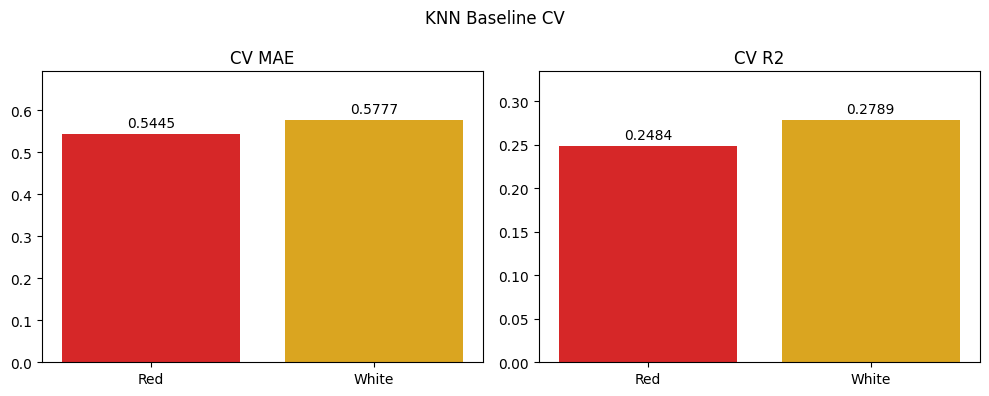

In [ ]:
compare_metric_rows('KNN Baseline CV',{'CV MAE':knn_cv_row['CV MAE'],'CV R2':knn_cv_row['CV R2']},{'CV MAE':white_knn_cv_row['CV MAE'],'CV R2':white_knn_cv_row['CV R2']})

,Dataset,Test MAE,Test RMSE,Test R2
0,Red,0.5265,0.6871,0.2963
1,White,0.5849,0.7663,0.2598


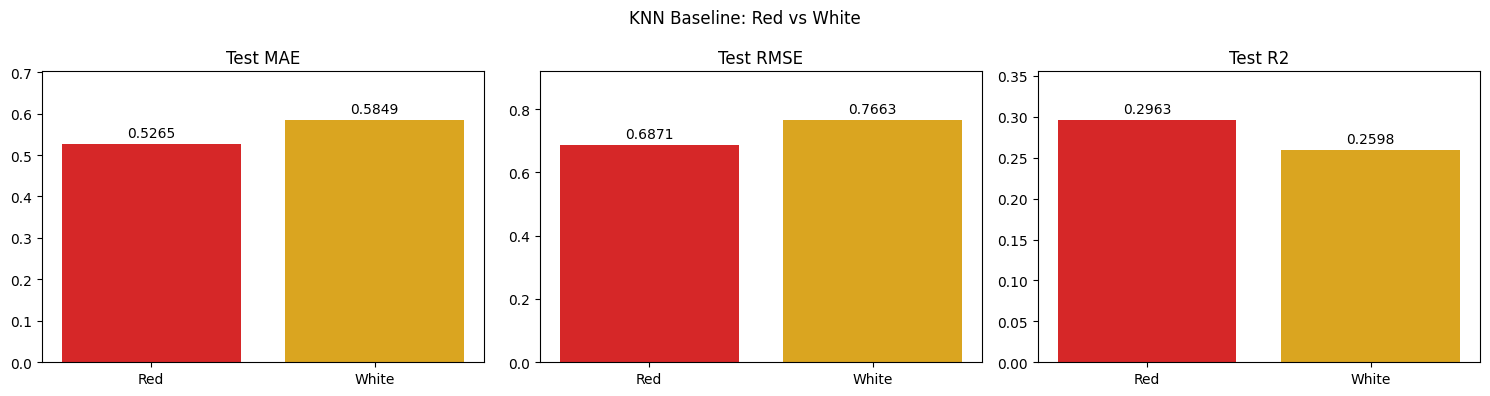

In [ ]:
compare_metric_rows('KNN Baseline: Red vs White', {'Test MAE':knn_mae,'Test RMSE':knn_rmse,'Test R2':knn_r2}, {'Test MAE':white_knn_mae,'Test RMSE':white_knn_rmse,'Test R2':white_knn_r2})

## 7. Comparative Evaluation of Six Baselines
Collect holdout metrics for Linear Regression, Decision Tree, Random Forest, MLP, Gradient Boosting and KNN separately for each dataset, then compare their training-set CV results. MAE measures average absolute error in quality-score points; RMSE gives greater weight to large errors; R² compares predictions with the mean of the evaluated targets and can be negative. Lower MAE/RMSE and higher R² are better. Differences between red and white results are descriptive because the datasets have different sample sizes and target distributions.

#### Red Wine — Calculations

In [ ]:
with capture_output() as _individual_output:
    import pandas as pd

    results_df = pd.DataFrame([
        {
            "Model": "Linear Regression",
            "MAE": lr_mae,
            "RMSE": lr_rmse,
            "R2": lr_r2
        },
        {
            "Model": "Decision Tree",
            "MAE": dt_mae,
            "RMSE": dt_rmse,
            "R2": dt_r2
        },
        {
            "Model": "Random Forest",
            "MAE": rf_mae,
            "RMSE": rf_rmse,
            "R2": rf_r2
        },
        {
            "Model": "MLP Neural Network",
            "MAE": mlp_mae,
            "RMSE": mlp_rmse,
            "R2": mlp_r2
        }
    ,
        {"Model": "Gradient Boosting", "MAE": gb_mae, "RMSE": gb_rmse, "R2": gb_r2},
        {"Model": "KNN", "MAE": knn_mae, "RMSE": knn_rmse, "R2": knn_r2}
    ])

    print("Red Wine Model Comparison:")
    display(results_df.round(4))

plt.close("all")

#### White Wine — Calculations

In [ ]:
with capture_output() as _individual_output:
    import pandas as pd

    white_results_df = pd.DataFrame([
        {
            "Model": "Linear Regression",
            "MAE": white_lr_mae,
            "RMSE": white_lr_rmse,
            "R2": white_lr_r2
        },
        {
            "Model": "Decision Tree",
            "MAE": white_dt_mae,
            "RMSE": white_dt_rmse,
            "R2": white_dt_r2
        },
        {
            "Model": "Random Forest",
            "MAE": white_rf_mae,
            "RMSE": white_rf_rmse,
            "R2": white_rf_r2
        },
        {
            "Model": "MLP Neural Network",
            "MAE": white_mlp_mae,
            "RMSE": white_mlp_rmse,
            "R2": white_mlp_r2
        }
    ,
        {"Model": "Gradient Boosting", "MAE": white_gb_mae, "RMSE": white_gb_rmse, "R2": white_gb_r2},
        {"Model": "KNN", "MAE": white_knn_mae, "RMSE": white_knn_rmse, "R2": white_knn_r2}
    ])

    print("White Wine Model Comparison:")
    display(white_results_df.round(4))

plt.close("all")

### 7.1 Five-Fold Training-Set Cross-Validation
Use five shuffled folds with random_state=42 within each training dataset. Each baseline is refitted on four folds and validated on the remaining fold, repeating until every fold has served as validation. Scaling remains inside model pipelines. Compare mean CV MAE as the main selection measure and R² as a complementary measure. Fold standard deviations do not establish statistical significance; the selected models' reused CV scores are not independent estimates of the complete selection procedure.

#### Red Wine — Calculations

In [ ]:
with capture_output() as _individual_output:
    from sklearn.model_selection import KFold, cross_validate
    from sklearn.base import clone
    import pandas as pd

    # Five-fold cross-validation
    cv = KFold(
        n_splits=5,
        shuffle=True,
        random_state=42
    )

    # Our six baseline models
    models_cv = {
        "Linear Regression": lr_model,
        "Decision Tree": dt_model,
        "Random Forest": rf_model,
        "MLP Neural Network": mlp_model,
        "Gradient Boosting": gb_model,
        "KNN": knn_model
    }

    cv_results = []

    for name, model in models_cv.items():

        scores = cross_validate(
            clone(model),
            X_train,
            y_train,
            cv=cv,
            scoring={
                "mae": "neg_mean_absolute_error",
                "r2": "r2"
            },
            return_train_score=True
        )

        cv_results.append({
            "Model": name,
            "Train R2": scores["train_r2"].mean(),
            "CV R2": scores["test_r2"].mean(),
            "CV R2 Std": scores["test_r2"].std(),
            "CV MAE": -scores["test_mae"].mean()
        })

    cv_results_df = pd.DataFrame(cv_results)

    print("Red Wine 5-Fold Cross-Validation Results:")
    display(cv_results_df.round(4))

plt.close("all")

#### White Wine — Calculations

In [ ]:
with capture_output() as _individual_output:
    from sklearn.model_selection import KFold, cross_validate
    from sklearn.base import clone
    import pandas as pd

    # Five-fold cross-validation
    white_cv = KFold(
        n_splits=5,
        shuffle=True,
        random_state=42
    )

    # Our six baseline models
    white_models_cv = {
        "Linear Regression": white_lr_model,
        "Decision Tree": white_dt_model,
        "Random Forest": white_rf_model,
        "MLP Neural Network": white_mlp_model,
        "Gradient Boosting": white_gb_model,
        "KNN": white_knn_model
    }

    white_cv_results = []

    for white_name, white_model in white_models_cv.items():

        white_scores = cross_validate(
            clone(white_model),
            white_X_train,
            white_y_train,
            cv=white_cv,
            scoring={
                "mae": "neg_mean_absolute_error",
                "r2": "r2"
            },
            return_train_score=True
        )

        white_cv_results.append({
            "Model": white_name,
            "Train R2": white_scores["train_r2"].mean(),
            "CV R2": white_scores["test_r2"].mean(),
            "CV R2 Std": white_scores["test_r2"].std(),
            "CV MAE": -white_scores["test_mae"].mean()
        })

    white_cv_results_df = pd.DataFrame(white_cv_results)

    print("White Wine 5-Fold Cross-Validation Results:")
    display(white_cv_results_df.round(4))

plt.close("all")

#### Combined Results
Red and white results are displayed together. Different metrics have separate panels. Cross-dataset differences are descriptive; fold variation is not a significance test.

,Model,Train R2,CV R2,CV R2 Std,CV MAE,Dataset
0,Linear Regression,0.3614,0.3410,0.0279,0.5160,Red
1,Decision Tree,1.0000,-0.1457,0.1356,0.5723,Red
2,Random Forest,0.9099,0.3771,0.0522,0.4968,Red
3,MLP Neural Network,0.4966,0.2196,0.0660,0.5541,Red
4,Gradient Boosting,0.6776,0.3496,0.0517,0.5114,Red
5,KNN,0.5042,0.2484,0.0759,0.5445,Red
6,Linear Regression,0.3056,0.2977,0.0186,0.5776,White
7,Decision Tree,1.0000,-0.3125,0.1131,0.7080,White
8,Random Forest,0.9103,0.3693,0.0237,0.5429,White
9,MLP Neural Network,0.4385,0.3203,0.0340,0.5688,White


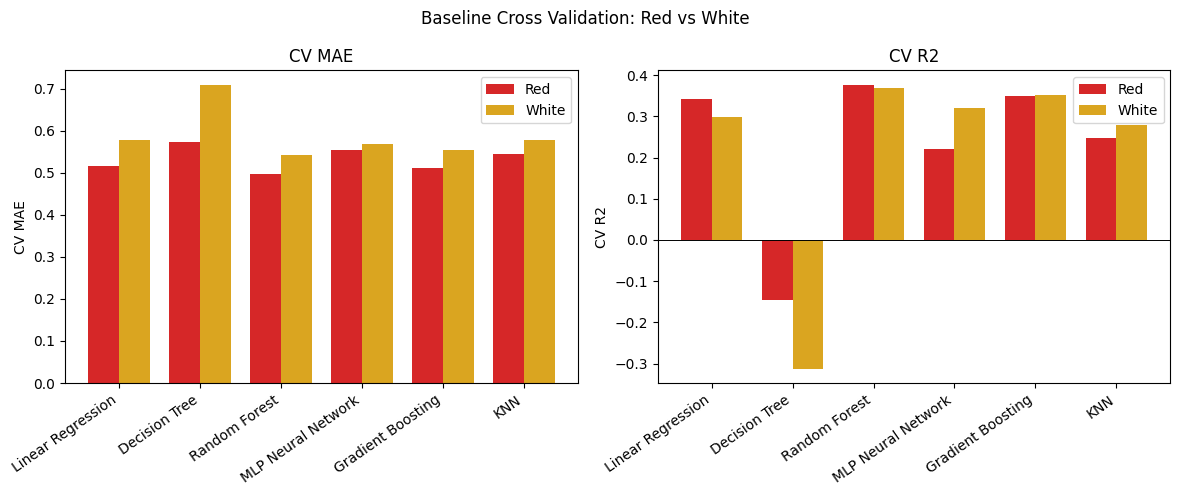

In [ ]:
compare_tables('Baseline Cross Validation: Red vs White',cv_results_df,white_cv_results_df,'Model',['CV MAE', 'CV R2'])

### 8.1 MLP Architecture Search

Compare four MLP architectures: (16,), (32,), (32, 16) and (64, 32), keeping the other training settings fixed. Each tuple gives the neuron counts in successive hidden layers. Five-fold CV with scaling inside the pipeline investigates how network width and layer count affect prediction. Additional neurons or layers do not guarantee lower validation error.

#### Red Wine — Calculations

In [ ]:
with capture_output() as _individual_output:
    from sklearn.neural_network import MLPRegressor
    from sklearn.preprocessing import StandardScaler
    from sklearn.pipeline import Pipeline
    from sklearn.model_selection import KFold, cross_validate
    import pandas as pd

    # Architectures to investigate
    architectures = [
        (16,),
        (32,),
        (32, 16),
        (64, 32)
    ]

    # 5-fold cross-validation
    cv = KFold(
        n_splits=5,
        shuffle=True,
        random_state=42
    )

    mlp_arch_results = []

    for architecture in architectures:

        model = Pipeline([
            ("scaler", StandardScaler()),
            ("mlp", MLPRegressor(
                hidden_layer_sizes=architecture,
                activation="relu",
                solver="adam",
                alpha=0.001,
                learning_rate_init=0.001,
                max_iter=2000,
                early_stopping=True,
                validation_fraction=0.15,
                n_iter_no_change=30,
                random_state=42
            ))
        ])

        scores = cross_validate(
            model,
            X_train,
            y_train,
            cv=cv,
            scoring={
                "mae": "neg_mean_absolute_error",
                "r2": "r2"
            },
            return_train_score=True
        )

        mlp_arch_results.append({
            "Architecture": str(architecture),
            "Train R2": scores["train_r2"].mean(),
            "CV R2": scores["test_r2"].mean(),
            "CV R2 Std": scores["test_r2"].std(),
            "CV MAE": -scores["test_mae"].mean()
        })

    mlp_arch_df = pd.DataFrame(mlp_arch_results)

    print("Red Wine MLP Architecture Comparison:")
    display(mlp_arch_df.round(4))

plt.close("all")

In [ ]:
with capture_output() as _individual_output:
    import matplotlib.pyplot as plt

    fig, ax = plt.subplots(figsize=(9, 5))

    bars = ax.bar(
        mlp_arch_df["Architecture"],
        mlp_arch_df["CV R2"]
    )

    ax.bar_label(bars, fmt="%.4f", padding=3)

    ax.set_xlabel("MLP Hidden Layer Architecture")
    ax.set_ylabel("Cross-Validation R2")
    ax.set_title(
        "Effect of Neural Network Architecture on Performance - Red Wine"
    )

    ax.axhline(0, linewidth=0.8)
    plt.tight_layout()

    plt.savefig(
        "red_wine_mlp_architecture_comparison.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

plt.close("all")

#### White Wine — Calculations

In [ ]:
with capture_output() as _individual_output:
    from sklearn.neural_network import MLPRegressor
    from sklearn.preprocessing import StandardScaler
    from sklearn.pipeline import Pipeline
    from sklearn.model_selection import KFold, cross_validate
    import pandas as pd

    # Architectures to investigate
    white_architectures = [
        (16,),
        (32,),
        (32, 16),
        (64, 32)
    ]

    # 5-fold cross-validation
    white_cv = KFold(
        n_splits=5,
        shuffle=True,
        random_state=42
    )

    white_mlp_arch_results = []

    for white_architecture in white_architectures:

        white_model = Pipeline([
            ("scaler", StandardScaler()),
            ("mlp", MLPRegressor(
                hidden_layer_sizes=white_architecture,
                activation="relu",
                solver="adam",
                alpha=0.001,
                learning_rate_init=0.001,
                max_iter=2000,
                early_stopping=True,
                validation_fraction=0.15,
                n_iter_no_change=30,
                random_state=42
            ))
        ])

        white_scores = cross_validate(
            white_model,
            white_X_train,
            white_y_train,
            cv=white_cv,
            scoring={
                "mae": "neg_mean_absolute_error",
                "r2": "r2"
            },
            return_train_score=True
        )

        white_mlp_arch_results.append({
            "Architecture": str(white_architecture),
            "Train R2": white_scores["train_r2"].mean(),
            "CV R2": white_scores["test_r2"].mean(),
            "CV R2 Std": white_scores["test_r2"].std(),
            "CV MAE": -white_scores["test_mae"].mean()
        })

    white_mlp_arch_df = pd.DataFrame(white_mlp_arch_results)

    print("White Wine MLP Architecture Comparison:")
    display(white_mlp_arch_df.round(4))

plt.close("all")

In [ ]:
with capture_output() as _individual_output:
    import matplotlib.pyplot as plt

    white_fig, white_ax = plt.subplots(figsize=(9, 5))

    white_bars = white_ax.bar(
        white_mlp_arch_df["Architecture"],
        white_mlp_arch_df["CV R2"]
    )

    white_ax.bar_label(white_bars, fmt="%.4f", padding=3)

    white_ax.set_xlabel("MLP Hidden Layer Architecture")
    white_ax.set_ylabel("Cross-Validation R2")
    white_ax.set_title(
        "Effect of Neural Network Architecture on Performance - White Wine"
    )

    white_ax.axhline(0, linewidth=0.8)
    plt.tight_layout()

    plt.savefig(
        "white_wine_mlp_architecture_comparison.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

plt.close("all")

#### 8.1.1 Best MLP Architecture
Select the architecture with the lowest mean CV MAE separately for red and white wine. Report its architecture and associated CV R² for context. Section 9 refits each selected architecture on its full training dataset before calculating test metrics. The selection CV score may be optimistic because it is also used to choose the architecture.

#### Red Wine — Calculations

In [ ]:
with capture_output() as _individual_output:
    # Identify best architecture based on CV MAE
    best_idx = mlp_arch_df["CV MAE"].idxmin()

    best_architecture = architectures[best_idx]
    best_row = mlp_arch_df.loc[best_idx]

    print("Red Wine Best Architecture:", best_architecture)
    print(f"Red Wine Best CV MAE: {best_row['CV MAE']:.4f}")
    print(f"Red Wine CV R2: {best_row['CV R2']:.4f}")

plt.close("all")

#### White Wine — Calculations

In [ ]:
with capture_output() as _individual_output:
    # Identify best architecture based on CV MAE
    white_best_idx = white_mlp_arch_df["CV MAE"].idxmin()

    white_best_architecture = white_architectures[white_best_idx]
    white_best_row = white_mlp_arch_df.loc[white_best_idx]

    print("White Wine Best Architecture:", white_best_architecture)
    print(f"White Wine Best CV MAE: {white_best_row['CV MAE']:.4f}")
    print(f"White Wine CV R2: {white_best_row['CV R2']:.4f}")

plt.close("all")

#### Combined Results
Red and white results are displayed together. Different metrics have separate panels. Cross-dataset differences are descriptive; fold variation is not a significance test.

,Architecture,Train R2,CV R2,CV R2 Std,CV MAE,Dataset
0,"(16,)",0.4536,0.2543,0.0864,0.5459,Red
1,"(32,)",0.5030,0.2633,0.0823,0.5502,Red
2,"(32, 16)",0.4966,0.2196,0.0660,0.5541,Red
3,"(64, 32)",0.4800,0.2666,0.0646,0.5423,Red
4,"(16,)",0.3812,0.2971,0.0200,0.5824,White
5,"(32,)",0.4229,0.3127,0.0311,0.5723,White
6,"(32, 16)",0.4385,0.3203,0.0340,0.5688,White
7,"(64, 32)",0.4500,0.3193,0.0163,0.5683,White


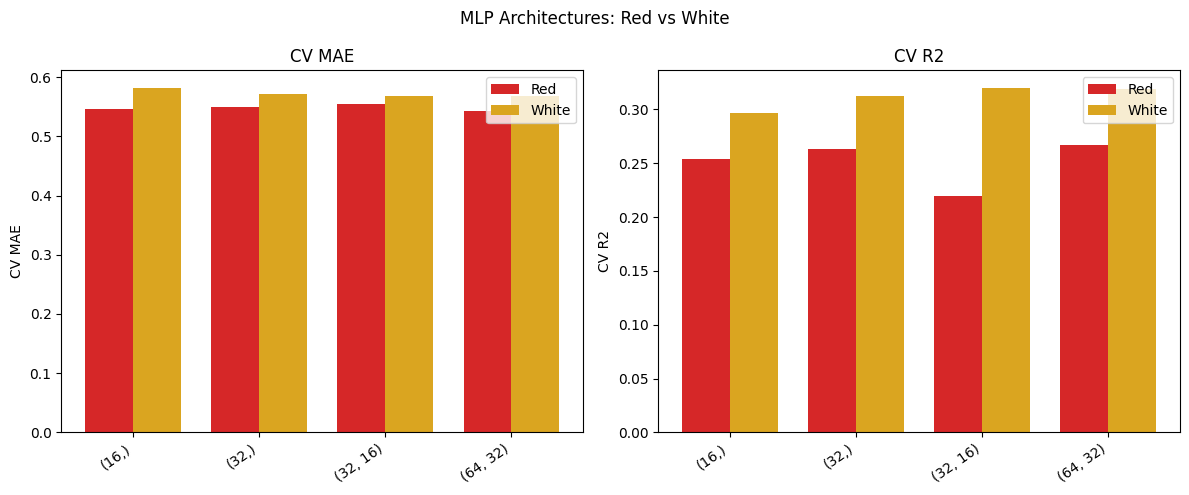

In [ ]:
compare_tables('MLP Architectures: Red vs White',mlp_arch_df,white_mlp_arch_df,'Architecture',['CV MAE', 'CV R2'])

### 8.2 Random Forest Hyperparameter Grid Search
Search 18 Random Forest configurations: 100 or 200 trees; maximum depth None, 10 or 20; and minimum leaf size 1, 3 or 5. GridSearchCV evaluates every configuration with five-fold training-set CV and refit="mae", selecting the lowest MAE and refitting that configuration on the full training set. Larger leaves and depth limits constrain tree complexity; additional trees mainly affect averaging and computational cost.

#### Red Wine — Calculations

In [ ]:
with capture_output() as _individual_output:
    from sklearn.ensemble import RandomForestRegressor
    from sklearn.model_selection import GridSearchCV, KFold
    import pandas as pd

    # Define hyperparameters
    param_grid = {
        "n_estimators": [100, 200],
        "max_depth": [None, 10, 20],
        "min_samples_leaf": [1, 3, 5]
    }

    # 5-fold cross-validation
    cv = KFold(
        n_splits=5,
        shuffle=True,
        random_state=42
    )

    # Create Random Forest model
    rf_tuning_model = RandomForestRegressor(
        random_state=42,
        n_jobs=1
    )

    # Grid search using training data only
    rf_grid = GridSearchCV(
        estimator=rf_tuning_model,
        param_grid=param_grid,
        scoring={
            "mae": "neg_mean_absolute_error",
            "r2": "r2"
        },
        refit="mae",
        cv=cv,
        n_jobs=-1,
        return_train_score=True
    )

    # Run hyperparameter tuning
    rf_grid.fit(X_train, y_train)

    print("Red Wine Random Forest tuning completed!")
    print("Best Parameters:", rf_grid.best_params_)
    print(f"Best CV MAE: {-rf_grid.best_score_:.4f}")

plt.close("all")

#### White Wine — Calculations

In [ ]:
with capture_output() as _individual_output:
    from sklearn.ensemble import RandomForestRegressor
    from sklearn.model_selection import GridSearchCV, KFold
    import pandas as pd

    # Define hyperparameters
    white_param_grid = {
        "n_estimators": [100, 200],
        "max_depth": [None, 10, 20],
        "min_samples_leaf": [1, 3, 5]
    }

    # 5-fold cross-validation
    white_cv = KFold(
        n_splits=5,
        shuffle=True,
        random_state=42
    )

    # Create Random Forest model
    white_rf_tuning_model = RandomForestRegressor(
        random_state=42,
        n_jobs=1
    )

    # Grid search using training data only
    white_rf_grid = GridSearchCV(
        estimator=white_rf_tuning_model,
        param_grid=white_param_grid,
        scoring={
            "mae": "neg_mean_absolute_error",
            "r2": "r2"
        },
        refit="mae",
        cv=white_cv,
        n_jobs=-1,
        return_train_score=True
    )

    # Run hyperparameter tuning
    white_rf_grid.fit(white_X_train, white_y_train)

    print("White Wine Random Forest tuning completed!")
    print("Best Parameters:", white_rf_grid.best_params_)
    print(f"Best CV MAE: {-white_rf_grid.best_score_:.4f}")

plt.close("all")

#### 8.2.1 Random Forest Grid Search Results
Display all 18 Random Forest configurations ranked by mean CV MAE, with training and validation R² to help interpret the fit. Inspect the parameter columns as well as rank: independently ranked red and white configurations need not have identical parameters. Small score differences alone do not establish a meaningful or statistically significant advantage.

#### Red Wine — Calculations

In [ ]:
with capture_output() as _individual_output:
    # Extract GridSearchCV results
    rf_tuning_df = pd.DataFrame(
        rf_grid.cv_results_
    )

    # Select useful columns
    rf_tuning_df = rf_tuning_df[[
        "param_n_estimators",
        "param_max_depth",
        "param_min_samples_leaf",
        "mean_train_r2",
        "mean_test_r2",
        "std_test_r2",
        "mean_test_mae"
    ]].copy()

    # Convert negative MAE to positive
    rf_tuning_df["CV MAE"] = (
        -rf_tuning_df["mean_test_mae"]
    )

    # Rename columns
    rf_tuning_df = rf_tuning_df.rename(columns={
        "param_n_estimators": "Trees",
        "param_max_depth": "Max Depth",
        "param_min_samples_leaf": "Min Samples Leaf",
        "mean_train_r2": "Train R2",
        "mean_test_r2": "CV R2",
        "std_test_r2": "CV R2 Std"
    })

    # Remove original negative-MAE column
    rf_tuning_df = rf_tuning_df.drop(
        columns=["mean_test_mae"]
    )

    # Sort by lowest CV MAE
    rf_tuning_df = rf_tuning_df.sort_values(
        by="CV MAE"
    )

    print("Red Wine Random Forest Hyperparameter Results:")
    display(rf_tuning_df.round(4))

plt.close("all")

#### White Wine — Calculations

In [ ]:
with capture_output() as _individual_output:
    # Extract GridSearchCV results
    white_rf_tuning_df = pd.DataFrame(
        white_rf_grid.cv_results_
    )

    # Select useful columns
    white_rf_tuning_df = white_rf_tuning_df[[
        "param_n_estimators",
        "param_max_depth",
        "param_min_samples_leaf",
        "mean_train_r2",
        "mean_test_r2",
        "std_test_r2",
        "mean_test_mae"
    ]].copy()

    # Convert negative MAE to positive
    white_rf_tuning_df["CV MAE"] = (
        -white_rf_tuning_df["mean_test_mae"]
    )

    # Rename columns
    white_rf_tuning_df = white_rf_tuning_df.rename(columns={
        "param_n_estimators": "Trees",
        "param_max_depth": "Max Depth",
        "param_min_samples_leaf": "Min Samples Leaf",
        "mean_train_r2": "Train R2",
        "mean_test_r2": "CV R2",
        "std_test_r2": "CV R2 Std"
    })

    # Remove original negative-MAE column
    white_rf_tuning_df = white_rf_tuning_df.drop(
        columns=["mean_test_mae"]
    )

    # Sort by lowest CV MAE
    white_rf_tuning_df = white_rf_tuning_df.sort_values(
        by="CV MAE"
    )

    print("White Wine Random Forest Hyperparameter Results:")
    display(white_rf_tuning_df.round(4))

plt.close("all")

#### 8.2.2 Baseline vs Tuned Random Forest

Compare the baseline Random Forest CV MAE with the minimum MAE found by the search, separately for each dataset. A positive baseline-minus-selected difference indicates a lower selected CV error. This describes improvement on the selection folds, not guaranteed improvement on unseen data; the final test comparison appears in Section 9.

#### Red Wine — Calculations

In [ ]:
with capture_output() as _individual_output:
    baseline_cv_mae = cv_results_df.loc[
        cv_results_df["Model"] == "Random Forest",
        "CV MAE"
    ].iloc[0]


    tuned_cv_mae = -rf_grid.best_score_

    print("Red Wine Random Forest CV Comparison")
    print("----------------------------")
    print(f"Baseline CV MAE: {baseline_cv_mae:.4f}")
    print(f"Tuned CV MAE: {tuned_cv_mae:.4f}")

    improvement = (
        baseline_cv_mae - tuned_cv_mae
    )

    print(f"MAE improvement: {improvement:.4f}")

    print("\nBest Hyperparameters:")
    print(rf_grid.best_params_)

plt.close("all")

#### White Wine — Calculations

In [ ]:
with capture_output() as _individual_output:
    white_baseline_cv_mae = white_cv_results_df.loc[
        white_cv_results_df["Model"] == "Random Forest",
        "CV MAE"
    ].iloc[0]


    white_tuned_cv_mae = -white_rf_grid.best_score_

    print("White Wine Random Forest CV Comparison")
    print("----------------------------")
    print(f"Baseline CV MAE: {white_baseline_cv_mae:.4f}")
    print(f"Tuned CV MAE: {white_tuned_cv_mae:.4f}")

    white_improvement = (
        white_baseline_cv_mae - white_tuned_cv_mae
    )

    print(f"MAE improvement: {white_improvement:.4f}")

    print("\nBest Hyperparameters:")
    print(white_rf_grid.best_params_)

plt.close("all")

#### Combined Results
Compare each dataset’s independently ranked search configurations. Rank 1 in red and white can represent different hyperparameters. Lower CV MAE is better; ranks alone are not a matched-configuration comparison.

,Trees,Max Depth,Min Samples Leaf,Train R2,CV R2,CV R2 Std,CV MAE,Rank,Dataset
0,200,None,3,0.8086,0.3897,0.0490,0.4905,1,Red
1,200,20,3,0.8086,0.3897,0.0490,0.4905,2,Red
2,200,10,3,0.7843,0.3881,0.0485,0.4917,3,Red
3,200,None,5,0.7268,0.3901,0.0529,0.4922,4,Red
4,200,20,5,0.7268,0.3901,0.0529,0.4922,5,Red
5,200,10,5,0.7163,0.3898,0.0533,0.4925,6,Red
6,200,10,1,0.8511,0.3861,0.0481,0.4931,7,Red
7,100,20,3,0.8057,0.3814,0.0465,0.4936,8,Red
8,100,None,3,0.8057,0.3814,0.0465,0.4936,9,Red
9,100,None,5,0.7250,0.3853,0.0526,0.4940,10,Red


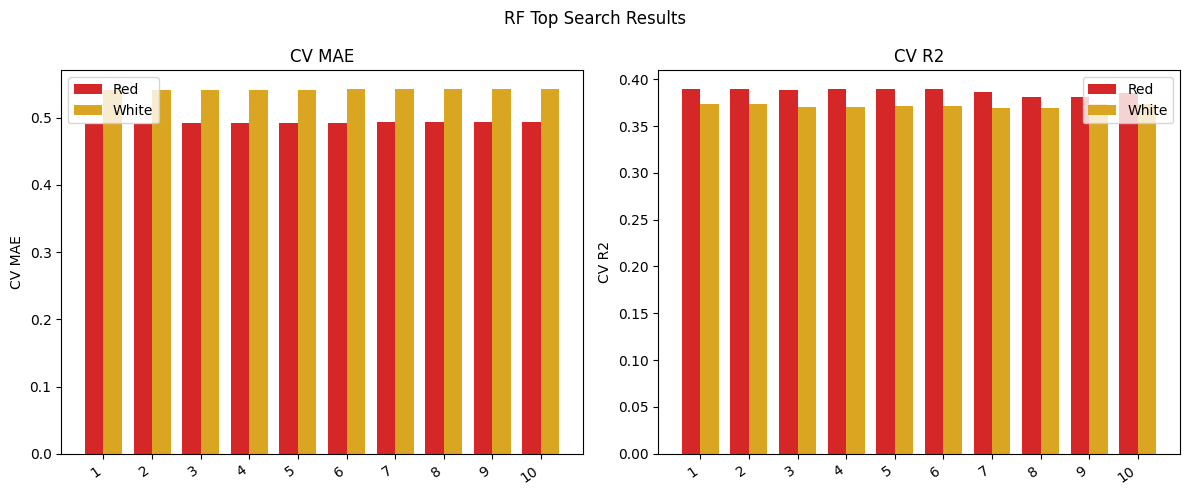

In [ ]:
compare_tables('RF Top Search Results',rf_tuning_df.head(10).assign(Rank=range(1,11)),white_rf_tuning_df.head(10).assign(Rank=range(1,11)),'Rank',['CV MAE','CV R2'])

,Dataset,CV MAE
0,Red,0.4905
1,White,0.5414


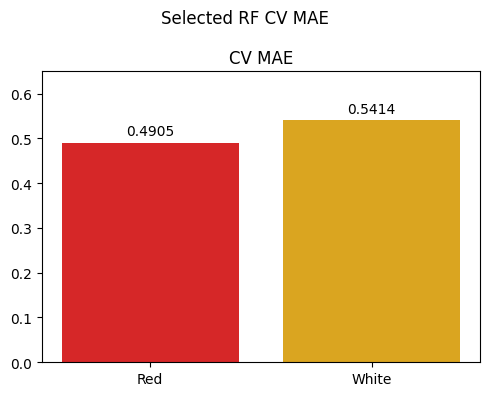

In [ ]:
compare_metric_rows('Selected RF CV MAE',{'CV MAE':-rf_grid.best_score_},{'CV MAE':-white_rf_grid.best_score_})

### 8.3 Data Sensitivity and Learning Curves
Hold the selected Random Forest settings fixed and vary the training size across 25%, 50%, 75% and 100% of each CV training fold. Compare mean training and validation MAE to investigate sensitivity to available data. These proportions refer to the fold's training portion, not the full cleaned dataset. Red and white absolute sample counts therefore differ. Because settings were selected beforehand on the training data, these are descriptive sensitivity results rather than nested validation of selection.

#### Red Wine — Calculations

In [ ]:
with capture_output() as _individual_output:
    import numpy as np
    import pandas as pd

    from sklearn.model_selection import learning_curve, KFold
    from sklearn.base import clone

    # Use the tuned Random Forest
    model = clone(rf_grid.best_estimator_)

    # Same 5-fold cross-validation strategy
    cv = KFold(
        n_splits=5,
        shuffle=True,
        random_state=42
    )

    # Training-set proportions
    train_sizes = [0.25, 0.50, 0.75, 1.0]

    sizes, train_scores, cv_scores = learning_curve(
        estimator=model,
        X=X_train,
        y=y_train,
        train_sizes=train_sizes,
        cv=cv,
        scoring="neg_mean_absolute_error",
        shuffle=True,
        random_state=42,
        n_jobs=1
    )

    # Convert negative scores to positive MAE
    train_mae = -train_scores.mean(axis=1)
    cv_mae = -cv_scores.mean(axis=1)
    cv_std = cv_scores.std(axis=1)

    learning_df = pd.DataFrame({
        "Training Samples": sizes,
        "Train MAE": train_mae,
        "CV MAE": cv_mae,
        "CV MAE Std": cv_std
    })

    print("Red Wine Training-Data Sensitivity Results:")
    display(learning_df.round(4))

plt.close("all")

In [ ]:
with capture_output() as _individual_output:
    import matplotlib.pyplot as plt

    plt.figure(figsize=(9, 5))

    plt.plot(
        learning_df["Training Samples"],
        learning_df["Train MAE"],
        marker="o",
        label="Training MAE"
    )

    plt.plot(
        learning_df["Training Samples"],
        learning_df["CV MAE"],
        marker="s",
        label="Cross-Validation MAE"
    )

    plt.xlabel("Number of Training Samples")
    plt.ylabel("Mean Absolute Error")
    plt.title("Red Wine Random Forest Learning Curve")
    plt.legend()
    plt.grid(alpha=0.3)

    plt.tight_layout()
    plt.savefig(
        "red_wine_random_forest_learning_curve.png",
        dpi=300,
        bbox_inches="tight"
    )
    plt.show()

plt.close("all")

#### White Wine — Calculations

In [ ]:
with capture_output() as _individual_output:
    import numpy as np
    import pandas as pd

    from sklearn.model_selection import learning_curve, KFold
    from sklearn.base import clone

    # Use the tuned Random Forest
    white_model = clone(white_rf_grid.best_estimator_)

    # Same 5-fold cross-validation strategy
    white_cv = KFold(
        n_splits=5,
        shuffle=True,
        random_state=42
    )

    # Training-set proportions
    white_train_sizes = [0.25, 0.50, 0.75, 1.0]

    white_sizes, white_train_scores, white_cv_scores = learning_curve(
        estimator=white_model,
        X=white_X_train,
        y=white_y_train,
        train_sizes=white_train_sizes,
        cv=white_cv,
        scoring="neg_mean_absolute_error",
        shuffle=True,
        random_state=42,
        n_jobs=1
    )

    # Convert negative scores to positive MAE
    white_train_mae = -white_train_scores.mean(axis=1)
    white_cv_mae = -white_cv_scores.mean(axis=1)
    white_cv_std = white_cv_scores.std(axis=1)

    white_learning_df = pd.DataFrame({
        "Training Samples": white_sizes,
        "Train MAE": white_train_mae,
        "CV MAE": white_cv_mae,
        "CV MAE Std": white_cv_std
    })

    print("White Wine Training-Data Sensitivity Results:")
    display(white_learning_df.round(4))

plt.close("all")

In [ ]:
with capture_output() as _individual_output:
    import matplotlib.pyplot as plt

    plt.figure(figsize=(9, 5))

    plt.plot(
        white_learning_df["Training Samples"],
        white_learning_df["Train MAE"],
        marker="o",
        label="Training MAE"
    )

    plt.plot(
        white_learning_df["Training Samples"],
        white_learning_df["CV MAE"],
        marker="s",
        label="Cross-Validation MAE"
    )

    plt.xlabel("Number of Training Samples")
    plt.ylabel("Mean Absolute Error")
    plt.title("White Wine Random Forest Learning Curve")
    plt.legend()
    plt.grid(alpha=0.3)

    plt.tight_layout()
    plt.savefig(
        "white_wine_random_forest_learning_curve.png",
        dpi=300,
        bbox_inches="tight"
    )
    plt.show()

plt.close("all")

#### Combined Results
Red and white results are displayed together. Different metrics have separate panels. Cross-dataset differences are descriptive; fold variation is not a significance test.

,Training Samples,Train MAE,CV MAE,CV MAE Std,Dataset
0,217,0.2841,0.5193,0.0188,Red
1,434,0.2752,0.5019,0.0209,Red
2,651,0.2709,0.4969,0.0143,Red
3,869,0.2687,0.4938,0.0224,Red
4,633,0.2950,0.5702,0.0181,White
5,1267,0.2963,0.5607,0.0172,White
6,1900,0.2940,0.5481,0.0129,White
7,2534,0.2904,0.5429,0.0143,White


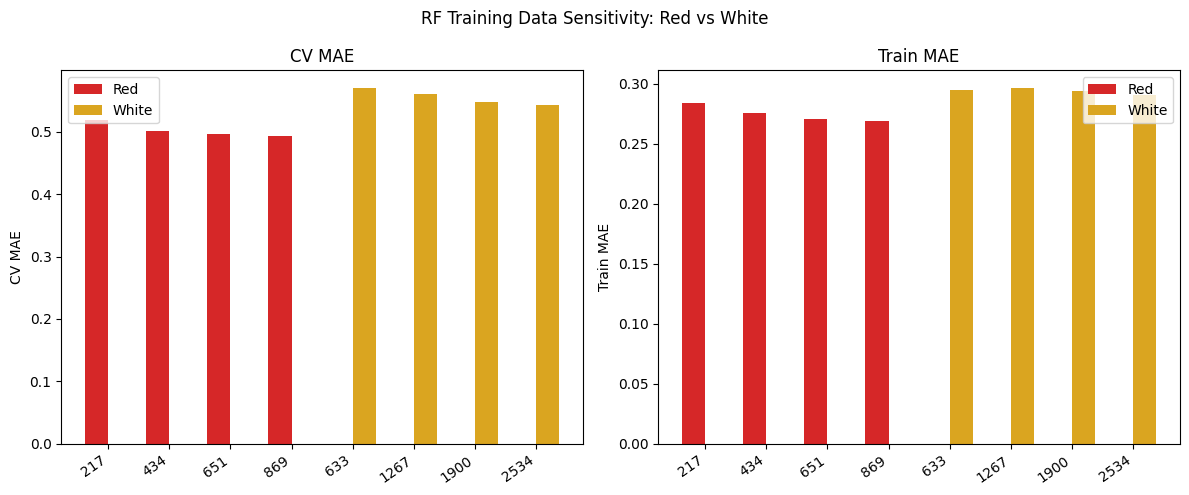

In [ ]:
compare_tables('RF Training Data Sensitivity: Red vs White',learning_df,white_learning_df,'Training Samples',['CV MAE', 'Train MAE'])

### 8.4 Feature Selection Experiment
Now let's investigate another question:

> Can we predict wine quality accurately using fewer chemical properties?

Our dataset contains 11 input features. However, not all features may contribute equally to prediction performance.
We'll compare Random Forest models using 3, 5, 8 and all 11 features.

#### Red Wine — Calculations

In [ ]:
with capture_output() as _individual_output:
    import pandas as pd

    from sklearn.feature_selection import SelectKBest, f_regression
    from sklearn.pipeline import Pipeline
    from sklearn.ensemble import RandomForestRegressor
    from sklearn.model_selection import KFold, cross_validate

    # Number of features to test
    feature_counts = [3, 5, 8, 11]

    # Same cross-validation approach
    cv = KFold(
        n_splits=5,
        shuffle=True,
        random_state=42
    )

    feature_results = []

    for k in feature_counts:

        # Feature selection happens inside each CV fold
        model = Pipeline([
            ("feature_selection", SelectKBest(
                score_func=f_regression,
                k=k
            )),
            ("random_forest", RandomForestRegressor(
                **rf_grid.best_params_,
                random_state=42,
                n_jobs=1
            ))
        ])

        scores = cross_validate(
            model,
            X_train,
            y_train,
            cv=cv,
            scoring={
                "mae": "neg_mean_absolute_error",
                "r2": "r2"
            },
            return_train_score=True,
            n_jobs=-1
        )

        feature_results.append({
            "Features": k,
            "Train R2": scores["train_r2"].mean(),
            "CV R2": scores["test_r2"].mean(),
            "CV MAE": -scores["test_mae"].mean()
        })

    feature_df = pd.DataFrame(feature_results)

    print("Red Wine Feature Selection Results:")
    display(feature_df.round(4))

plt.close("all")

In [ ]:
with capture_output() as _individual_output:
    import matplotlib.pyplot as plt

    plt.figure(figsize=(9, 5))

    plt.plot(
        feature_df["Features"],
        feature_df["CV MAE"],
        marker="o",
        linewidth=2
    )

    plt.xlabel("Number of Selected Features")
    plt.ylabel("Cross-Validation MAE")
    plt.title("Effect of Feature Selection on Random Forest")
    plt.xticks(feature_counts)
    plt.grid(alpha=0.3)

    plt.tight_layout()

    plt.savefig(
        "red_wine_rf_feature_selection.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

plt.close("all")

In [ ]:
with capture_output() as _individual_output:
    # Select the best feature count using CV MAE
    best_k = int(
        feature_df.loc[
            feature_df["CV MAE"].idxmin(),
            "Features"
        ]
    )

    # Fit the selector to the training set only
    selector = SelectKBest(
        score_func=f_regression,
        k=best_k
    )

    selector.fit(X_train, y_train)

    selected_features = X_train.columns[
        selector.get_support()
    ].tolist()

    print("Red Wine - Best number of features:", best_k)
    print("Selected features:")
    for feature in selected_features:
        print("-", feature)

plt.close("all")

#### White Wine — Calculations

In [ ]:
with capture_output() as _individual_output:
    import pandas as pd

    from sklearn.feature_selection import SelectKBest, f_regression
    from sklearn.pipeline import Pipeline
    from sklearn.ensemble import RandomForestRegressor
    from sklearn.model_selection import KFold, cross_validate

    # Number of features to test
    white_feature_counts = [3, 5, 8, 11]

    # Same cross-validation approach
    white_cv = KFold(
        n_splits=5,
        shuffle=True,
        random_state=42
    )

    white_feature_results = []

    for white_k in white_feature_counts:

        # Feature selection happens inside each CV fold
        white_model = Pipeline([
            ("feature_selection", SelectKBest(
                score_func=f_regression,
                k=white_k
            )),
            ("random_forest", RandomForestRegressor(
                **white_rf_grid.best_params_,
                random_state=42,
                n_jobs=1
            ))
        ])

        white_scores = cross_validate(
            white_model,
            white_X_train,
            white_y_train,
            cv=white_cv,
            scoring={
                "mae": "neg_mean_absolute_error",
                "r2": "r2"
            },
            return_train_score=True,
            n_jobs=-1
        )

        white_feature_results.append({
            "Features": white_k,
            "Train R2": white_scores["train_r2"].mean(),
            "CV R2": white_scores["test_r2"].mean(),
            "CV MAE": -white_scores["test_mae"].mean()
        })

    white_feature_df = pd.DataFrame(white_feature_results)

    print("White Wine Feature Selection Results:")
    display(white_feature_df.round(4))

plt.close("all")

In [ ]:
with capture_output() as _individual_output:
    import matplotlib.pyplot as plt

    plt.figure(figsize=(9, 5))

    plt.plot(
        white_feature_df["Features"],
        white_feature_df["CV MAE"],
        marker="o",
        linewidth=2
    )

    plt.xlabel("Number of Selected Features")
    plt.ylabel("Cross-Validation MAE")
    plt.title("Effect of Feature Selection on Random Forest")
    plt.xticks(white_feature_counts)
    plt.grid(alpha=0.3)

    plt.tight_layout()

    plt.savefig(
        "white_wine_rf_feature_selection.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

plt.close("all")

In [ ]:
with capture_output() as _individual_output:
    # Select the best feature count using CV MAE
    white_best_k = int(
        white_feature_df.loc[
            white_feature_df["CV MAE"].idxmin(),
            "Features"
        ]
    )

    # Fit the selector to the training set only
    white_selector = SelectKBest(
        score_func=f_regression,
        k=white_best_k
    )

    white_selector.fit(white_X_train, white_y_train)

    white_selected_features = white_X_train.columns[
        white_selector.get_support()
    ].tolist()

    print("White Wine - Best number of features:", white_best_k)
    print("Selected features:")
    for white_feature in white_selected_features:
        print("-", white_feature)

plt.close("all")

#### Combined Results
Red and white results are displayed together. Different metrics have separate panels. Cross-dataset differences are descriptive; fold variation is not a significance test.

,Features,Train R2,CV R2,CV MAE,Dataset
0,3,0.7050,0.3150,0.5218,Red
1,5,0.7630,0.3363,0.5124,Red
2,8,0.7995,0.3765,0.4953,Red
3,11,0.8086,0.3897,0.4905,Red
4,3,0.6399,0.1778,0.6208,White
5,5,0.7396,0.2874,0.5758,White
6,8,0.7770,0.3232,0.5627,White
7,11,0.8079,0.3741,0.5414,White


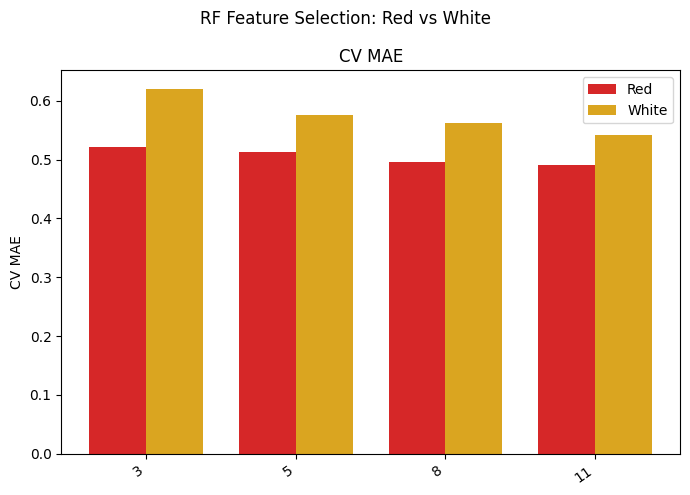

In [ ]:
compare_tables('RF Feature Selection: Red vs White',feature_df,white_feature_df,'Features',['CV MAE'])

## 8.5 Gradient Boosting Experiments and Tuning

### 8.5.1 Number of Boosting Stages vs Error

The defining hyperparameter of boosting is how many sequential trees (stages) to add. Too few
stages under-fit while too many fit noise in the training folds. The learning rate controls how much
each stage contributes, so the two interact: a smaller learning rate needs more stages.

For each learning rate, a 1,000-stage model is trained on each of the five CV folds and
`staged_predict` records the MAE after every stage, on the training part and on the validation
part of the fold. Averaging over folds gives a validation curve that shows where additional
stages stop helping.

#### Red Wine — Calculations

In [ ]:
with capture_output() as _individual_output:
    from sklearn.ensemble import GradientBoostingRegressor
    from sklearn.metrics import mean_absolute_error
    import numpy as np
    import pandas as pd

    learning_rates = [0.01, 0.05, 0.1]
    max_stages = 1000

    stage_curves = {}
    stage_summary = []

    for lr in learning_rates:
        train_curves, val_curves = [], []

        for train_idx, val_idx in cv.split(X_train):
            model = GradientBoostingRegressor(
                n_estimators=max_stages,
                learning_rate=lr,
                max_depth=3,
                random_state=42
            )
            model.fit(X_train.iloc[train_idx], y_train.iloc[train_idx])

            train_curves.append([
                mean_absolute_error(y_train.iloc[train_idx], pred)
                for pred in model.staged_predict(X_train.iloc[train_idx])
            ])
            val_curves.append([
                mean_absolute_error(y_train.iloc[val_idx], pred)
                for pred in model.staged_predict(X_train.iloc[val_idx])
            ])

        train_mean = np.mean(train_curves, axis=0)
        val_mean = np.mean(val_curves, axis=0)
        stage_curves[lr] = (train_mean, val_mean)

        best_stage = int(np.argmin(val_mean)) + 1
        stage_summary.append({
            "Learning Rate": lr,
            "Best Stages": best_stage,
            "CV MAE at Best": val_mean[best_stage - 1],
            "CV MAE at 100": val_mean[99],
            "CV MAE at 1000": val_mean[-1],
            "Train MAE at Best": train_mean[best_stage - 1],
        })

    stage_df = pd.DataFrame(stage_summary)
    print("Boosting stages vs cross-validation MAE:")
    display(stage_df.round(4))

plt.close("all")

In [ ]:
with capture_output() as _individual_output:
    import matplotlib.pyplot as plt

    fig, ax = plt.subplots(figsize=(10, 6))
    stages = np.arange(1, max_stages + 1)

    for lr, (train_mean, val_mean) in stage_curves.items():
        line, = ax.plot(stages, val_mean, label=f"Validation MAE (lr={lr})")
        ax.plot(stages, train_mean, linestyle="--", alpha=0.6, color=line.get_color(),
                label=f"Training MAE (lr={lr})")
        best_stage = int(np.argmin(val_mean)) + 1
        ax.scatter([best_stage], [val_mean[best_stage - 1]], color=line.get_color(), zorder=5)

    ax.set_xlabel("Number of Boosting Stages")
    ax.set_ylabel("Mean Absolute Error")
    ax.set_title("Gradient Boosting: Stages vs Error (5-fold CV, max_depth=3)")
    ax.set_ylim(0, 0.7)
    ax.legend(ncol=2, fontsize=9)
    ax.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig(f"{FIG_DIR}/gb_stages_vs_error.png", dpi=300, bbox_inches="tight")
    plt.show()

plt.close("all")

#### White Wine — Calculations

In [ ]:
with capture_output() as _individual_output:
    from sklearn.ensemble import GradientBoostingRegressor
    from sklearn.metrics import mean_absolute_error
    import numpy as np
    import pandas as pd

    white_learning_rates = [0.01, 0.05, 0.1]
    white_max_stages = 1000

    white_stage_curves = {}
    white_stage_summary = []

    for white_lr in white_learning_rates:
        white_train_curves, white_val_curves = [], []

        for white_train_idx, white_val_idx in white_cv.split(white_X_train):
            white_model = GradientBoostingRegressor(
                n_estimators=white_max_stages,
                learning_rate=white_lr,
                max_depth=3,
                random_state=42
            )
            white_model.fit(white_X_train.iloc[white_train_idx], white_y_train.iloc[white_train_idx])

            white_train_curves.append([
                mean_absolute_error(white_y_train.iloc[white_train_idx], white_pred)
                for white_pred in white_model.staged_predict(white_X_train.iloc[white_train_idx])
            ])
            white_val_curves.append([
                mean_absolute_error(white_y_train.iloc[white_val_idx], white_pred)
                for white_pred in white_model.staged_predict(white_X_train.iloc[white_val_idx])
            ])

        white_train_mean = np.mean(white_train_curves, axis=0)
        white_val_mean = np.mean(white_val_curves, axis=0)
        white_stage_curves[white_lr] = (white_train_mean, white_val_mean)

        white_best_stage = int(np.argmin(white_val_mean)) + 1
        white_stage_summary.append({
            "Learning Rate": white_lr,
            "Best Stages": white_best_stage,
            "CV MAE at Best": white_val_mean[white_best_stage - 1],
            "CV MAE at 100": white_val_mean[99],
            "CV MAE at 1000": white_val_mean[-1],
            "Train MAE at Best": white_train_mean[white_best_stage - 1],
        })

    white_stage_df = pd.DataFrame(white_stage_summary)
    print("Boosting stages vs cross-validation MAE:")
    display(white_stage_df.round(4))

plt.close("all")

In [ ]:
with capture_output() as _individual_output:
    import matplotlib.pyplot as plt

    white_fig, white_ax = plt.subplots(figsize=(10, 6))
    white_stages = np.arange(1, white_max_stages + 1)

    for white_lr, (white_train_mean, white_val_mean) in white_stage_curves.items():
        white_line, = white_ax.plot(white_stages, white_val_mean, label=f"Validation MAE (lr={white_lr})")
        white_ax.plot(white_stages, white_train_mean, linestyle="--", alpha=0.6, color=white_line.get_color(),
                label=f"Training MAE (lr={white_lr})")
        white_best_stage = int(np.argmin(white_val_mean)) + 1
        white_ax.scatter([white_best_stage], [white_val_mean[white_best_stage - 1]], color=white_line.get_color(), zorder=5)

    white_ax.set_xlabel("Number of Boosting Stages")
    white_ax.set_ylabel("Mean Absolute Error")
    white_ax.set_title("Gradient Boosting: Stages vs Error (5-fold CV, max_depth=3)")
    white_ax.set_ylim(0, 0.7)
    white_ax.legend(ncol=2, fontsize=9)
    white_ax.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig(f"{white_FIG_DIR}/gb_stages_vs_error.png", dpi=300, bbox_inches="tight")
    plt.show()

plt.close("all")

#### Combined Results
Red and white results are displayed together. Different metrics have separate panels. Cross-dataset differences are descriptive; fold variation is not a significance test.

,Learning Rate,Best Stages,CV MAE at Best,CV MAE at 100,CV MAE at 1000,Train MAE at Best,Dataset
0,0.01,438,0.5028,0.5593,0.5099,0.4241,Red
1,0.05,88,0.5036,0.5047,0.5352,0.4227,Red
2,0.10,38,0.5025,0.5114,0.5425,0.4306,Red
3,0.01,1000,0.5523,0.5998,0.5523,0.4899,White
4,0.05,377,0.5499,0.5574,0.5571,0.4513,White
5,0.10,193,0.5532,0.5545,0.5719,0.4478,White


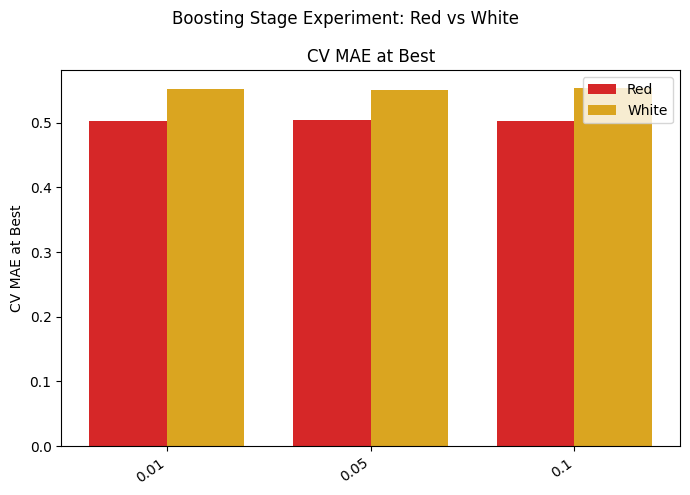

In [ ]:
compare_tables('Boosting Stage Experiment: Red vs White',stage_df,white_stage_df,'Learning Rate',['CV MAE at Best'])

### 8.5.2 Gradient Boosting Hyperparameter Grid Search

Mirroring the Random Forest grid search in Section 8.2, `GridSearchCV` is run on the training set
with the shared 5-fold CV and `refit="mae"`. The grid covers the learning rate, the number of
stages, tree depth (depth 2–4 keeps the trees "weak learners"), the subsample fraction
(stochastic gradient boosting, which adds randomness like bagging) and the minimum leaf size.

#### Red Wine — Calculations

In [ ]:
with capture_output() as _individual_output:
    from sklearn.ensemble import GradientBoostingRegressor
    from sklearn.model_selection import GridSearchCV
    import pandas as pd
    import time

    param_grid = {
        "learning_rate": [0.01, 0.05, 0.1],
        "n_estimators": [100, 300, 600],
        "max_depth": [2, 3, 4],
        "subsample": [0.8, 1.0],
        "min_samples_leaf": [1, 3, 5],
    }

    gb_tuning_model = GradientBoostingRegressor(random_state=42)

    gb_grid = GridSearchCV(
        estimator=gb_tuning_model,
        param_grid=param_grid,
        scoring={"mae": "neg_mean_absolute_error", "r2": "r2"},
        refit="mae",
        cv=cv,
        n_jobs=-1,
        return_train_score=True
    )

    start = time.time()
    gb_grid.fit(X_train, y_train)
    elapsed = time.time() - start

    n_combos = int(np.prod([len(v) for v in param_grid.values()]))
    print(f"Gradient Boosting tuning completed! ({n_combos} combinations x 5 folds in {elapsed:.0f} s)")
    print("Best Parameters:", gb_grid.best_params_)
    print(f"Best CV MAE: {-gb_grid.best_score_:.4f}")

plt.close("all")

#### White Wine — Calculations

In [ ]:
with capture_output() as _individual_output:
    from sklearn.ensemble import GradientBoostingRegressor
    from sklearn.model_selection import GridSearchCV
    import pandas as pd
    import time

    white_param_grid = {
        "learning_rate": [0.01, 0.05, 0.1],
        "n_estimators": [100, 300, 600],
        "max_depth": [2, 3, 4],
        "subsample": [0.8, 1.0],
        "min_samples_leaf": [1, 3, 5],
    }

    white_gb_tuning_model = GradientBoostingRegressor(random_state=42)

    white_gb_grid = GridSearchCV(
        estimator=white_gb_tuning_model,
        param_grid=white_param_grid,
        scoring={"mae": "neg_mean_absolute_error", "r2": "r2"},
        refit="mae",
        cv=white_cv,
        n_jobs=-1,
        return_train_score=True
    )

    white_start = time.time()
    white_gb_grid.fit(white_X_train, white_y_train)
    white_elapsed = time.time() - white_start

    white_n_combos = int(np.prod([len(white_v) for white_v in white_param_grid.values()]))
    print(f"Gradient Boosting tuning completed! ({white_n_combos} combinations x 5 folds in {white_elapsed:.0f} s)")
    print("Best Parameters:", white_gb_grid.best_params_)
    print(f"Best CV MAE: {-white_gb_grid.best_score_:.4f}")

plt.close("all")

#### 8.5.2.1 Grid Search Results

All combinations ranked by cross-validation MAE (top 15 shown), plus the Train R² of each so
the overfitting cost of deeper or longer models is visible.

#### Red Wine — Calculations

In [ ]:
with capture_output() as _individual_output:
    gb_tuning_df = pd.DataFrame(gb_grid.cv_results_)

    gb_tuning_df = gb_tuning_df[[
        "param_learning_rate", "param_n_estimators", "param_max_depth",
        "param_subsample", "param_min_samples_leaf",
        "mean_train_r2", "mean_test_r2", "std_test_r2", "mean_test_mae"
    ]].copy()

    gb_tuning_df["CV MAE"] = -gb_tuning_df["mean_test_mae"]
    gb_tuning_df = gb_tuning_df.rename(columns={
        "param_learning_rate": "Learning Rate",
        "param_n_estimators": "Stages",
        "param_max_depth": "Max Depth",
        "param_subsample": "Subsample",
        "param_min_samples_leaf": "Min Samples Leaf",
        "mean_train_r2": "Train R2",
        "mean_test_r2": "CV R2",
        "std_test_r2": "CV R2 Std",
    }).drop(columns=["mean_test_mae"])

    gb_tuning_df = gb_tuning_df.sort_values(by="CV MAE").reset_index(drop=True)

    print("Gradient Boosting Hyperparameter Results (top 15 of", len(gb_tuning_df), "):")
    display(gb_tuning_df.head(15).round(4))

    print("\nWorst 5 combinations:")
    display(gb_tuning_df.tail(5).round(4))

plt.close("all")

In [ ]:
with capture_output() as _individual_output:
    # effect of each hyperparameter, averaged over all other settings
    print("Mean CV MAE by hyperparameter value (lower is better):")
    for col in ["Learning Rate", "Stages", "Max Depth", "Subsample", "Min Samples Leaf"]:
        summary = gb_tuning_df.groupby(col)[["CV MAE", "Train R2"]].mean().round(4)
        print(f"\n{col}:")
        print(summary.to_string())

plt.close("all")

#### White Wine — Calculations

In [ ]:
with capture_output() as _individual_output:
    white_gb_tuning_df = pd.DataFrame(white_gb_grid.cv_results_)

    white_gb_tuning_df = white_gb_tuning_df[[
        "param_learning_rate", "param_n_estimators", "param_max_depth",
        "param_subsample", "param_min_samples_leaf",
        "mean_train_r2", "mean_test_r2", "std_test_r2", "mean_test_mae"
    ]].copy()

    white_gb_tuning_df["CV MAE"] = -white_gb_tuning_df["mean_test_mae"]
    white_gb_tuning_df = white_gb_tuning_df.rename(columns={
        "param_learning_rate": "Learning Rate",
        "param_n_estimators": "Stages",
        "param_max_depth": "Max Depth",
        "param_subsample": "Subsample",
        "param_min_samples_leaf": "Min Samples Leaf",
        "mean_train_r2": "Train R2",
        "mean_test_r2": "CV R2",
        "std_test_r2": "CV R2 Std",
    }).drop(columns=["mean_test_mae"])

    white_gb_tuning_df = white_gb_tuning_df.sort_values(by="CV MAE").reset_index(drop=True)

    print("Gradient Boosting Hyperparameter Results (top 15 of", len(white_gb_tuning_df), "):")
    display(white_gb_tuning_df.head(15).round(4))

    print("\nWorst 5 combinations:")
    display(white_gb_tuning_df.tail(5).round(4))

plt.close("all")

In [ ]:
with capture_output() as _individual_output:
    # effect of each hyperparameter, averaged over all other settings
    print("Mean CV MAE by hyperparameter value (lower is better):")
    for white_col in ["Learning Rate", "Stages", "Max Depth", "Subsample", "Min Samples Leaf"]:
        white_summary = white_gb_tuning_df.groupby(white_col)[["CV MAE", "Train R2"]].mean().round(4)
        print(f"\n{white_col}:")
        print(white_summary.to_string())

plt.close("all")

#### 8.5.2.2 Baseline vs Tuned Gradient Boosting
Compare baseline and selected Gradient Boosting using mean training-set CV MAE. The selected score comes from the same folds used in the search and should not be described as an independent validation result. In the combined top-rank chart, a matching rank across red and white does not necessarily mean matching hyperparameters.

#### Red Wine — Calculations

In [ ]:
with capture_output() as _individual_output:
    baseline_gb_cv_mae = gb_cv_row["CV MAE"]
    tuned_gb_cv_mae = -gb_grid.best_score_

    print("Gradient Boosting CV Comparison")
    print("-------------------------------")
    print(f"Baseline CV MAE: {baseline_gb_cv_mae:.4f}")
    print(f"Tuned CV MAE:    {tuned_gb_cv_mae:.4f}")
    print(f"MAE improvement: {baseline_gb_cv_mae - tuned_gb_cv_mae:.4f}")
    print(f"(Fold-to-fold std of the baseline CV MAE was {gb_cv_mae_std:.4f})")

    print("\nBest Hyperparameters:")
    print(gb_grid.best_params_)

    rf_tuned_cv_mae = -rf_grid.best_score_
    print(f"\nTuned Random Forest CV MAE (Section 8.2): {rf_tuned_cv_mae:.4f}")
    print(f"Tuned Gradient Boosting CV MAE:           {tuned_gb_cv_mae:.4f}")

plt.close("all")

#### White Wine — Calculations

In [ ]:
with capture_output() as _individual_output:
    white_baseline_gb_cv_mae = white_gb_cv_row["CV MAE"]
    white_tuned_gb_cv_mae = -white_gb_grid.best_score_

    print("Gradient Boosting CV Comparison")
    print("-------------------------------")
    print(f"Baseline CV MAE: {white_baseline_gb_cv_mae:.4f}")
    print(f"Tuned CV MAE:    {white_tuned_gb_cv_mae:.4f}")
    print(f"MAE improvement: {white_baseline_gb_cv_mae - white_tuned_gb_cv_mae:.4f}")
    print(f"(Fold-to-fold std of the baseline CV MAE was {white_gb_cv_mae_std:.4f})")

    print("\nBest Hyperparameters:")
    print(white_gb_grid.best_params_)

    white_rf_tuned_cv_mae = -white_rf_grid.best_score_
    print(f"\nTuned Random Forest CV MAE (Section 8.2): {white_rf_tuned_cv_mae:.4f}")
    print(f"Tuned Gradient Boosting CV MAE:           {white_tuned_gb_cv_mae:.4f}")

plt.close("all")

#### Combined Results
Red and white results are displayed together. Different metrics have separate panels. Cross-dataset differences are descriptive; fold variation is not a significance test.

,Learning Rate,Stages,Max Depth,Subsample,Min Samples Leaf,Train R2,CV R2,CV R2 Std,CV MAE,Rank,Dataset
0,0.01,600,4,0.8,5,0.7249,0.3805,0.0515,0.4965,1,Red
1,0.05,100,4,0.8,3,0.7120,0.3861,0.0535,0.4969,2,Red
2,0.01,600,4,0.8,3,0.7398,0.3806,0.0543,0.4970,3,Red
3,0.01,600,3,0.8,5,0.6192,0.3846,0.0538,0.4977,4,Red
4,0.05,100,4,0.8,5,0.6958,0.3805,0.0493,0.4980,5,Red
5,0.01,600,4,0.8,1,0.7459,0.3841,0.0515,0.4980,6,Red
6,0.05,100,4,0.8,1,0.7162,0.3876,0.0541,0.4984,7,Red
7,0.05,100,3,0.8,5,0.5991,0.3846,0.0492,0.4992,8,Red
8,0.01,300,4,0.8,3,0.6378,0.3911,0.0481,0.4994,9,Red
9,0.05,100,3,0.8,3,0.6027,0.3820,0.0501,0.4995,10,Red


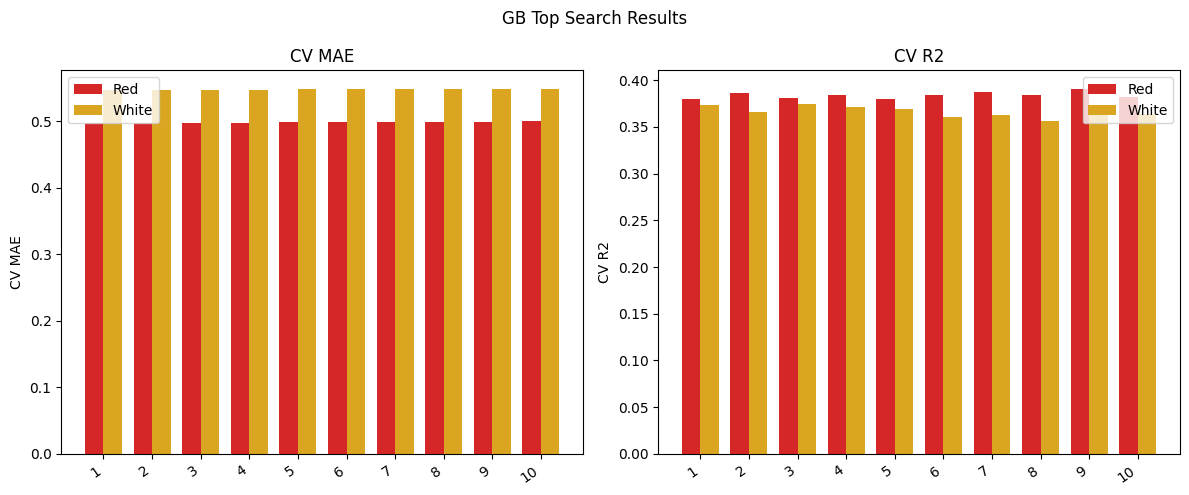

In [ ]:
compare_tables('GB Top Search Results',gb_tuning_df.head(10).assign(Rank=range(1,11)),white_gb_tuning_df.head(10).assign(Rank=range(1,11)),'Rank',['CV MAE','CV R2'])

,Dataset,CV MAE
0,Red,0.4965
1,White,0.5460


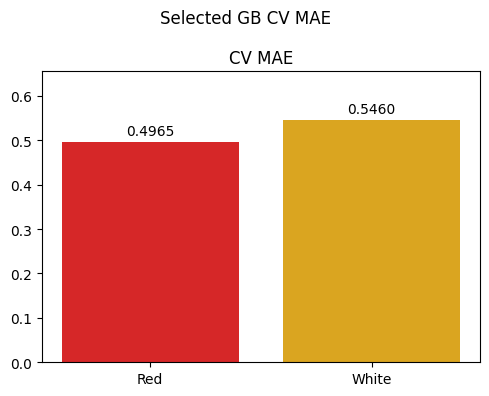

In [ ]:
compare_metric_rows('Selected GB CV MAE',{'CV MAE':-gb_grid.best_score_},{'CV MAE':-white_gb_grid.best_score_})

### 8.5.3 Tuned Gradient Boosting on the Test Set
Use the GridSearchCV best estimator, already refitted on the full training set, to predict each corresponding test set. Calculate test MAE, RMSE and R², and training R² for context. Keep the test split fixed and do not use these scores to choose another configuration. Since test comparisons were inspected during development, interpret the results as exploratory rather than a fresh confirmatory assessment.

#### Red Wine — Calculations

In [ ]:
with capture_output() as _individual_output:
    from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
    import numpy as np

    final_gb = gb_grid.best_estimator_

    y_pred_final_gb = final_gb.predict(X_test)
    final_gb_train_r2 = r2_score(y_train, final_gb.predict(X_train))
    final_gb_mae = mean_absolute_error(y_test, y_pred_final_gb)
    final_gb_rmse = np.sqrt(mean_squared_error(y_test, y_pred_final_gb))
    final_gb_r2 = r2_score(y_test, y_pred_final_gb)

    tuned_gb_row = {
        "Model": "Tuned Gradient Boosting",
        "Train R2": final_gb_train_r2,
        "Test MAE": final_gb_mae,
        "Test RMSE": final_gb_rmse,
        "Test R2": final_gb_r2,
    }


    display(pd.DataFrame([tuned_gb_row]).round(4))

plt.close("all")

#### White Wine — Calculations

In [ ]:
with capture_output() as _individual_output:
    from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
    import numpy as np

    white_final_gb = white_gb_grid.best_estimator_

    white_y_pred_final_gb = white_final_gb.predict(white_X_test)
    white_final_gb_train_r2 = r2_score(white_y_train, white_final_gb.predict(white_X_train))
    white_final_gb_mae = mean_absolute_error(white_y_test, white_y_pred_final_gb)
    white_final_gb_rmse = np.sqrt(mean_squared_error(white_y_test, white_y_pred_final_gb))
    white_final_gb_r2 = r2_score(white_y_test, white_y_pred_final_gb)

    white_tuned_gb_row = {
        "Model": "Tuned Gradient Boosting",
        "Train R2": white_final_gb_train_r2,
        "Test MAE": white_final_gb_mae,
        "Test RMSE": white_final_gb_rmse,
        "Test R2": white_final_gb_r2,
    }


    display(pd.DataFrame([white_tuned_gb_row]).round(4))

plt.close("all")

#### Combined Results
Red and white results are displayed together. Different metrics have separate panels. Cross-dataset differences are descriptive; fold variation is not a significance test.

,Dataset,Test MAE,Test RMSE,Test R2
0,Red,0.4901,0.6273,0.4134
1,White,0.5482,0.7002,0.3820


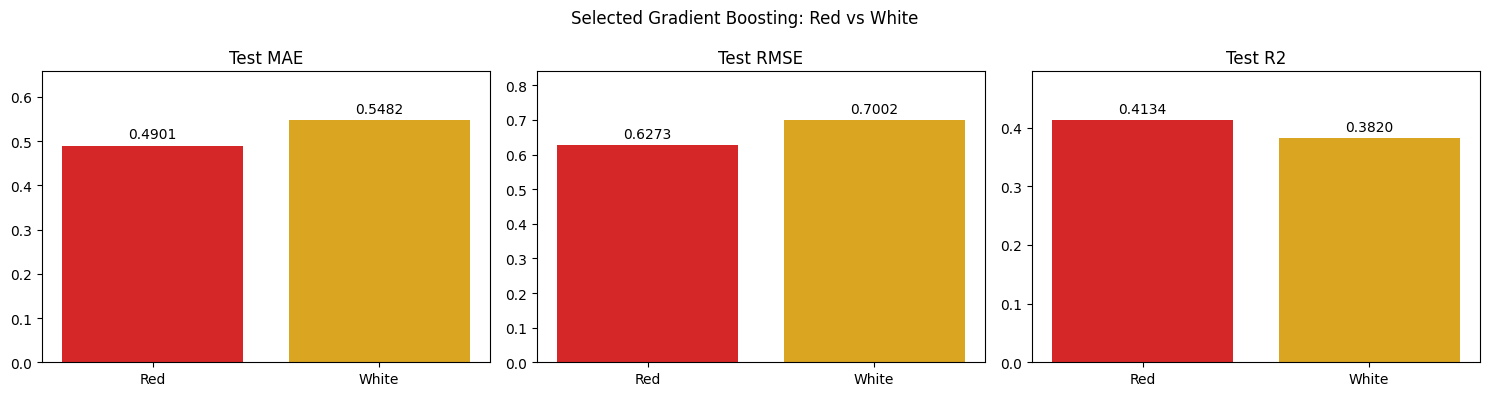

In [ ]:
compare_metric_rows('Selected Gradient Boosting: Red vs White', {'Test MAE':final_gb_mae,'Test RMSE':final_gb_rmse,'Test R2':final_gb_r2}, {'Test MAE':white_final_gb_mae,'Test RMSE':white_final_gb_rmse,'Test R2':white_final_gb_r2})

### 8.5.4 Marginal Cases: Baseline RF vs Selected Gradient Boosting
Compare baseline Random Forest and selected Gradient Boosting on the same test observations within each dataset. Summarise absolute errors and counts at each score and within low (3–4), typical (5–6) and high (7–9) groups; red wine has no score-9 observations. A negative GB-minus-RF MAE difference favours Gradient Boosting. These are rare target scores, not necessarily unusual feature values. Very small extreme-score groups support only cautious conclusions.

#### Red Wine — Calculations

In [ ]:
with capture_output() as _individual_output:
    error_df = pd.DataFrame({"Actual Quality": y_test.to_numpy(),
        "RF Error": np.abs(y_test.to_numpy() - rf_model.predict(X_test)),
        "GB Error": np.abs(y_test.to_numpy() - final_gb.predict(X_test))})
    error_by_quality = error_df.groupby("Actual Quality").agg(
        Sample_Count=("RF Error", "size"), RF_MAE=("RF Error", "mean"),
        GB_MAE=("GB Error", "mean")).reset_index()
    error_by_quality["Difference (GB - RF)"] = error_by_quality.GB_MAE - error_by_quality.RF_MAE
    display(error_by_quality.round(4))
    error_df["Quality Group"] = pd.cut(error_df["Actual Quality"], [2,4,6,9],
        labels=["Low (3-4)", "Typical (5-6)", "High (7-9)"], include_lowest=True)
    assert error_df["Quality Group"].notna().all()
    marginal_results = error_df.groupby("Quality Group", observed=True).agg(
        Sample_Count=("RF Error", "size"), RF_MAE=("RF Error", "mean"),
        GB_MAE=("GB Error", "mean")).reset_index()
    assert marginal_results.Sample_Count.sum() == len(y_test)
    display(marginal_results.round(4))

plt.close("all")

In [ ]:
with capture_output() as _individual_output:
    import matplotlib.pyplot as plt
    import numpy as np

    fig, ax = plt.subplots(figsize=(9, 5))
    x = np.arange(len(error_by_quality))
    width = 0.38

    bars_gb = ax.bar(x - width / 2, error_by_quality["GB_MAE"], width, label="Tuned Gradient Boosting", color="tab:orange")
    bars_rf = ax.bar(x + width / 2, error_by_quality["RF_MAE"], width, label="Random Forest (Section 5)", color="tab:blue")
    ax.bar_label(bars_gb, fmt="%.3f", padding=3, fontsize=8)
    ax.bar_label(bars_rf, fmt="%.3f", padding=3, fontsize=8)

    ax.set_xticks(x)
    ax.set_xticklabels(error_by_quality["Actual Quality"].astype(str))
    ax.set_xlabel("Actual Wine Quality Score")
    ax.set_ylabel("Mean Absolute Error")
    ax.set_title("Prediction Error by Quality Score: Gradient Boosting vs Random Forest")
    ax.legend()
    plt.tight_layout()
    plt.savefig(f"{FIG_DIR}/gb_error_by_quality.png", dpi=300, bbox_inches="tight")
    plt.show()

plt.close("all")

#### White Wine — Calculations

In [ ]:
with capture_output() as _individual_output:
    white_error_df = pd.DataFrame({"Actual Quality": white_y_test.to_numpy(),
        "RF Error": np.abs(white_y_test.to_numpy() - white_rf_model.predict(white_X_test)),
        "GB Error": np.abs(white_y_test.to_numpy() - white_final_gb.predict(white_X_test))})
    white_error_by_quality = white_error_df.groupby("Actual Quality").agg(
        Sample_Count=("RF Error", "size"), RF_MAE=("RF Error", "mean"),
        GB_MAE=("GB Error", "mean")).reset_index()
    white_error_by_quality["Difference (GB - RF)"] = white_error_by_quality.GB_MAE - white_error_by_quality.RF_MAE
    display(white_error_by_quality.round(4))
    white_error_df["Quality Group"] = pd.cut(white_error_df["Actual Quality"], [2,4,6,9],
        labels=["Low (3-4)", "Typical (5-6)", "High (7-9)"], include_lowest=True)
    assert white_error_df["Quality Group"].notna().all()
    white_marginal_results = white_error_df.groupby("Quality Group", observed=True).agg(
        Sample_Count=("RF Error", "size"), RF_MAE=("RF Error", "mean"),
        GB_MAE=("GB Error", "mean")).reset_index()
    assert white_marginal_results.Sample_Count.sum() == len(white_y_test)
    display(white_marginal_results.round(4))

plt.close("all")

In [ ]:
with capture_output() as _individual_output:
    import matplotlib.pyplot as plt
    import numpy as np

    white_fig, white_ax = plt.subplots(figsize=(9, 5))
    white_x = np.arange(len(white_error_by_quality))
    white_width = 0.38

    white_bars_gb = white_ax.bar(white_x - white_width / 2, white_error_by_quality["GB_MAE"], white_width, label="Tuned Gradient Boosting", color="tab:orange")
    white_bars_rf = white_ax.bar(white_x + white_width / 2, white_error_by_quality["RF_MAE"], white_width, label="Random Forest (Section 5)", color="tab:blue")
    white_ax.bar_label(white_bars_gb, fmt="%.3f", padding=3, fontsize=8)
    white_ax.bar_label(white_bars_rf, fmt="%.3f", padding=3, fontsize=8)

    white_ax.set_xticks(white_x)
    white_ax.set_xticklabels(white_error_by_quality["Actual Quality"].astype(str))
    white_ax.set_xlabel("Actual Wine Quality Score")
    white_ax.set_ylabel("Mean Absolute Error")
    white_ax.set_title("Prediction Error by Quality Score: Gradient Boosting vs Random Forest")
    white_ax.legend()
    plt.tight_layout()
    plt.savefig(f"{white_FIG_DIR}/gb_error_by_quality.png", dpi=300, bbox_inches="tight")
    plt.show()

plt.close("all")

,Actual Quality,Sample_Count,RF_MAE,GB_MAE,Difference (GB - RF),Dataset
0,3,2,2.0850,2.0436,-0.0414,Red
1,4,11,1.0600,0.9870,-0.0730,Red
2,5,116,0.3703,0.3749,0.0047,Red
3,6,107,0.4044,0.4339,0.0295,Red
4,7,33,0.7173,0.7382,0.0209,Red
5,8,3,1.3233,1.3578,0.0344,Red
6,3,4,2.6000,2.4330,-0.1670,White
7,4,31,1.1065,1.1180,0.0116,White
8,5,235,0.5422,0.5435,0.0013,White
9,6,358,0.3516,0.3529,0.0014,White


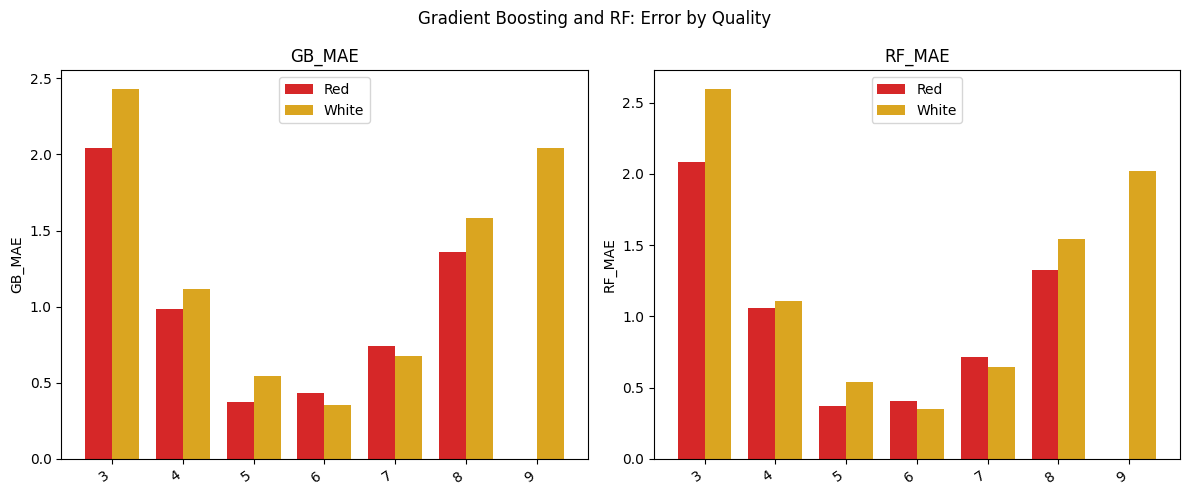

In [ ]:
compare_tables(
    "Gradient Boosting and RF: Error by Quality",
    error_by_quality,
    white_error_by_quality,
    "Actual Quality",
    ["GB_MAE", "RF_MAE"]
)

### 8.5.5 Exploratory Feature Importance
Describe the selected Gradient Boosting model using impurity-based feature importance and permutation importance. Permutation importance here is the increase in test MAE when one feature is shuffled; a larger positive increase indicates greater model reliance under this procedure. Correlated features can substitute for each other, so importance is not a causal effect or an isolated measure of intrinsic usefulness. Repeat variability is not a confidence interval. These exploratory test-set explanations must not guide further selection while claiming independent test evaluation.

#### Red Wine — Calculations

In [ ]:
with capture_output() as _individual_output:
    from sklearn.inspection import permutation_importance
    import pandas as pd

    perm = permutation_importance(
        final_gb, X_test, y_test,
        scoring="neg_mean_absolute_error",
        n_repeats=20,
        random_state=42,
        n_jobs=-1
    )

    importance_df = pd.DataFrame({
        "Feature": X_train.columns,
        "Impurity Importance": final_gb.feature_importances_,
        "Permutation Importance (MAE increase)": perm.importances_mean,
        "Permutation Std": perm.importances_std,
    }).sort_values("Permutation Importance (MAE increase)", ascending=False).reset_index(drop=True)

    print("Feature importance (tuned Gradient Boosting):")
    display(importance_df.round(4))

plt.close("all")

In [ ]:
with capture_output() as _individual_output:
    import matplotlib.pyplot as plt

    fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))

    imp_sorted = importance_df.sort_values("Impurity Importance")
    axes[0].barh(imp_sorted["Feature"], imp_sorted["Impurity Importance"], color="tab:orange")
    axes[0].set_title("Impurity-Based Importance (training)")
    axes[0].set_xlabel("Fraction of total squared-error reduction")

    perm_sorted = importance_df.sort_values("Permutation Importance (MAE increase)")
    axes[1].barh(perm_sorted["Feature"], perm_sorted["Permutation Importance (MAE increase)"],
                 xerr=perm_sorted["Permutation Std"], color="tab:orange", capsize=3)
    axes[1].set_title("Permutation Importance (test set, 20 repeats)")
    axes[1].set_xlabel("Increase in test MAE when feature is shuffled")

    for ax in axes:
        ax.grid(axis="x", alpha=0.3)
    plt.suptitle("Tuned Gradient Boosting: Feature Importance", y=1.02)
    plt.tight_layout()
    plt.savefig(f"{FIG_DIR}/gb_feature_importance.png", dpi=300, bbox_inches="tight")
    plt.show()

plt.close("all")

#### White Wine — Calculations

In [ ]:
with capture_output() as _individual_output:
    from sklearn.inspection import permutation_importance
    import pandas as pd

    white_perm = permutation_importance(
        white_final_gb, white_X_test, white_y_test,
        scoring="neg_mean_absolute_error",
        n_repeats=20,
        random_state=42,
        n_jobs=-1
    )

    white_importance_df = pd.DataFrame({
        "Feature": white_X_train.columns,
        "Impurity Importance": white_final_gb.feature_importances_,
        "Permutation Importance (MAE increase)": white_perm.importances_mean,
        "Permutation Std": white_perm.importances_std,
    }).sort_values("Permutation Importance (MAE increase)", ascending=False).reset_index(drop=True)

    print("Feature importance (tuned Gradient Boosting):")
    display(white_importance_df.round(4))

plt.close("all")

In [ ]:
with capture_output() as _individual_output:
    import matplotlib.pyplot as plt

    white_fig, white_axes = plt.subplots(1, 2, figsize=(13, 5.5))

    white_imp_sorted = white_importance_df.sort_values("Impurity Importance")
    white_axes[0].barh(white_imp_sorted["Feature"], white_imp_sorted["Impurity Importance"], color="tab:orange")
    white_axes[0].set_title("Impurity-Based Importance (training)")
    white_axes[0].set_xlabel("Fraction of total squared-error reduction")

    white_perm_sorted = white_importance_df.sort_values("Permutation Importance (MAE increase)")
    white_axes[1].barh(white_perm_sorted["Feature"], white_perm_sorted["Permutation Importance (MAE increase)"],
                 xerr=white_perm_sorted["Permutation Std"], color="tab:orange", capsize=3)
    white_axes[1].set_title("Permutation Importance (test set, 20 repeats)")
    white_axes[1].set_xlabel("Increase in test MAE when feature is shuffled")

    for white_ax in white_axes:
        white_ax.grid(axis="x", alpha=0.3)
    plt.suptitle("Tuned Gradient Boosting: Feature Importance", y=1.02)
    plt.tight_layout()
    plt.savefig(f"{white_FIG_DIR}/gb_feature_importance.png", dpi=300, bbox_inches="tight")
    plt.show()

plt.close("all")

#### Combined Results
Red and white results are displayed together. Different metrics have separate panels. Cross-dataset differences are descriptive; fold variation is not a significance test.

,Feature,Impurity Importance,Permutation Importance (MAE increase),Permutation Std,Dataset
0,alcohol,0.3046,0.1154,0.0140,Red
1,sulphates,0.1644,0.0565,0.0108,Red
2,total sulfur dioxide,0.0785,0.0299,0.0047,Red
3,volatile acidity,0.1593,0.0263,0.0066,Red
4,density,0.0409,0.0064,0.0026,Red
5,chlorides,0.0458,0.0048,0.0035,Red
6,residual sugar,0.0438,0.0035,0.0030,Red
7,citric acid,0.0387,0.0025,0.0023,Red
8,free sulfur dioxide,0.0343,0.0021,0.0031,Red
9,pH,0.0519,0.0021,0.0039,Red


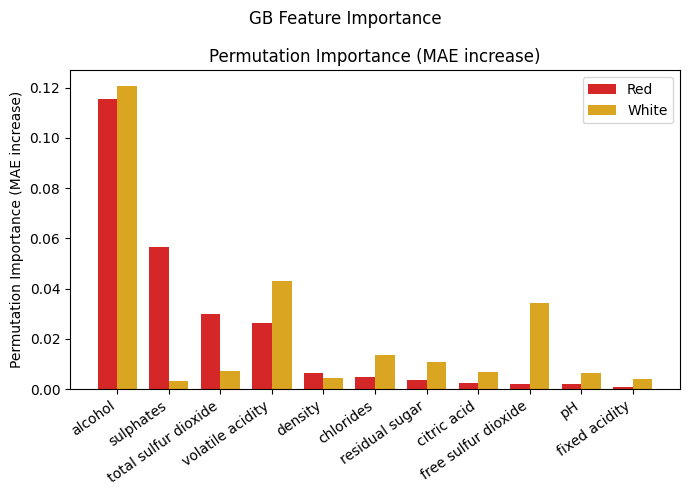

In [ ]:
compare_tables('GB Feature Importance',importance_df,white_importance_df,'Feature',['Permutation Importance (MAE increase)'])

### 8.5.6 Supplementary Exploratory XGBoost Cross-Check
XGBoost uses approximately matched settings from the sklearn boosting search, not an equivalent implementation. min_child_weight constrains Hessian sums and is not a general substitute for min_samples_leaf.

Rounds are selected using a validation slice from the full training dataset before CV. Thus the later CV validation labels have influenced selection; its CV score is exploratory, not independent evaluation of the selection procedure. The test set is not used for early stopping. XGBoost remains separate from the six-method main comparison.

If XGBoost is unavailable in Colab, run `%pip install xgboost` in a separate code cell, then rerun this section. The code prints the installed version.

#### Red Wine — Calculations

In [ ]:
with capture_output() as _individual_output:
    try:
        from xgboost import XGBRegressor
        import xgboost
        XGB_AVAILABLE = True
        print("xgboost version:", xgboost.__version__)
    except Exception as exc:  # ImportError, or XGBoostError when the OpenMP runtime is missing
        XGB_AVAILABLE = False
        print("xgboost could not be loaded - skipping this cross-check.")
        print("Reason:", str(exc).splitlines()[0] if str(exc).strip() else type(exc).__name__)

    if XGB_AVAILABLE:
        from sklearn.model_selection import train_test_split, cross_validate
        from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

        bp = gb_grid.best_params_
        xgb_params = dict(
            learning_rate=bp["learning_rate"],
            max_depth=bp["max_depth"],
            subsample=bp["subsample"],
            min_child_weight=bp["min_samples_leaf"],
            reg_lambda=1.0,
            objective="reg:squarederror",
            random_state=42,
            n_jobs=-1,
        )

        # 1) early stopping on a validation slice of the training set to choose the number of rounds
        X_fit, X_val, y_fit, y_val = train_test_split(
            X_train, y_train, test_size=0.15, random_state=42
        )
        xgb_es = XGBRegressor(n_estimators=3000, early_stopping_rounds=50, eval_metric="mae", **xgb_params)
        xgb_es.fit(X_fit, y_fit, eval_set=[(X_val, y_val)], verbose=False)
        best_rounds = int(xgb_es.best_iteration) + 1
        print(f"Early stopping chose {best_rounds} rounds (validation MAE {xgb_es.best_score:.4f})")

        # 2) cross-validate the fixed-round configuration with the shared 5-fold CV
        xgb_model = XGBRegressor(n_estimators=best_rounds, **xgb_params)
        xgb_scores = cross_validate(
            xgb_model, X_train, y_train, cv=cv,
            scoring={"mae": "neg_mean_absolute_error", "r2": "r2"},
            return_train_score=True, n_jobs=1
        )

        # 3) refit on the full training set and evaluate on the test set
        xgb_model.fit(X_train, y_train)
        y_pred_xgb = xgb_model.predict(X_test)

        xgb_vs_gb = pd.DataFrame([
            {
                "Model": "Tuned Gradient Boosting (sklearn)",
                "Stages": bp["n_estimators"],
                "CV MAE": tuned_gb_cv_mae,
                "CV R2": gb_grid.cv_results_["mean_test_r2"][gb_grid.best_index_],
                "Train R2": final_gb_train_r2,
                "Test MAE": final_gb_mae,
                "Test RMSE": final_gb_rmse,
                "Test R2": final_gb_r2,
            },
            {
                "Model": "XGBoost (approximately matched settings; exploratory CV)",
                "Stages": best_rounds,
                "CV MAE": -xgb_scores["test_mae"].mean(),
                "CV R2": xgb_scores["test_r2"].mean(),
                "Train R2": r2_score(y_train, xgb_model.predict(X_train)),
                "Test MAE": mean_absolute_error(y_test, y_pred_xgb),
                "Test RMSE": np.sqrt(mean_squared_error(y_test, y_pred_xgb)),
                "Test R2": r2_score(y_test, y_pred_xgb),
            },
        ])

        print("\nscikit-learn Gradient Boosting vs XGBoost:")
        display(xgb_vs_gb.round(4))

plt.close("all")

#### White Wine — Calculations

In [ ]:
with capture_output() as _individual_output:
    try:
        from xgboost import XGBRegressor
        import xgboost
        white_XGB_AVAILABLE = True
        print("xgboost version:", xgboost.__version__)
    except Exception as exc:  # ImportError, or XGBoostError when the OpenMP runtime is missing
        white_XGB_AVAILABLE = False
        print("xgboost could not be loaded - skipping this cross-check.")
        print("Reason:", str(exc).splitlines()[0] if str(exc).strip() else type(exc).__name__)

    if white_XGB_AVAILABLE:
        from sklearn.model_selection import train_test_split, cross_validate
        from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

        white_bp = white_gb_grid.best_params_
        white_xgb_params = dict(
            learning_rate=white_bp["learning_rate"],
            max_depth=white_bp["max_depth"],
            subsample=white_bp["subsample"],
            min_child_weight=white_bp["min_samples_leaf"],
            reg_lambda=1.0,
            objective="reg:squarederror",
            random_state=42,
            n_jobs=-1,
        )

        # 1) early stopping on a validation slice of the training set to choose the number of rounds
        white_X_fit, white_X_val, white_y_fit, white_y_val = train_test_split(
            white_X_train, white_y_train, test_size=0.15, random_state=42
        )
        white_xgb_es = XGBRegressor(n_estimators=3000, early_stopping_rounds=50, eval_metric="mae", **white_xgb_params)
        white_xgb_es.fit(white_X_fit, white_y_fit, eval_set=[(white_X_val, white_y_val)], verbose=False)
        white_best_rounds = int(white_xgb_es.best_iteration) + 1
        print(f"Early stopping chose {white_best_rounds} rounds (validation MAE {white_xgb_es.best_score:.4f})")

        # 2) cross-validate the fixed-round configuration with the shared 5-fold CV
        white_xgb_model = XGBRegressor(n_estimators=white_best_rounds, **white_xgb_params)
        white_xgb_scores = cross_validate(
            white_xgb_model, white_X_train, white_y_train, cv=white_cv,
            scoring={"mae": "neg_mean_absolute_error", "r2": "r2"},
            return_train_score=True, n_jobs=1
        )

        # 3) refit on the full training set and evaluate on the test set
        white_xgb_model.fit(white_X_train, white_y_train)
        white_y_pred_xgb = white_xgb_model.predict(white_X_test)

        white_xgb_vs_gb = pd.DataFrame([
            {
                "Model": "Tuned Gradient Boosting (sklearn)",
                "Stages": white_bp["n_estimators"],
                "CV MAE": white_tuned_gb_cv_mae,
                "CV R2": white_gb_grid.cv_results_["mean_test_r2"][white_gb_grid.best_index_],
                "Train R2": white_final_gb_train_r2,
                "Test MAE": white_final_gb_mae,
                "Test RMSE": white_final_gb_rmse,
                "Test R2": white_final_gb_r2,
            },
            {
                "Model": "XGBoost (approximately matched settings; exploratory CV)",
                "Stages": white_best_rounds,
                "CV MAE": -white_xgb_scores["test_mae"].mean(),
                "CV R2": white_xgb_scores["test_r2"].mean(),
                "Train R2": r2_score(white_y_train, white_xgb_model.predict(white_X_train)),
                "Test MAE": mean_absolute_error(white_y_test, white_y_pred_xgb),
                "Test RMSE": np.sqrt(mean_squared_error(white_y_test, white_y_pred_xgb)),
                "Test R2": r2_score(white_y_test, white_y_pred_xgb),
            },
        ])

        print("\nscikit-learn Gradient Boosting vs XGBoost:")
        display(white_xgb_vs_gb.round(4))

plt.close("all")

#### Combined Results
Red and white results are displayed together. Different metrics have separate panels. Cross-dataset differences are descriptive; fold variation is not a significance test.

,Model,Stages,CV MAE,CV R2,Train R2,Test MAE,Test RMSE,Test R2,Dataset
0,Tuned Gradient Boosting (sklearn),600,0.4965,0.3805,0.6941,0.4901,0.6273,0.4134,Red
1,XGBoost (approximately matched settings; explo...,377,0.4964,0.3928,0.6219,0.4964,0.6320,0.4047,Red
2,Tuned Gradient Boosting (sklearn),600,0.5460,0.3736,0.5361,0.5482,0.7002,0.3820,White
3,XGBoost (approximately matched settings; explo...,488,0.5482,0.3710,0.5054,0.5521,0.7045,0.3744,White


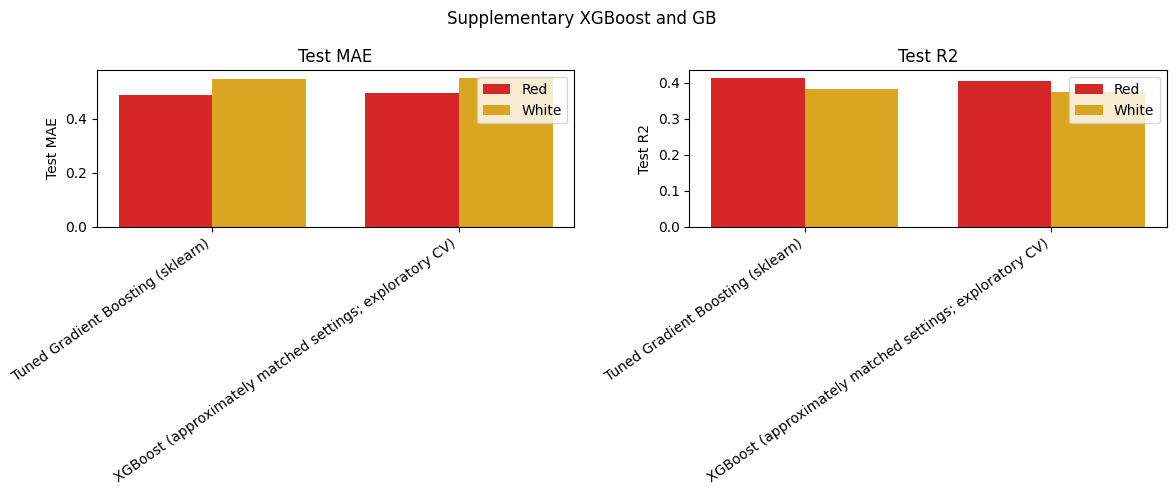

In [ ]:
if XGB_AVAILABLE and white_XGB_AVAILABLE:
    compare_tables('Supplementary XGBoost and GB',xgb_vs_gb,white_xgb_vs_gb,'Model',['Test MAE','Test R2'])

## 8.6 KNN Experiments and Tuning

For KNN we check 3 things:

1. How much feature scaling affects the result (since KNN is based on distance)
2. How the number of neighbours (k) changes the error
3. Grid search for k, weights and distance type

### 8.6.1 Effect of Feature Scaling

We compare KNN (k = 5) with no scaling, StandardScaler and MinMaxScaler. Other settings are the same.

#### Red Wine — Calculations

In [ ]:
with capture_output() as _individual_output:
    from sklearn.preprocessing import MinMaxScaler

    # 3 options to compare
    scaling_options = {
        "No Scaling": None,
        "StandardScaler": StandardScaler(),
        "MinMaxScaler": MinMaxScaler(),
    }

    scaling_results = []

    for name, scaler in scaling_options.items():
        steps = []
        if scaler is not None:
            steps.append(("scaler", scaler))
        steps.append(("knn", KNeighborsRegressor(n_neighbors=5)))
        model = Pipeline(steps)

        scores = cross_validate(
            model, X_train, y_train, cv=knn_cv,
            scoring={"mae": "neg_mean_absolute_error", "r2": "r2"},
            return_train_score=True
        )

        scaling_results.append({
            "Scaling": name,
            "Train R2": scores["train_r2"].mean(),
            "CV R2": scores["test_r2"].mean(),
            "CV MAE": -scores["test_mae"].mean(),
        })

    knn_scaling_df = pd.DataFrame(scaling_results)

    print("Red Wine KNN: Effect of Feature Scaling (k=5)")
    display(knn_scaling_df.round(4))

    # bar graph
    fig, ax = plt.subplots(figsize=(8, 4.5))
    bars = ax.bar(knn_scaling_df["Scaling"], knn_scaling_df["CV MAE"], color="tab:green")
    ax.bar_label(bars, fmt="%.4f", padding=3)
    ax.set_ylabel("Cross-Validation MAE")
    ax.set_title("Red Wine KNN: Effect of Feature Scaling (k=5)")
    ax.set_ylim(0, knn_scaling_df["CV MAE"].max() * 1.2)
    plt.tight_layout()
    plt.savefig(f"{KNN_FIG_DIR}/knn_scaling_effect.png", dpi=300, bbox_inches="tight")
    plt.show()

plt.close("all")

#### White Wine — Calculations

In [ ]:
with capture_output() as _individual_output:
    from sklearn.preprocessing import MinMaxScaler

    # 3 options to compare
    white_scaling_options = {
        "No Scaling": None,
        "StandardScaler": StandardScaler(),
        "MinMaxScaler": MinMaxScaler(),
    }

    white_scaling_results = []

    for white_name, white_scaler in white_scaling_options.items():
        white_steps = []
        if white_scaler is not None:
            white_steps.append(("scaler", white_scaler))
        white_steps.append(("knn", KNeighborsRegressor(n_neighbors=5)))
        white_model = Pipeline(white_steps)

        white_scores = cross_validate(
            white_model, white_X_train, white_y_train, cv=white_knn_cv,
            scoring={"mae": "neg_mean_absolute_error", "r2": "r2"},
            return_train_score=True
        )

        white_scaling_results.append({
            "Scaling": white_name,
            "Train R2": white_scores["train_r2"].mean(),
            "CV R2": white_scores["test_r2"].mean(),
            "CV MAE": -white_scores["test_mae"].mean(),
        })

    white_knn_scaling_df = pd.DataFrame(white_scaling_results)

    print("White Wine KNN: Effect of Feature Scaling (k=5)")
    display(white_knn_scaling_df.round(4))

    # bar graph
    white_fig, white_ax = plt.subplots(figsize=(8, 4.5))
    white_bars = white_ax.bar(white_knn_scaling_df["Scaling"], white_knn_scaling_df["CV MAE"], color="tab:green")
    white_ax.bar_label(white_bars, fmt="%.4f", padding=3)
    white_ax.set_ylabel("Cross-Validation MAE")
    white_ax.set_title("White Wine KNN: Effect of Feature Scaling (k=5)")
    white_ax.set_ylim(0, white_knn_scaling_df["CV MAE"].max() * 1.2)
    plt.tight_layout()
    plt.savefig(f"{white_KNN_FIG_DIR}/knn_scaling_effect.png", dpi=300, bbox_inches="tight")
    plt.show()

plt.close("all")

#### Combined Results
Red and white results are displayed together. Different metrics have separate panels. Cross-dataset differences are descriptive; fold variation is not a significance test.

,Scaling,Train R2,CV R2,CV MAE,Dataset
0,No Scaling,0.4035,0.0909,0.6041,Red
1,StandardScaler,0.5042,0.2484,0.5445,Red
2,MinMaxScaler,0.4973,0.2284,0.5570,Red
3,No Scaling,0.3943,0.0856,0.6636,White
4,StandardScaler,0.5254,0.2789,0.5777,White
5,MinMaxScaler,0.5104,0.2630,0.5838,White


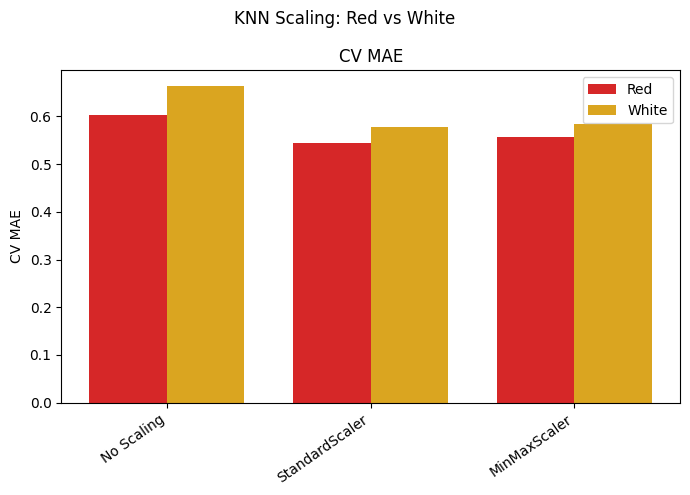

In [ ]:
compare_tables('KNN Scaling: Red vs White',knn_scaling_df,white_knn_scaling_df,'Scaling',['CV MAE'])

### 8.6.2 Number of Neighbours (k) vs Error

We investigate how the number of neighbours affects KNN performance on red and white wine. We test k from 1 to 50 using StandardScaler and Euclidean distance.

Two weighting methods are compared:

- **Uniform:** all neighbours contribute equally.
- **Distance:** closer neighbours contribute more to the prediction.

Small k can make predictions sensitive to individual observations, while large k can smooth away useful local patterns.

The left plot compares red and white wine using uniform weights; the right plot uses distance weights. Each curve shows mean five-fold cross-validation MAE on the training set. Lower MAE is better, and the marked points identify the best k within the tested range for each dataset and weighting method.

Note: When we use distance weights, the train R2 always become 1.0. This is because each training wine is the closest neighbour of itself (distance is 0). So it is not overfitting, and we only check the CV and test scores for this model.

Calculating Red Wine KNN results...
Red Wine completed.
Calculating White Wine KNN results...
White Wine completed.

Best k by dataset and weighting method:


,Dataset,Weights,k,Train MAE,CV MAE,CV MAE SD,CV R2
0,Red,distance,9,-0.0000,0.5190,0.0260,0.3274
1,Red,uniform,26,0.5119,0.5285,0.0242,0.3415
2,White,distance,24,-0.0000,0.5566,0.0102,0.3446
3,White,uniform,24,0.5428,0.5657,0.0112,0.3301


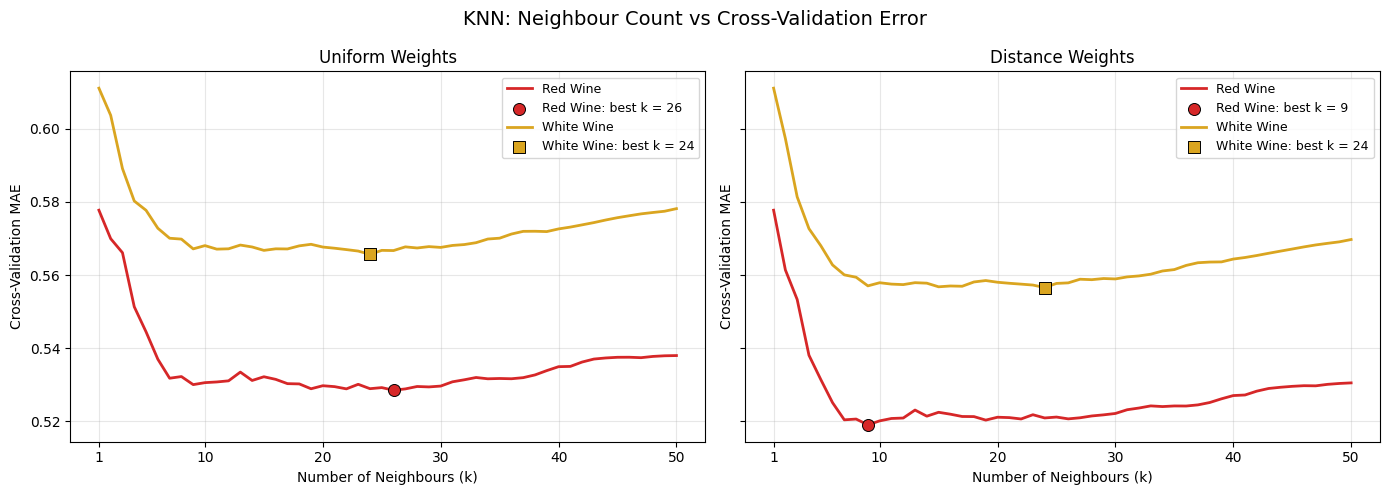

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsRegressor

# Uses the training data and CV objects defined earlier.
k_values = list(range(1, 51))

red_results = []
white_results = []

# --------------------------------------------------
# 1. Calculate red- and white-wine results
# --------------------------------------------------
for wine, X_data, y_data, cv_strategy, results in [
    ("Red", X_train, y_train, knn_cv, red_results),
    (
        "White",
        white_X_train,
        white_y_train,
        white_knn_cv,
        white_results
    )
]:
    print(f"Calculating {wine} Wine KNN results...")

    for weights in ["uniform", "distance"]:
        for k in k_values:
            model = Pipeline([
                ("scaler", StandardScaler()),
                ("knn", KNeighborsRegressor(
                    n_neighbors=k,
                    weights=weights,
                    p=2  # Euclidean distance
                ))
            ])

            scores = cross_validate(
                model,
                X_data,
                y_data,
                cv=cv_strategy,
                scoring={
                    "mae": "neg_mean_absolute_error",
                    "r2": "r2"
                },
                return_train_score=True,
                n_jobs=-1,
                error_score="raise"
            )

            results.append({
                "Weights": weights,
                "k": k,
                "Train MAE": -scores["train_mae"].mean(),
                "CV MAE": -scores["test_mae"].mean(),
                "CV MAE SD": scores["test_mae"].std(),
                "Train R2": scores["train_r2"].mean(),
                "CV R2": scores["test_r2"].mean()
            })

    print(f"{wine} Wine completed.")

# Preserve the variable names used elsewhere.
knn_k_df = pd.DataFrame(red_results)
white_knn_k_df = pd.DataFrame(white_results)

# --------------------------------------------------
# 2. Show the best k for each dataset and weight type
# --------------------------------------------------
best_k_rows = knn_k_df.loc[
    knn_k_df.groupby("Weights")["CV MAE"].idxmin()
].copy()

white_best_k_rows = white_knn_k_df.loc[
    white_knn_k_df.groupby("Weights")["CV MAE"].idxmin()
].copy()

best_k_rows.insert(0, "Dataset", "Red")
white_best_k_rows.insert(0, "Dataset", "White")

best_k_comparison = pd.concat(
    [best_k_rows, white_best_k_rows],
    ignore_index=True
)

print("\nBest k by dataset and weighting method:")
display(
    best_k_comparison[
        [
            "Dataset",
            "Weights",
            "k",
            "Train MAE",
            "CV MAE",
            "CV MAE SD",
            "CV R2"
        ]
    ].round(4)
)

# --------------------------------------------------
# 3. Two-column comparison using line plots
# --------------------------------------------------
fig, axes = plt.subplots(
    1, 2,
    figsize=(14, 5),
    sharex=True,
    sharey=True
)

for ax, weights in zip(axes, ["uniform", "distance"]):
    for wine, table, color, marker in [
        ("Red Wine", knn_k_df, "tab:red", "o"),
        ("White Wine", white_knn_k_df, "goldenrod", "s")
    ]:
        part = (
            table[table["Weights"] == weights]
            .sort_values("k")
        )

        ax.plot(
            part["k"],
            part["CV MAE"],
            color=color,
            linewidth=2,
            label=wine
        )

        # Mark the k with the lowest CV MAE.
        best = part.loc[part["CV MAE"].idxmin()]

        ax.scatter(
            best["k"],
            best["CV MAE"],
            color=color,
            marker=marker,
            s=75,
            edgecolors="black",
            linewidths=0.7,
            zorder=5,
            label=f"{wine}: best k = {int(best['k'])}"
        )

    ax.set_title(f"{weights.capitalize()} Weights")
    ax.set_xlabel("Number of Neighbours (k)")
    ax.set_ylabel("Cross-Validation MAE")
    ax.set_xticks([1, 10, 20, 30, 40, 50])
    ax.grid(alpha=0.3)
    ax.legend(fontsize=9)

fig.suptitle(
    "KNN: Neighbour Count vs Cross-Validation Error",
    fontsize=14
)

plt.tight_layout()

plt.savefig(
    "knn_red_white_neighbour_curves.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### 8.6.3 KNN Hyperparameter Grid Search

Same as the Random Forest and Gradient Boosting grid search, we use GridSearchCV on the training set only, with the same 5 fold CV and refit="mae".

- n_neighbors: number of neighbours
- weights: uniform or distance
- p: distance type (1 = Manhattan, 2 = Euclidean)

#### Red Wine — Calculations

In [ ]:
with capture_output() as _individual_output:
    from sklearn.model_selection import GridSearchCV

    knn_param_grid = {
        "knn__n_neighbors": [3, 5, 7, 9, 11, 15, 20, 25, 30, 40],
        "knn__weights": ["uniform", "distance"],
        "knn__p": [1, 2],
    }

    knn_grid = GridSearchCV(
        estimator=Pipeline([("scaler", StandardScaler()), ("knn", KNeighborsRegressor())]),
        param_grid=knn_param_grid,
        scoring={"mae": "neg_mean_absolute_error", "r2": "r2"},
        refit="mae",
        cv=knn_cv,
        n_jobs=-1,
        return_train_score=True
    )

    knn_grid.fit(X_train, y_train)

    print("Red Wine KNN tuning completed!")
    print("Best Parameters:", knn_grid.best_params_)
    print(f"Best CV MAE: {-knn_grid.best_score_:.4f}")

    # results table
    knn_tuning_df = pd.DataFrame(knn_grid.cv_results_)[[
        "param_knn__n_neighbors", "param_knn__weights", "param_knn__p",
        "mean_train_r2", "mean_test_r2", "std_test_r2", "mean_test_mae"
    ]].copy()

    knn_tuning_df["CV MAE"] = -knn_tuning_df["mean_test_mae"]
    knn_tuning_df = knn_tuning_df.rename(columns={
        "param_knn__n_neighbors": "k",
        "param_knn__weights": "Weights",
        "param_knn__p": "p (1=Manhattan, 2=Euclidean)",
        "mean_train_r2": "Train R2",
        "mean_test_r2": "CV R2",
        "std_test_r2": "CV R2 Std",
    }).drop(columns=["mean_test_mae"])

    knn_tuning_df = knn_tuning_df.sort_values(by="CV MAE").reset_index(drop=True)

    print(f"\nRed Wine KNN Hyperparameter Results (top 10 of {len(knn_tuning_df)}):")
    display(knn_tuning_df.head(10).round(4))

    # average effect of each setting
    print("\nMean CV MAE by hyperparameter value (lower is better):")
    for col in ["Weights", "p (1=Manhattan, 2=Euclidean)"]:
        print(f"\n{col}:")
        print(knn_tuning_df.groupby(col)["CV MAE"].mean().round(4).to_string())

    # baseline vs tuned
    baseline_knn_cv_mae = knn_cv_row["CV MAE"]
    tuned_knn_cv_mae = -knn_grid.best_score_

    print("\nRed Wine KNN CV Comparison")
    print("--------------------------")
    print(f"Baseline CV MAE (k=5): {baseline_knn_cv_mae:.4f}")
    print(f"Tuned CV MAE:          {tuned_knn_cv_mae:.4f}")
    print(f"MAE improvement:       {baseline_knn_cv_mae - tuned_knn_cv_mae:.4f}")
    print(f"(Fold-to-fold std of the baseline CV MAE was {knn_cv_mae_std:.4f})")

plt.close("all")

#### White Wine — Calculations

In [ ]:
with capture_output() as _individual_output:
    from sklearn.model_selection import GridSearchCV

    white_knn_param_grid = {
        "knn__n_neighbors": [3, 5, 7, 9, 11, 15, 20, 25, 30, 40],
        "knn__weights": ["uniform", "distance"],
        "knn__p": [1, 2],
    }

    white_knn_grid = GridSearchCV(
        estimator=Pipeline([("scaler", StandardScaler()), ("knn", KNeighborsRegressor())]),
        param_grid=white_knn_param_grid,
        scoring={"mae": "neg_mean_absolute_error", "r2": "r2"},
        refit="mae",
        cv=white_knn_cv,
        n_jobs=-1,
        return_train_score=True
    )

    white_knn_grid.fit(white_X_train, white_y_train)

    print("White Wine KNN tuning completed!")
    print("Best Parameters:", white_knn_grid.best_params_)
    print(f"Best CV MAE: {-white_knn_grid.best_score_:.4f}")

    # results table
    white_knn_tuning_df = pd.DataFrame(white_knn_grid.cv_results_)[[
        "param_knn__n_neighbors", "param_knn__weights", "param_knn__p",
        "mean_train_r2", "mean_test_r2", "std_test_r2", "mean_test_mae"
    ]].copy()

    white_knn_tuning_df["CV MAE"] = -white_knn_tuning_df["mean_test_mae"]
    white_knn_tuning_df = white_knn_tuning_df.rename(columns={
        "param_knn__n_neighbors": "k",
        "param_knn__weights": "Weights",
        "param_knn__p": "p (1=Manhattan, 2=Euclidean)",
        "mean_train_r2": "Train R2",
        "mean_test_r2": "CV R2",
        "std_test_r2": "CV R2 Std",
    }).drop(columns=["mean_test_mae"])

    white_knn_tuning_df = white_knn_tuning_df.sort_values(by="CV MAE").reset_index(drop=True)

    print(f"\nWhite Wine KNN Hyperparameter Results (top 10 of {len(white_knn_tuning_df)}):")
    display(white_knn_tuning_df.head(10).round(4))

    # average effect of each setting
    print("\nMean CV MAE by hyperparameter value (lower is better):")
    for white_col in ["Weights", "p (1=Manhattan, 2=Euclidean)"]:
        print(f"\n{white_col}:")
        print(white_knn_tuning_df.groupby(white_col)["CV MAE"].mean().round(4).to_string())

    # baseline vs tuned
    white_baseline_knn_cv_mae = white_knn_cv_row["CV MAE"]
    white_tuned_knn_cv_mae = -white_knn_grid.best_score_

    print("\nWhite Wine KNN CV Comparison")
    print("--------------------------")
    print(f"Baseline CV MAE (k=5): {white_baseline_knn_cv_mae:.4f}")
    print(f"Tuned CV MAE:          {white_tuned_knn_cv_mae:.4f}")
    print(f"MAE improvement:       {white_baseline_knn_cv_mae - white_tuned_knn_cv_mae:.4f}")
    print(f"(Fold-to-fold std of the baseline CV MAE was {white_knn_cv_mae_std:.4f})")

plt.close("all")

#### Combined Results
Red and white results are displayed together. Different metrics have separate panels. Cross-dataset differences are descriptive; fold variation is not a significance test.

,Dataset,Best k,Weights,Distance,CV MAE
0,Red,11,distance,Manhattan,0.5158
1,White,15,distance,Manhattan,0.5536


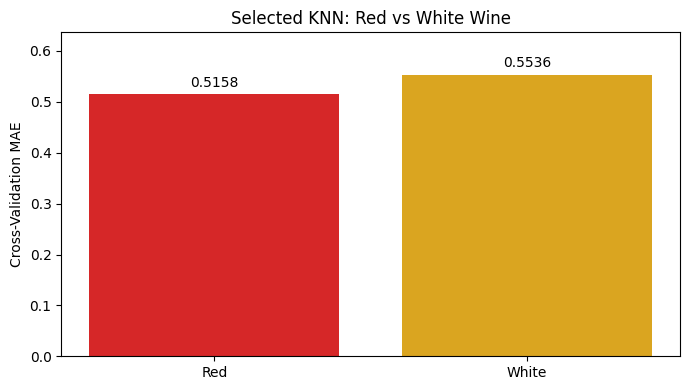

In [ ]:
from IPython.display import display

summary = pd.DataFrame([
    {
        "Dataset": wine,
        "Best k": search.best_params_["knn__n_neighbors"],
        "Weights": search.best_params_["knn__weights"],
        "Distance": (
            "Manhattan"
            if search.best_params_["knn__p"] == 1
            else "Euclidean"
        ),
        "CV MAE": -search.best_score_
    }
    for wine, search in [
        ("Red", knn_grid),
        ("White", white_knn_grid)
    ]
])

display(summary.round(4))

fig, ax = plt.subplots(figsize=(7, 4))

bars = ax.bar(
    summary["Dataset"],
    summary["CV MAE"],
    color=["tab:red", "goldenrod"]
)

ax.bar_label(bars, fmt="%.4f", padding=3)
ax.set_title("Selected KNN: Red vs White Wine")
ax.set_ylabel("Cross-Validation MAE")
ax.set_ylim(0, summary["CV MAE"].max() * 1.15)

plt.tight_layout()
plt.show()

### 8.6.4 Tuned KNN on the Test Set and Marginal Cases

KNN predicts using the average of the neighbours. Most wines in the data are quality 5 or 6, so even for a rare wine (quality 3, 4 or 8) most of its neighbours will still be 5 or 6. Because of this we think KNN will push these wines towards the middle. The Random Forest values are from Section 5.

We examine prediction errors at each quality score, including rare low and high scores. Predictions may move towards common quality levels when nearby training observations have typical scores. This is a possible explanation, rather than a direct analysis of neighbour composition.

#### Red Wine — Calculations

In [ ]:
with capture_output() as _individual_output:
    # best model from grid search
    final_knn = knn_grid.best_estimator_

    y_pred_final_knn = final_knn.predict(X_test)
    final_knn_train_r2 = r2_score(y_train, final_knn.predict(X_train))
    final_knn_mae = mean_absolute_error(y_test, y_pred_final_knn)
    final_knn_rmse = np.sqrt(mean_squared_error(y_test, y_pred_final_knn))
    final_knn_r2 = r2_score(y_test, y_pred_final_knn)

    # rows for the final comparison table
    knn_row = {"Model": "KNN", "Train R2": knn_train_r2,
               "Test MAE": knn_mae, "Test RMSE": knn_rmse, "Test R2": knn_r2}
    tuned_knn_row = {"Model": "Tuned KNN", "Train R2": final_knn_train_r2,
                     "Test MAE": final_knn_mae, "Test RMSE": final_knn_rmse, "Test R2": final_knn_r2}

    print("Red Wine KNN Test Results")
    display(pd.DataFrame([knn_row, tuned_knn_row]).round(4))
    if final_knn.named_steps["knn"].weights == "distance":
        print("Note: Train R2 is ~1.0 because of distance weighting (each training wine is its own nearest neighbour).")

    # error for each quality score
    knn_error_df = pd.DataFrame({"Actual Quality": y_test.values, "Predicted Quality": y_pred_final_knn})
    knn_error_df["Absolute Error"] = (knn_error_df["Actual Quality"] - knn_error_df["Predicted Quality"]).abs()

    knn_error_by_quality = knn_error_df.groupby("Actual Quality").agg(
        Sample_Count=("Absolute Error", "size"),
        KNN_MAE=("Absolute Error", "mean"),
        Mean_Prediction=("Predicted Quality", "mean")
    ).reset_index()

    # random forest values
    rf_error_by_quality_ref = pd.DataFrame({"Actual Quality": y_test.to_numpy(),
        "Error": np.abs(y_test.to_numpy() - rf_model.predict(X_test))}).groupby("Actual Quality")["Error"].mean()
    knn_error_by_quality["RF_MAE"] = knn_error_by_quality["Actual Quality"].map(rf_error_by_quality_ref)

    print("\nTuned KNN error by actual quality score:")
    display(knn_error_by_quality.round(4))

    # graph: knn vs rf
    fig, ax = plt.subplots(figsize=(9, 5))
    x = np.arange(len(knn_error_by_quality))
    width = 0.38
    bars_knn = ax.bar(x - width / 2, knn_error_by_quality["KNN_MAE"], width, label="Tuned KNN", color="tab:green")
    bars_rf = ax.bar(x + width / 2, knn_error_by_quality["RF_MAE"], width, label="Random Forest (Section 5)", color="tab:blue")
    ax.bar_label(bars_knn, fmt="%.3f", padding=3, fontsize=8)
    ax.bar_label(bars_rf, fmt="%.3f", padding=3, fontsize=8)
    ax.set_xticks(x)
    ax.set_xticklabels(knn_error_by_quality["Actual Quality"].astype(str))
    ax.set_xlabel("Actual Wine Quality Score")
    ax.set_ylabel("Mean Absolute Error")
    ax.set_title("Prediction Error by Quality Score: KNN vs Random Forest")
    ax.legend()
    plt.tight_layout()
    plt.savefig(f"{KNN_FIG_DIR}/knn_error_by_quality.png", dpi=300, bbox_inches="tight")
    plt.show()

plt.close("all")

#### White Wine — Calculations

In [ ]:
with capture_output() as _individual_output:
    # best model from grid search
    white_final_knn = white_knn_grid.best_estimator_

    white_y_pred_final_knn = white_final_knn.predict(white_X_test)
    white_final_knn_train_r2 = r2_score(white_y_train, white_final_knn.predict(white_X_train))
    white_final_knn_mae = mean_absolute_error(white_y_test, white_y_pred_final_knn)
    white_final_knn_rmse = np.sqrt(mean_squared_error(white_y_test, white_y_pred_final_knn))
    white_final_knn_r2 = r2_score(white_y_test, white_y_pred_final_knn)

    # rows for the final comparison table
    white_knn_row = {"Model": "KNN", "Train R2": white_knn_train_r2,
               "Test MAE": white_knn_mae, "Test RMSE": white_knn_rmse, "Test R2": white_knn_r2}
    white_tuned_knn_row = {"Model": "Tuned KNN", "Train R2": white_final_knn_train_r2,
                     "Test MAE": white_final_knn_mae, "Test RMSE": white_final_knn_rmse, "Test R2": white_final_knn_r2}

    print("White Wine KNN Test Results")
    display(pd.DataFrame([white_knn_row, white_tuned_knn_row]).round(4))
    if white_final_knn.named_steps["knn"].weights == "distance":
        print("Note: Train R2 is ~1.0 because of distance weighting (each training wine is its own nearest neighbour).")

    # error for each quality score
    white_knn_error_df = pd.DataFrame({"Actual Quality": white_y_test.values, "Predicted Quality": white_y_pred_final_knn})
    white_knn_error_df["Absolute Error"] = (white_knn_error_df["Actual Quality"] - white_knn_error_df["Predicted Quality"]).abs()

    white_knn_error_by_quality = white_knn_error_df.groupby("Actual Quality").agg(
        Sample_Count=("Absolute Error", "size"),
        KNN_MAE=("Absolute Error", "mean"),
        Mean_Prediction=("Predicted Quality", "mean")
    ).reset_index()

    # random forest values
    white_rf_error_by_quality_ref = pd.DataFrame({"Actual Quality": white_y_test.to_numpy(),
        "Error": np.abs(white_y_test.to_numpy() - white_rf_model.predict(white_X_test))}).groupby("Actual Quality")["Error"].mean()
    white_knn_error_by_quality["RF_MAE"] = white_knn_error_by_quality["Actual Quality"].map(white_rf_error_by_quality_ref)

    print("\nTuned KNN error by actual quality score:")
    display(white_knn_error_by_quality.round(4))

    # graph: knn vs rf
    white_fig, white_ax = plt.subplots(figsize=(9, 5))
    white_x = np.arange(len(white_knn_error_by_quality))
    white_width = 0.38
    white_bars_knn = white_ax.bar(white_x - white_width / 2, white_knn_error_by_quality["KNN_MAE"], white_width, label="Tuned KNN", color="tab:green")
    white_bars_rf = white_ax.bar(white_x + white_width / 2, white_knn_error_by_quality["RF_MAE"], white_width, label="Random Forest (Section 5)", color="tab:blue")
    white_ax.bar_label(white_bars_knn, fmt="%.3f", padding=3, fontsize=8)
    white_ax.bar_label(white_bars_rf, fmt="%.3f", padding=3, fontsize=8)
    white_ax.set_xticks(white_x)
    white_ax.set_xticklabels(white_knn_error_by_quality["Actual Quality"].astype(str))
    white_ax.set_xlabel("Actual Wine Quality Score")
    white_ax.set_ylabel("Mean Absolute Error")
    white_ax.set_title("Prediction Error by Quality Score: KNN vs Random Forest")
    white_ax.legend()
    plt.tight_layout()
    plt.savefig(f"{white_KNN_FIG_DIR}/knn_error_by_quality.png", dpi=300, bbox_inches="tight")
    plt.show()

plt.close("all")

In [ ]:
knn_test_summary = pd.DataFrame([
    {"Dataset": "Red", **tuned_knn_row},
    {"Dataset": "White", **white_tuned_knn_row}
])

display(
    knn_test_summary[
        ["Dataset", "Train R2", "Test MAE",
         "Test RMSE", "Test R2"]
    ].round(4)
)

,Dataset,Train R2,Test MAE,Test RMSE,Test R2
0,Red,1.0,0.5092,0.6651,0.3406
1,White,1.0,0.5563,0.7215,0.3438


#### Combined Results
Red and white results are displayed together. Different metrics have separate panels. Cross-dataset differences are descriptive; fold variation is not a significance test.

,Actual Quality,Sample_Count,KNN_MAE,Mean_Prediction,RF_MAE,Dataset
0,3,2,2.3491,5.3491,2.0850,Red
1,4,11,1.2209,5.2209,1.0600,Red
2,5,116,0.4257,5.4183,0.3703,Red
3,6,107,0.3851,5.8147,0.4044,Red
4,7,33,0.7505,6.2685,0.7173,Red
5,8,3,1.6787,6.3213,1.3233,Red
6,3,4,2.6161,5.6161,2.6000,White
7,4,31,1.4938,5.4938,1.1065,White
8,5,235,0.5590,5.5513,0.5422,White
9,6,358,0.3458,5.9255,0.3516,White


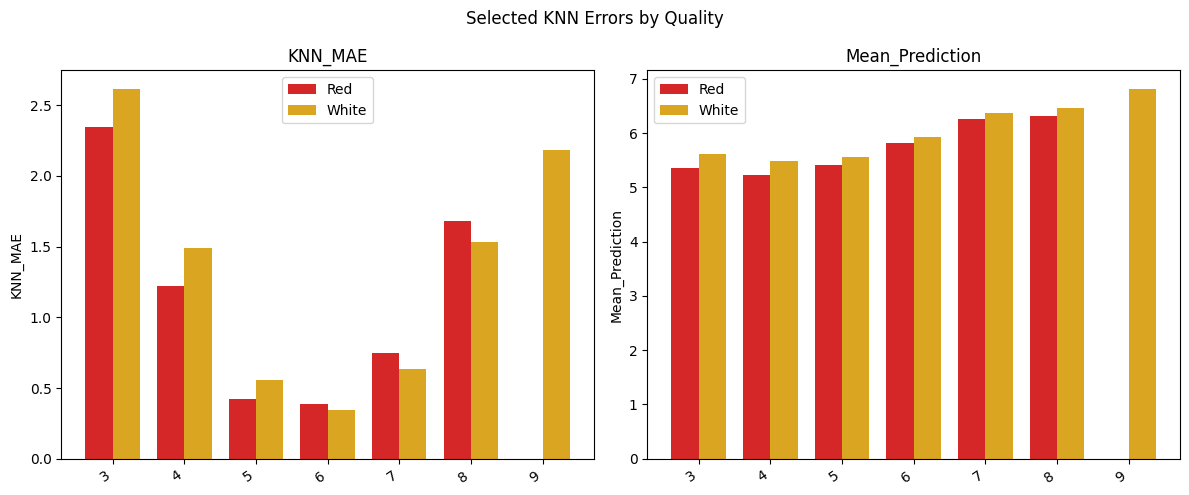

In [ ]:
compare_tables('Selected KNN Errors by Quality',knn_error_by_quality,white_knn_error_by_quality,'Actual Quality',['KNN_MAE','Mean_Prediction'])

## 9. Complete Model Comparison
Compare six baseline methods and four CV-selected configurations (RF, MLP, GB and KNN) for each wine dataset, giving 20 rows in total. Refit each selected MLP architecture on its full training set and calculate all comparison metrics directly from fitted models. “Selected” means selected by training-set CV MAE, not guaranteed to outperform the baseline on the test set. Use MAE as the main error measure and RMSE/R² for complementary interpretation. XGBoost remains in its supplementary section because its selection procedure differs. Test comparisons are exploratory, and these results do not establish statistical significance or causal relationships.

,Dataset,Model,Train R2,Test MAE,Test RMSE,Test R2
0,Red,Linear Regression,0.3599,0.5066,0.6523,0.3657
1,Red,Decision Tree,1.0000,0.5919,0.8849,-0.1673
2,Red,Random Forest,0.9144,0.4768,0.6233,0.4209
3,Red,MLP,0.5111,0.5133,0.6757,0.3193
4,Red,Gradient Boosting,0.6414,0.4963,0.6343,0.4003
5,Red,KNN,0.5058,0.5265,0.6871,0.2963
6,Red,Selected RF,0.8130,0.4846,0.6316,0.4054
7,Red,Selected MLP,0.5140,0.5044,0.6638,0.3432
8,Red,Selected GB,0.6941,0.4901,0.6273,0.4134
9,Red,Selected KNN,1.0000,0.5092,0.6651,0.3406


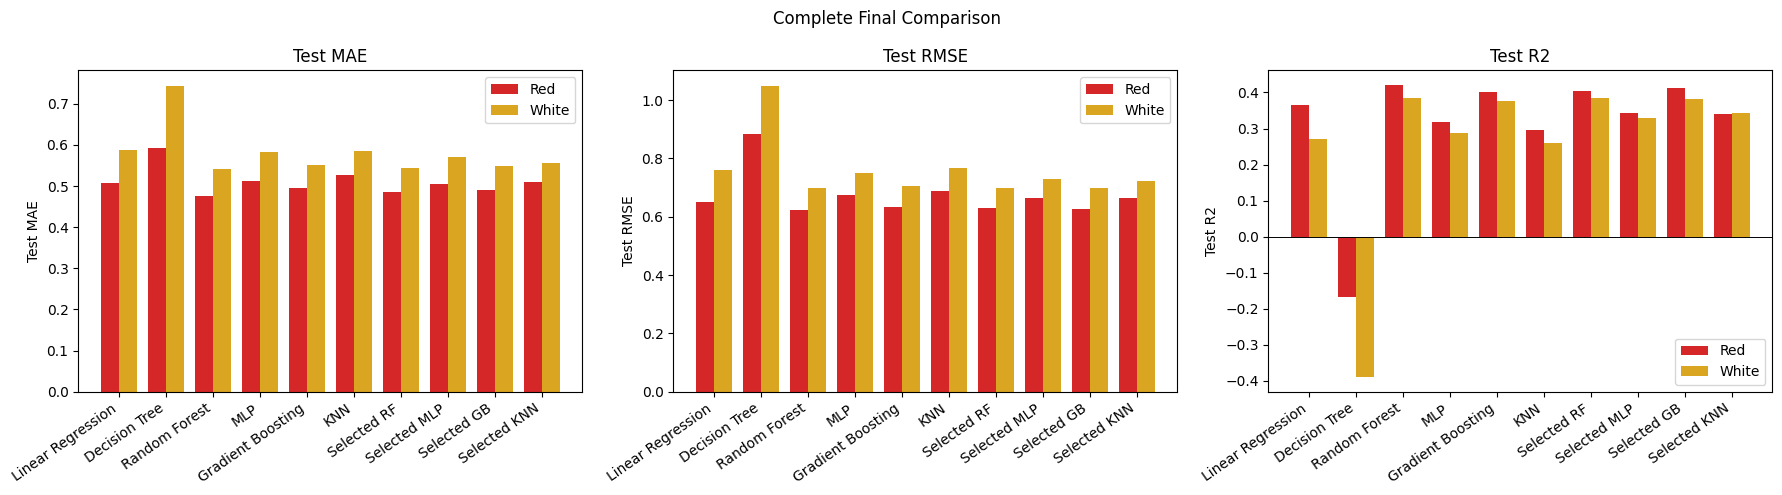

In [ ]:
red_final_mlp=clone(mlp_model).set_params(mlp__hidden_layer_sizes=best_architecture).fit(X_train,y_train)
white_final_mlp=clone(white_mlp_model).set_params(mlp__hidden_layer_sizes=white_best_architecture).fit(white_X_train,white_y_train)
red_models={'Linear Regression':lr_model,'Decision Tree':dt_model,'Random Forest':rf_model,
    'MLP':mlp_model,'Gradient Boosting':gb_model,'KNN':knn_model,'Selected RF':rf_grid.best_estimator_,
    'Selected MLP':red_final_mlp,'Selected GB':final_gb,'Selected KNN':final_knn}
white_models={'Linear Regression':white_lr_model,'Decision Tree':white_dt_model,'Random Forest':white_rf_model,
    'MLP':white_mlp_model,'Gradient Boosting':white_gb_model,'KNN':white_knn_model,'Selected RF':white_rf_grid.best_estimator_,
    'Selected MLP':white_final_mlp,'Selected GB':white_final_gb,'Selected KNN':white_final_knn}
complete_rows=[]
for wine,models,xa,xb,ya,yb in [('Red',red_models,X_train,X_test,y_train,y_test),
    ('White',white_models,white_X_train,white_X_test,white_y_train,white_y_test)]:
    for name,model in models.items():
        prediction=model.predict(xb)
        complete_rows.append({'Dataset':wine,'Model':name,'Train R2':r2_score(ya,model.predict(xa)),
            'Test MAE':mean_absolute_error(yb,prediction),'Test RMSE':np.sqrt(mean_squared_error(yb,prediction)),
            'Test R2':r2_score(yb,prediction)})
complete_results_df=pd.DataFrame(complete_rows)
assert len(complete_results_df)==20

compare_tables('Complete Final Comparison',complete_results_df[complete_results_df.Dataset=='Red'],
    complete_results_df[complete_results_df.Dataset=='White'],'Model',['Test MAE','Test RMSE','Test R2'])
complete_results_df.to_csv(comparison_folder/'complete_red_white_results.csv',index=False)